# import

In [148]:
import io
import missingno
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings('ignore')

# 1. Load and explore the dataset, visualizing the results of the exploration. Analyze the quality of the dataset and handle eventual quality issues.

In [149]:
raw_df = pd.read_csv('data.csv')

In [150]:
display(raw_df.head())

,ID,age,gender,bmi,children,smoker,region,status,work_sector,physical_activity,stress_level,sleep_quality,income (USD),charges (USD)
0,0,45.0,female,25.700,3,no,southwest,Single,Education,Lightly Active,6.9,Fair,44324.35,9101.79800
1,1,32.0,male,28.120,4,yes,northwest,Engaged,IT Support,Sedentary,6.9,Poor,102553.91,21472.47880
2,2,41.0,female,37.100,2,-,southwest,Single,Transportation,Very Active,5.9,Fair,18429.43,7371.77200
3,3,26.0,male,31.065,0,no,northwest,Single,Education,Sedentary,5.9,Fair,14888.09,2699.56835
4,4,23.0,female,34.960,3,no,northwest,Married,Hospitality,Sedentary,8.6,Good,15571.19,4466.62140


In [151]:
raw_df.shape

(3098, 14)

In [152]:
raw_df.describe()

,ID,age,bmi,children,stress_level,income (USD),charges (USD)
count,3098.000000,3098.000000,3067.000000,3098.000000,3098.000000,3098.000000,3075.000000
mean,1544.111685,39.093165,32.163444,1.118786,6.414526,62360.722112,13476.771230
std,891.919277,14.133351,99.325991,1.207859,1.721550,64646.475643,12080.919557
min,0.000000,-8.000000,-989.915959,-3.000000,0.000000,-126055.018185,1000.000000
25%,772.250000,27.000000,26.315000,0.000000,5.200000,20236.880000,4718.863800
50%,1544.500000,39.000000,30.495000,1.000000,6.400000,41783.988014,9644.252500
75%,2315.750000,51.000000,34.800000,2.000000,7.600000,83888.017500,17807.613070
max,3089.000000,88.336729,5424.864393,5.000000,10.000000,528054.020000,63770.428010


**Description of the datasets**


- **Number of observations**  
  > 3098 rows / samples

- **Number of variables per observation**  
  > 14 columns / features

- **Description of variables**  

  | Variable Name |                    Description                   |Data Type|
  |---------------|--------------------------------------------------|-------|
  | `ID`      | Unique identifier for each subject in the insurance database.| Int |
  | `Age`     | The age of the participant (in years) | Float |
  | `bmi`     |Body mass index (BMI) is a value derived from the mass (weight) and height of a person | Float |
  | `Gender`  | : Gender of the participant (M/F) (as physiological differences may affect insurance costs)| String |
  | `children`         |  The number of children the subject takes care of. | Int |
  | `region`         | Great geographic area region subdivision (’southwest’, ’southeast’, ’northwest’, ’northeast’)       | String |
  | `Status`         | Subject’s marital status                 | String |
  | `Work Sector`         | Working sector of the subject                | String |
  | `Physical Activity Level`         | Self-reported level of physical activity (’Sedentary’,’Lightly Active’, ’Moderately Active’, or ’Very Active’)      | String |
  | `Stress Level`         | A numerical score (1-10) indicating the subject’s perceived stress level      | Int |
  | `Physical Activity Level`         | Self-reported level of physical activity (’Sedentary’,’Lightly Active’, ’Moderately Active’, or ’Very Active’)      | String |
  | `Sleep Quality`         | Quality: Self-reported quality of sleep(’Poor’, ’Fair’, ’Good’, or ’Excellent’)      | String |
  | `income (USD)`         | Annual gross individual income, measured in U.S. dollars (USD)      | Float |
  | `charges (USD)`         | Annual medical insurance charges or claims, measured in USD      | Float |

In [153]:
df = raw_df

In [154]:
# Count of the duplicated values by marking all the duplicate values as TRUE.
df.duplicated(keep=False).value_counts()

False    3082
True       16
Name: count, dtype: int64

In [155]:
#Eliminating the duplicate values.
bool_series = df.duplicated(keep='first') #keep only the first instance of a duplicate row

print("DUPLICATES BEING REMOVED:")
print(df[bool_series])  # Show what will be removed

df = df[~bool_series]

DUPLICATES BEING REMOVED:
        ID   age  gender     bmi  children smoker     region   status  \
1285  1284  28.0    male  30.875         0     no  northwest   Single   
1674   322  42.0    male  34.100         0     no  southwest   Single   
1871  1782  33.0  female  26.695         0     no  northwest  Engaged   
2133  1930  54.0  female  28.880         2     no  northeast   Single   
2191  2186  52.0  female  30.780         1     no  northeast   Single   
2605  1127  55.0  female  25.365         3     no  northeast  Married   
2823   126  25.0  female  41.325         0     no  northeast  Married   
2964  2396  32.0    male  35.200         2     no  southwest  Engaged   

      work_sector  physical_activity  stress_level sleep_quality  \
1285  Hospitality          Sedentary           6.2          Poor   
1674    Education                NaN           6.8          Good   
1871       Retail          Sedentary           8.2          Poor   
2133       Retail  Moderately Active        

In [156]:
df


,ID,age,gender,bmi,children,smoker,region,status,work_sector,physical_activity,stress_level,sleep_quality,income (USD),charges (USD)
0,0,45.0,female,25.700,3,no,southwest,Single,Education,Lightly Active,6.9,Fair,44324.35,9101.79800
1,1,32.0,male,28.120,4,yes,northwest,Engaged,IT Support,Sedentary,6.9,Poor,102553.91,21472.47880
2,2,41.0,female,37.100,2,-,southwest,Single,Transportation,Very Active,5.9,Fair,18429.43,7371.77200
3,3,26.0,male,31.065,0,no,northwest,Single,Education,Sedentary,5.9,Fair,14888.09,2699.56835
4,4,23.0,female,34.960,3,no,northwest,Married,Hospitality,Sedentary,8.6,Good,15571.19,4466.62140
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3093,3085,54.0,male,34.210,2,yes,southeast,Married,Finance,Lightly Active,9.2,Poor,336130.93,44260.74990
3094,3086,18.0,female,31.350,4,no,northeast,Single,Retail,Sedentary,10.0,Poor,21624.45,4561.18850
3095,3087,39.0,female,23.870,5,no,southeast,Single,Transportation,Lightly Active,5.8,Good,36357.70,8582.30230
3096,3088,58.0,male,25.175,0,no,northeast,Single,Education,Lightly Active,4.7,Poor,69475.40,11931.12525


# 2. Prepare the dataset for a Linear Regression task that aims to build a "charge (USD)"predictive model.

## Missing Value

In [157]:
def plot_num_cols(df):
    # Select numeric columns
    numeric_cols = df.select_dtypes(include=[np.number]).columns

    # Create subplots - automatic layout
    n_cols = 4  # Fixed number of columns for better visualization
    n_rows = (len(numeric_cols) + n_cols - 1) // n_cols  # Calculate needed rows

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 3*n_rows))
    axes = axes.ravel()  # Flatten for easy iteration

    # Plot all numeric columns
    for i, col in enumerate(numeric_cols[1:]):
        df[col].plot(kind='hist', ax=axes[i])
        axes[i].set_title(col)
        axes[i].grid(True)

    # Hide empty subplots
    for j in range(len(numeric_cols[1:]), n_rows * n_cols):
        axes[j].set_visible(False)

    plt.tight_layout()
    plt.show()

In [158]:
# Percentage of missing values (mean of boolean mask)
df.isnull().sum()

ID                    0
age                   0
gender                0
bmi                  31
children              0
smoker                0
region                0
status                1
work_sector          36
physical_activity    78
stress_level          0
sleep_quality         0
income (USD)          0
charges (USD)        23
dtype: int64

ID                   0.00
age                  0.00
gender               0.00
bmi                  1.00
children             0.00
smoker               0.00
region               0.00
status               0.03
work_sector          1.17
physical_activity    2.52
stress_level         0.00
sleep_quality        0.00
income (USD)         0.00
charges (USD)        0.74
dtype: float64


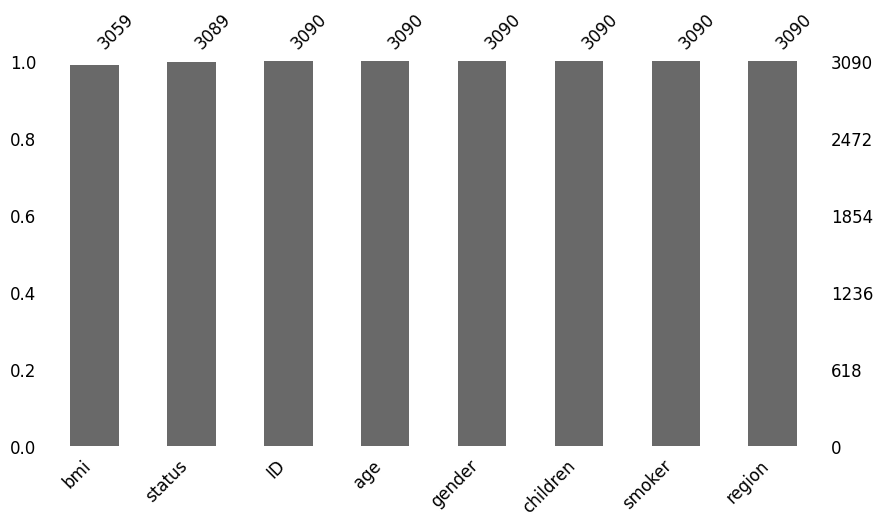

In [159]:
print(df.isnull().mean().round(4)*100)
missingno.bar(df.iloc[:,:8], sort="ascending", figsize=(10,5), fontsize=12);

In [160]:
df.columns.tolist()

['ID',
 'age',
 'gender',
 'bmi',
 'children',
 'smoker',
 'region',
 'status',
 'work_sector',
 'physical_activity',
 'stress_level',
 'sleep_quality',
 'income (USD)',
 'charges (USD)']

In [161]:
df_nn_col = [ #'ID',
 #'age', numerical 
 'gender',
 #'bmi', numerical
 'children', 
 'smoker',
 'region',
 'status',
 'work_sector',
 'physical_activity',
 #'stress_level', numerical
 'sleep_quality'  #,
 #'income (USD)', numerical
 #'charges (USD)' numerical
 ]


for i in df_nn_col:
    print(f'The number of unique values in {i} is: {df[i].nunique()}.\nThe unique values contained in {i} feature are: {df[i].unique()}')
    print()

The number of unique values in gender is: 2.
The unique values contained in gender feature are: ['female' 'male']

The number of unique values in children is: 7.
The unique values contained in children feature are: [ 3  4  2  0  1 -3  5]

The number of unique values in smoker is: 4.
The unique values contained in smoker feature are: ['no' 'yes' '-' 'DFH']

The number of unique values in region is: 4.
The unique values contained in region feature are: ['southwest' 'northwest' 'southeast' 'northeast']

The number of unique values in status is: 6.
The unique values contained in status feature are: ['Single' 'Engaged' 'Married' 'Single-Parent' 'CDE' 'ABC' nan]

The number of unique values in work_sector is: 19.
The unique values contained in work_sector feature are: ['Education' 'IT Support' 'Transportation' 'Hospitality' 'Unemployed'
 'Healthcare Support' 'Retail' 'Entrepreneur' 'Finance' 'Construction'
 'Retail Management' 'Healthcare' 'Law' 'Management' 'Self-Employed' 'IT'
 nan 'Engine

In [162]:
df.isna().sum()

ID                    0
age                   0
gender                0
bmi                  31
children              0
smoker                0
region                0
status                1
work_sector          36
physical_activity    78
stress_level          0
sleep_quality         0
income (USD)          0
charges (USD)        23
dtype: int64

In [ ]:
# Work_sector: remove fantasy sectors
invalid_sectors = ['Wizardry', 'Interdimensional Trade']

# Count how many rows will be removed
count_to_remove = df['work_sector'].isin(invalid_sectors).sum()
print(f"About to remove {count_to_remove} rows with fantasy sectors")

df = df[~df['work_sector'].isin(invalid_sectors)]

print(f"Remaining work_sector values: {df['work_sector'].value_counts()}")

About to remove 4 rows with fantasy sectors
Remaining work_sector values: work_sector
Retail                548
Hospitality           459
Education             458
Healthcare Support    262
Transportation        249
Healthcare            219
Construction          199
Unemployed            168
Management            148
Finance               142
IT Support             50
IT                     50
Self-Employed          33
Engineering            21
Retail Management      17
Entrepreneur           16
Law                    11
Name: count, dtype: int64


In [164]:
# drop 'id' col
df = df.drop(columns=['ID'])

# Children: negative values → 0
df['children'] = df['children'].clip(lower=0)

# Smoker: only 'yes' and 'no' are valid, others → NaN
valid_smoker = ['yes', 'no']
df['smoker'] = df['smoker'].where(df['smoker'].isin(valid_smoker), np.nan)

# Status: valid values + existing NaN
valid_status = ['Single', 'Engaged', 'Married', 'Single-Parent']
df['status'] = df['status'].where(df['status'].isin(valid_status), np.nan)
# Correction 1: Single with children → Single-Parent
df.loc[(df['status'] == 'Single') & (df['children'] > 0), 'status'] = 'Single-Parent'
# Correction 2: Single-Parent without children → Single
df.loc[(df['status'] == 'Single-Parent') & (df['children'] == 0), 'status'] = 'Single'

# Replace NaN values in 'work_sector' column with 'other'
df['work_sector'] = df['work_sector'].fillna('other')

# Physical_activity: 'video-gamer' is not valid (→ Sedentary)
df['physical_activity'] = df['physical_activity'].replace('video-gamer', 'Sedentary')

# Sleep_quality: 'CDE' is not valid
valid_sleep = ['Fair', 'Poor', 'Good', 'Excellent']
df['sleep_quality'] = df['sleep_quality'].where(df['sleep_quality'].isin(valid_sleep), np.nan)

df.isna().sum()


age                    0
gender                 0
bmi                   31
children               0
smoker               247
region                 0
status                 2
work_sector            0
physical_activity     78
stress_level           0
sleep_quality          1
income (USD)           0
charges (USD)         23
dtype: int64

In [165]:
for i in df_nn_col:
    print(f'The number of unique values in {i} is: {df[i].nunique()}.\nThe unique values contained in {i} feature are: {df[i].unique()}')
    print()

The number of unique values in gender is: 2.
The unique values contained in gender feature are: ['female' 'male']

The number of unique values in children is: 6.
The unique values contained in children feature are: [3 4 2 0 1 5]

The number of unique values in smoker is: 2.
The unique values contained in smoker feature are: ['no' 'yes' nan]

The number of unique values in region is: 4.
The unique values contained in region feature are: ['southwest' 'northwest' 'southeast' 'northeast']

The number of unique values in status is: 4.
The unique values contained in status feature are: ['Single-Parent' 'Engaged' 'Single' 'Married' nan]

The number of unique values in work_sector is: 18.
The unique values contained in work_sector feature are: ['Education' 'IT Support' 'Transportation' 'Hospitality' 'Unemployed'
 'Healthcare Support' 'Retail' 'Entrepreneur' 'Finance' 'Construction'
 'Retail Management' 'Healthcare' 'Law' 'Management' 'Self-Employed' 'IT'
 'other' 'Engineering']

The number of 

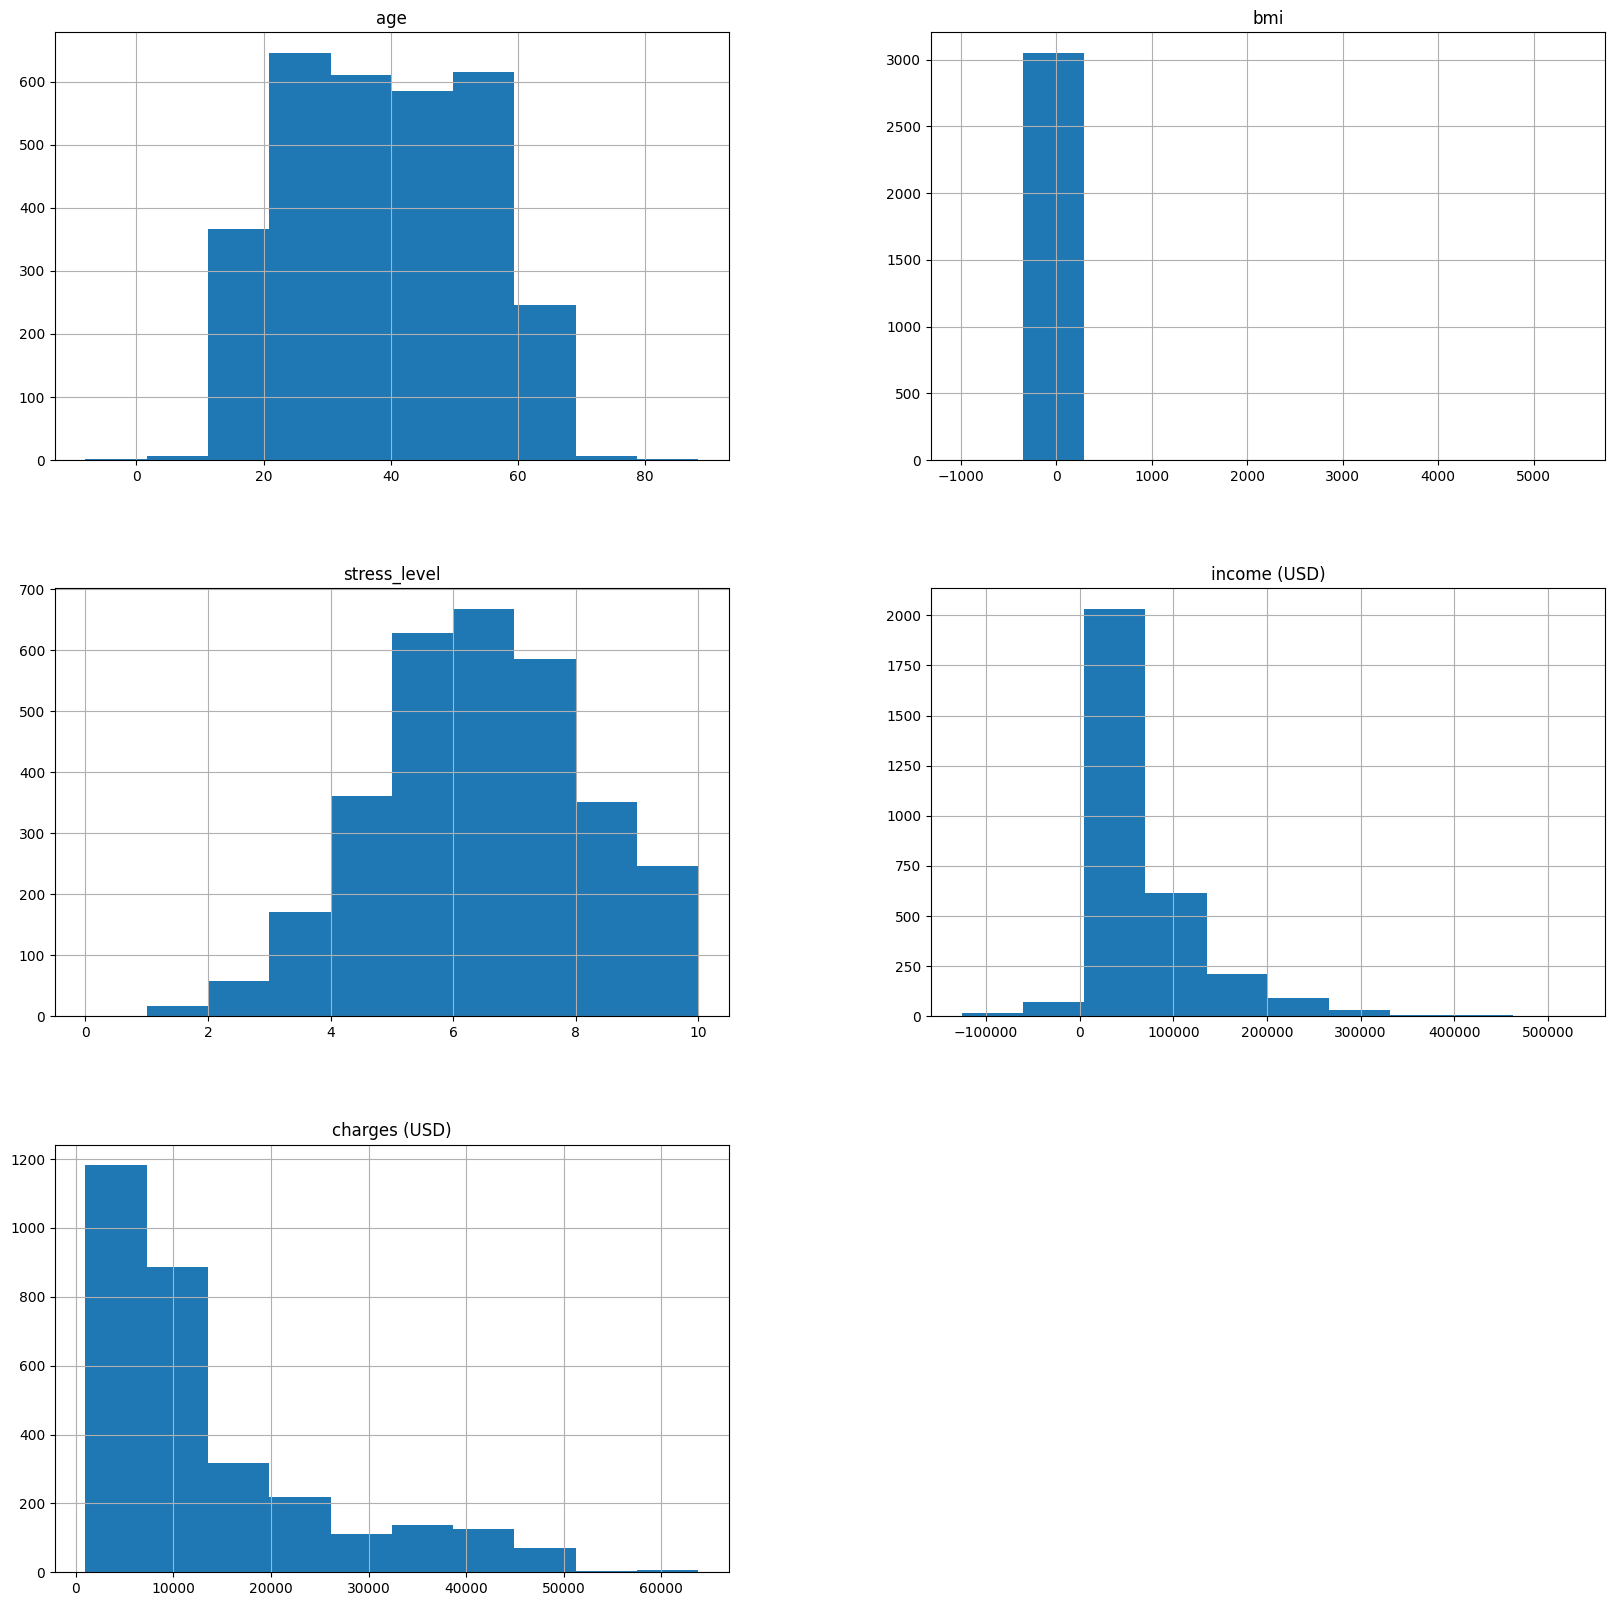

In [166]:
sup = df_nn_col + ["ID"]
df_num_col = [x for x in df.columns.tolist() if x not in sup]

df[df_num_col].hist(figsize=(20,20))
plt.show()

In [167]:
# Count negative values in each numeric column
negative_counts = {}
for col in df_num_col:
    negative_counts[col] = (df[col] < 0).sum()

print("NEGATIVE VALUES FOUND:")
for col, count in negative_counts.items():
    if count > 0:
        print(f"{col}: {count}")

total_negatives = sum(negative_counts.values())
print(f"\nTOTAL: {total_negatives} negative values")

# Identify rows with negative values in numeric columns
rows_with_negatives = df[df[df_num_col].lt(0).any(axis=1)]
print(f"Rows that will be removed: {len(rows_with_negatives)}")

# Store original row count for reporting
original_rows = len(df)
 
# Remove rows with charges (USD) = NaN
df = df.dropna(subset='charges (USD)')

# Remove rows with negative values from the original DataFrame
df.drop(rows_with_negatives.index, inplace=True)

print(f"\nDataset after cleaning:")
print(f"Original rows: {original_rows}")
print(f"Rows after cleaning: {len(df)}")
print(f"Rows removed: {original_rows - len(df)}")


# Reset index after dropping rows
df.reset_index(drop=True, inplace=True)

NEGATIVE VALUES FOUND:
age: 2
bmi: 1
income (USD): 54

TOTAL: 57 negative values
Rows that will be removed: 56

Dataset after cleaning:
Original rows: 3086
Rows after cleaning: 3007
Rows removed: 79


In [168]:
df[df['age'] < 18]

,age,gender,bmi,children,smoker,region,status,work_sector,physical_activity,stress_level,sleep_quality,income (USD),charges (USD)
86,15.123557,female,30.360872,0,no,southeast,Single,Retail,Lightly Active,6.3,Poor,87861.868595,12864.070934
225,15.727649,female,41.854735,3,no,southeast,Married,IT,Moderately Active,4.5,Poor,140960.706083,46680.037223
300,15.168302,female,33.939556,0,yes,southwest,Engaged,Retail Management,Moderately Active,6.7,Fair,111189.507135,2495.923471
442,6.190668,female,22.324037,1,no,southeast,Married,Hospitality,Sedentary,1.8,Excellent,865.951745,5679.525258
446,13.329776,male,31.931234,3,yes,northwest,Single-Parent,Healthcare,Sedentary,7.3,Poor,86474.198292,29890.117369
474,2.374126,female,26.686038,1,no,northwest,Single-Parent,Finance,Moderately Active,6.5,Fair,101398.371162,27999.218508
680,2.879041,female,28.338212,2,yes,southwest,Single-Parent,Finance,Lightly Active,9.1,Poor,148958.692649,37556.610697
770,15.834161,male,38.075766,1,no,northwest,Single-Parent,Healthcare,Lightly Active,8.1,Poor,7890.258501,17332.663693
851,12.526339,female,26.256683,2,no,northwest,Married,Management,Moderately Active,4.3,Fair,143381.792011,3256.099146
862,10.592705,male,31.844211,0,yes,northeast,Married,Hospitality,Lightly Active,6.2,Poor,20342.800913,23619.942885


In [169]:
# Remove people with age less than 18 years (suspicious values)
df = df.drop(df[df['age'] < 18].index)

In [170]:
df[df_num_col] = df[df_num_col].mask(df[df_num_col] < 0)

In [171]:
df.isna().sum()

age                    0
gender                 0
bmi                   29
children               0
smoker               241
region                 0
status                 0
work_sector            0
physical_activity     75
stress_level           0
sleep_quality          1
income (USD)           0
charges (USD)          0
dtype: int64

In [172]:

coll_with_low_nan = ['status', 'sleep_quality','bmi']  

df = df.dropna(subset=coll_with_low_nan)
df.isna().sum()


age                    0
gender                 0
bmi                    0
children               0
smoker               238
region                 0
status                 0
work_sector            0
physical_activity     75
stress_level           0
sleep_quality          0
income (USD)           0
charges (USD)          0
dtype: int64

## Encoding

In [173]:
for i in df_nn_col:
    print(f'The number of unique values in {i} is: {df[i].nunique()}.\nThe unique values contained in {i} feature are: {df[i].unique()}')
    print()

The number of unique values in gender is: 2.
The unique values contained in gender feature are: ['female' 'male']

The number of unique values in children is: 6.
The unique values contained in children feature are: [3 4 2 0 1 5]

The number of unique values in smoker is: 2.
The unique values contained in smoker feature are: ['no' 'yes' nan]

The number of unique values in region is: 4.
The unique values contained in region feature are: ['southwest' 'northwest' 'southeast' 'northeast']

The number of unique values in status is: 4.
The unique values contained in status feature are: ['Single-Parent' 'Engaged' 'Single' 'Married']

The number of unique values in work_sector is: 18.
The unique values contained in work_sector feature are: ['Education' 'IT Support' 'Transportation' 'Hospitality' 'Unemployed'
 'Healthcare Support' 'Retail' 'Entrepreneur' 'Finance' 'Construction'
 'Retail Management' 'Healthcare' 'Law' 'Management' 'Self-Employed' 'IT'
 'other' 'Engineering']

The number of uniq

In [174]:
# Gender - binary encoding
df['gender'] = df['gender'].map({'female': False, 'male': True})

# Smoker - binary encoding
df['smoker'] = df['smoker'].map({'no': False, 'yes': True})

In [175]:
# Region - one-hot encoding
region_dummies = pd.get_dummies(df['region'], prefix='region')
df = pd.concat([df, region_dummies], axis=1)
df = df.drop('region', axis=1)

# Status - one-hot encoding
status_dummies = pd.get_dummies(df['status'], prefix='status')
df = pd.concat([df, status_dummies], axis=1)
df = df.drop('status', axis=1)

# Work Sector - one-hot encoding (many categories)
work_sector_dummies = pd.get_dummies(df['work_sector'], prefix='sector')
df = pd.concat([df, work_sector_dummies], axis=1)
df = df.drop('work_sector', axis=1)

In [176]:
# Physical Activity - ordinal variable (clear progression)
activity_order = ['Sedentary', 'Lightly Active', 'Moderately Active', 'Very Active']
df['physical_activity'] = df['physical_activity'].map({
    'Sedentary': 0,
    'Lightly Active': 1, 
    'Moderately Active': 2,
    'Very Active': 3
})

# Sleep Quality - ordinal variable (clear quality progression)
sleep_order = ['Poor', 'Fair', 'Good', 'Excellent']
df['sleep_quality'] = df['sleep_quality'].map({
    'Poor': 0,
    'Fair': 1,
    'Good': 2,
    'Excellent': 3
})

In [177]:
df

,age,gender,bmi,children,smoker,physical_activity,stress_level,sleep_quality,income (USD),charges (USD),...,sector_IT,sector_IT Support,sector_Law,sector_Management,sector_Retail,sector_Retail Management,sector_Self-Employed,sector_Transportation,sector_Unemployed,sector_other
0,45.0,False,25.700,3,False,1.0,6.9,1,44324.35,9101.79800,...,False,False,False,False,False,False,False,False,False,False
1,32.0,True,28.120,4,True,0.0,6.9,0,102553.91,21472.47880,...,False,True,False,False,False,False,False,False,False,False
2,41.0,False,37.100,2,NaN,3.0,5.9,1,18429.43,7371.77200,...,False,False,False,False,False,False,False,True,False,False
3,26.0,True,31.065,0,False,0.0,5.9,1,14888.09,2699.56835,...,False,False,False,False,False,False,False,False,False,False
4,23.0,False,34.960,3,False,0.0,8.6,2,15571.19,4466.62140,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3002,54.0,True,34.210,2,True,1.0,9.2,0,336130.93,44260.74990,...,False,False,False,False,False,False,False,False,False,False
3003,18.0,False,31.350,4,False,0.0,10.0,0,21624.45,4561.18850,...,False,False,False,False,True,False,False,False,False,False
3004,39.0,False,23.870,5,False,1.0,5.8,2,36357.70,8582.30230,...,False,False,False,False,False,False,False,True,False,False
3005,58.0,True,25.175,0,False,1.0,4.7,0,69475.40,11931.12525,...,False,False,False,False,False,False,False,False,False,False


In [178]:
df.isna().sum()

age                            0
gender                         0
bmi                            0
children                       0
smoker                       238
physical_activity             75
stress_level                   0
sleep_quality                  0
income (USD)                   0
charges (USD)                  0
region_northeast               0
region_northwest               0
region_southeast               0
region_southwest               0
status_Engaged                 0
status_Married                 0
status_Single                  0
status_Single-Parent           0
sector_Construction            0
sector_Education               0
sector_Engineering             0
sector_Entrepreneur            0
sector_Finance                 0
sector_Healthcare              0
sector_Healthcare Support      0
sector_Hospitality             0
sector_IT                      0
sector_IT Support              0
sector_Law                     0
sector_Management              0
sector_Ret

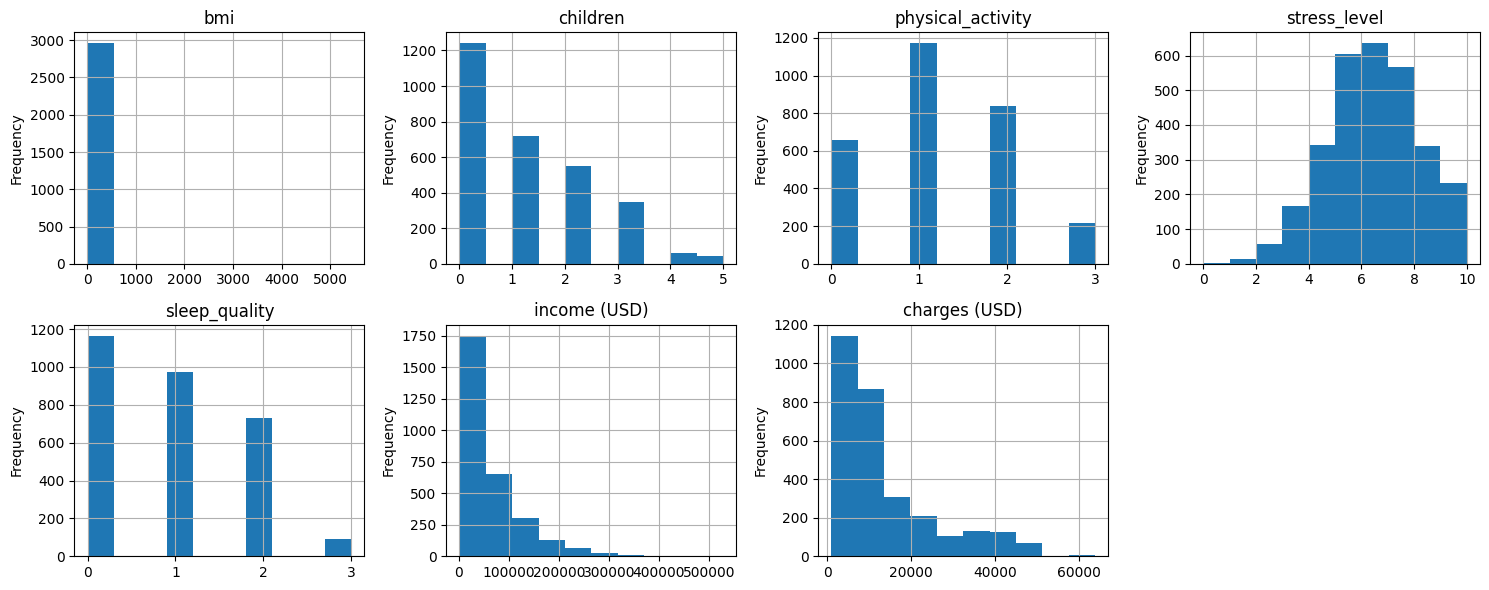

In [179]:
plot_num_cols(df)

## Outliers capping

In [180]:
columns_to_cap  = [
 'age',
 'bmi',
 'income (USD)',
 ]

for col in columns_to_cap :  
    # CALCULATE QUARTILES AND BOUNDS
    Q1, Q3 = df[col].quantile([0.25, 0.75])  # Get both quartiles at once
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5*IQR, Q3 + 1.5*IQR
    
    # APPLY CAPPING USING clip() METHOD
    df[col] = df[col].clip(lower=lower, upper=upper)  # Limits values to [lower, upper] range

In [181]:
columns_to_transform  = [
 #'age',
 'income (USD)',
 ]
for col in columns_to_transform : 
    df[col] = np.log1p(df[col] + 1 )

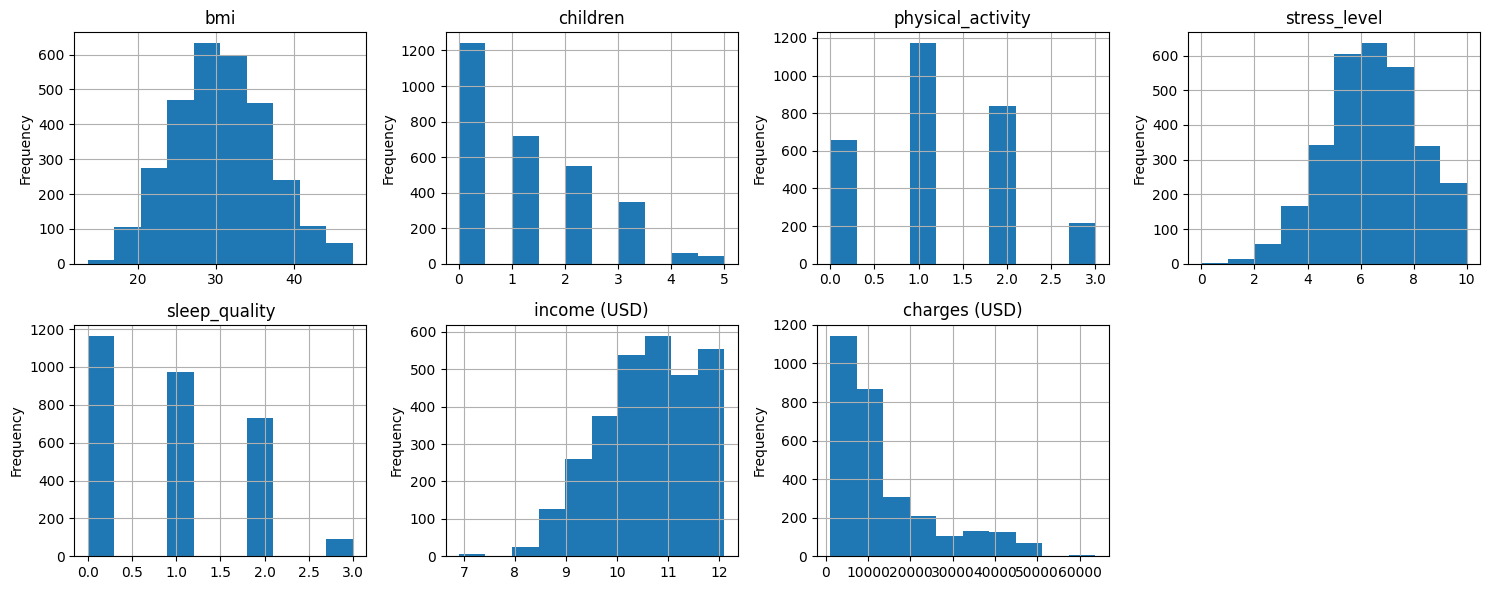

In [182]:
plot_num_cols(df)

## Knn

In [183]:
df_copy = df.copy()

In [184]:
from sklearn.preprocessing import StandardScaler

# Initialize scaler
scaler = StandardScaler()

# Select only numerical columns (excluding boolean)
numerical_cols = df_copy.select_dtypes(include=['int64', 'float64']).columns
#print(numerical_cols)
# Apply scaling only to numerical columns
df_copy[numerical_cols] = scaler.fit_transform(df_copy[numerical_cols])

In [185]:

from sklearn.impute import KNNImputer
knn_imp = KNNImputer(n_neighbors=3) # try imputation with different values of k
df_imputed_knn= pd.DataFrame(knn_imp.fit_transform(df_copy),columns=df_copy.columns)

round_col = ['smoker','physical_activity']

for col in round_col:
    if col in df_imputed_knn.columns:
        df_imputed_knn[col] = np.round(df_imputed_knn[col]).astype(int)

print("Round Col:")
for col in round_col:
    if col in df_imputed_knn.columns:
        print(f"{col}: {df_imputed_knn[col].dtype} - Valori unici: {sorted(df_imputed_knn[col].unique())}")

Round Col:
smoker: int32 - Valori unici: [0, 1]
physical_activity: int32 - Valori unici: [-1, 0, 1, 2]


In [186]:
#sum of the null values in each column after imputation
df_imputed_knn.isnull().sum()

age                          0
gender                       0
bmi                          0
children                     0
smoker                       0
physical_activity            0
stress_level                 0
sleep_quality                0
income (USD)                 0
charges (USD)                0
region_northeast             0
region_northwest             0
region_southeast             0
region_southwest             0
status_Engaged               0
status_Married               0
status_Single                0
status_Single-Parent         0
sector_Construction          0
sector_Education             0
sector_Engineering           0
sector_Entrepreneur          0
sector_Finance               0
sector_Healthcare            0
sector_Healthcare Support    0
sector_Hospitality           0
sector_IT                    0
sector_IT Support            0
sector_Law                   0
sector_Management            0
sector_Retail                0
sector_Retail Management     0
sector_S

In [187]:
print(f"Imputed Data Set {df_imputed_knn.shape} size")
print(f"Originale Data Set {df.shape} size")

Imputed Data Set (2959, 36) size
Originale Data Set (2959, 36) size


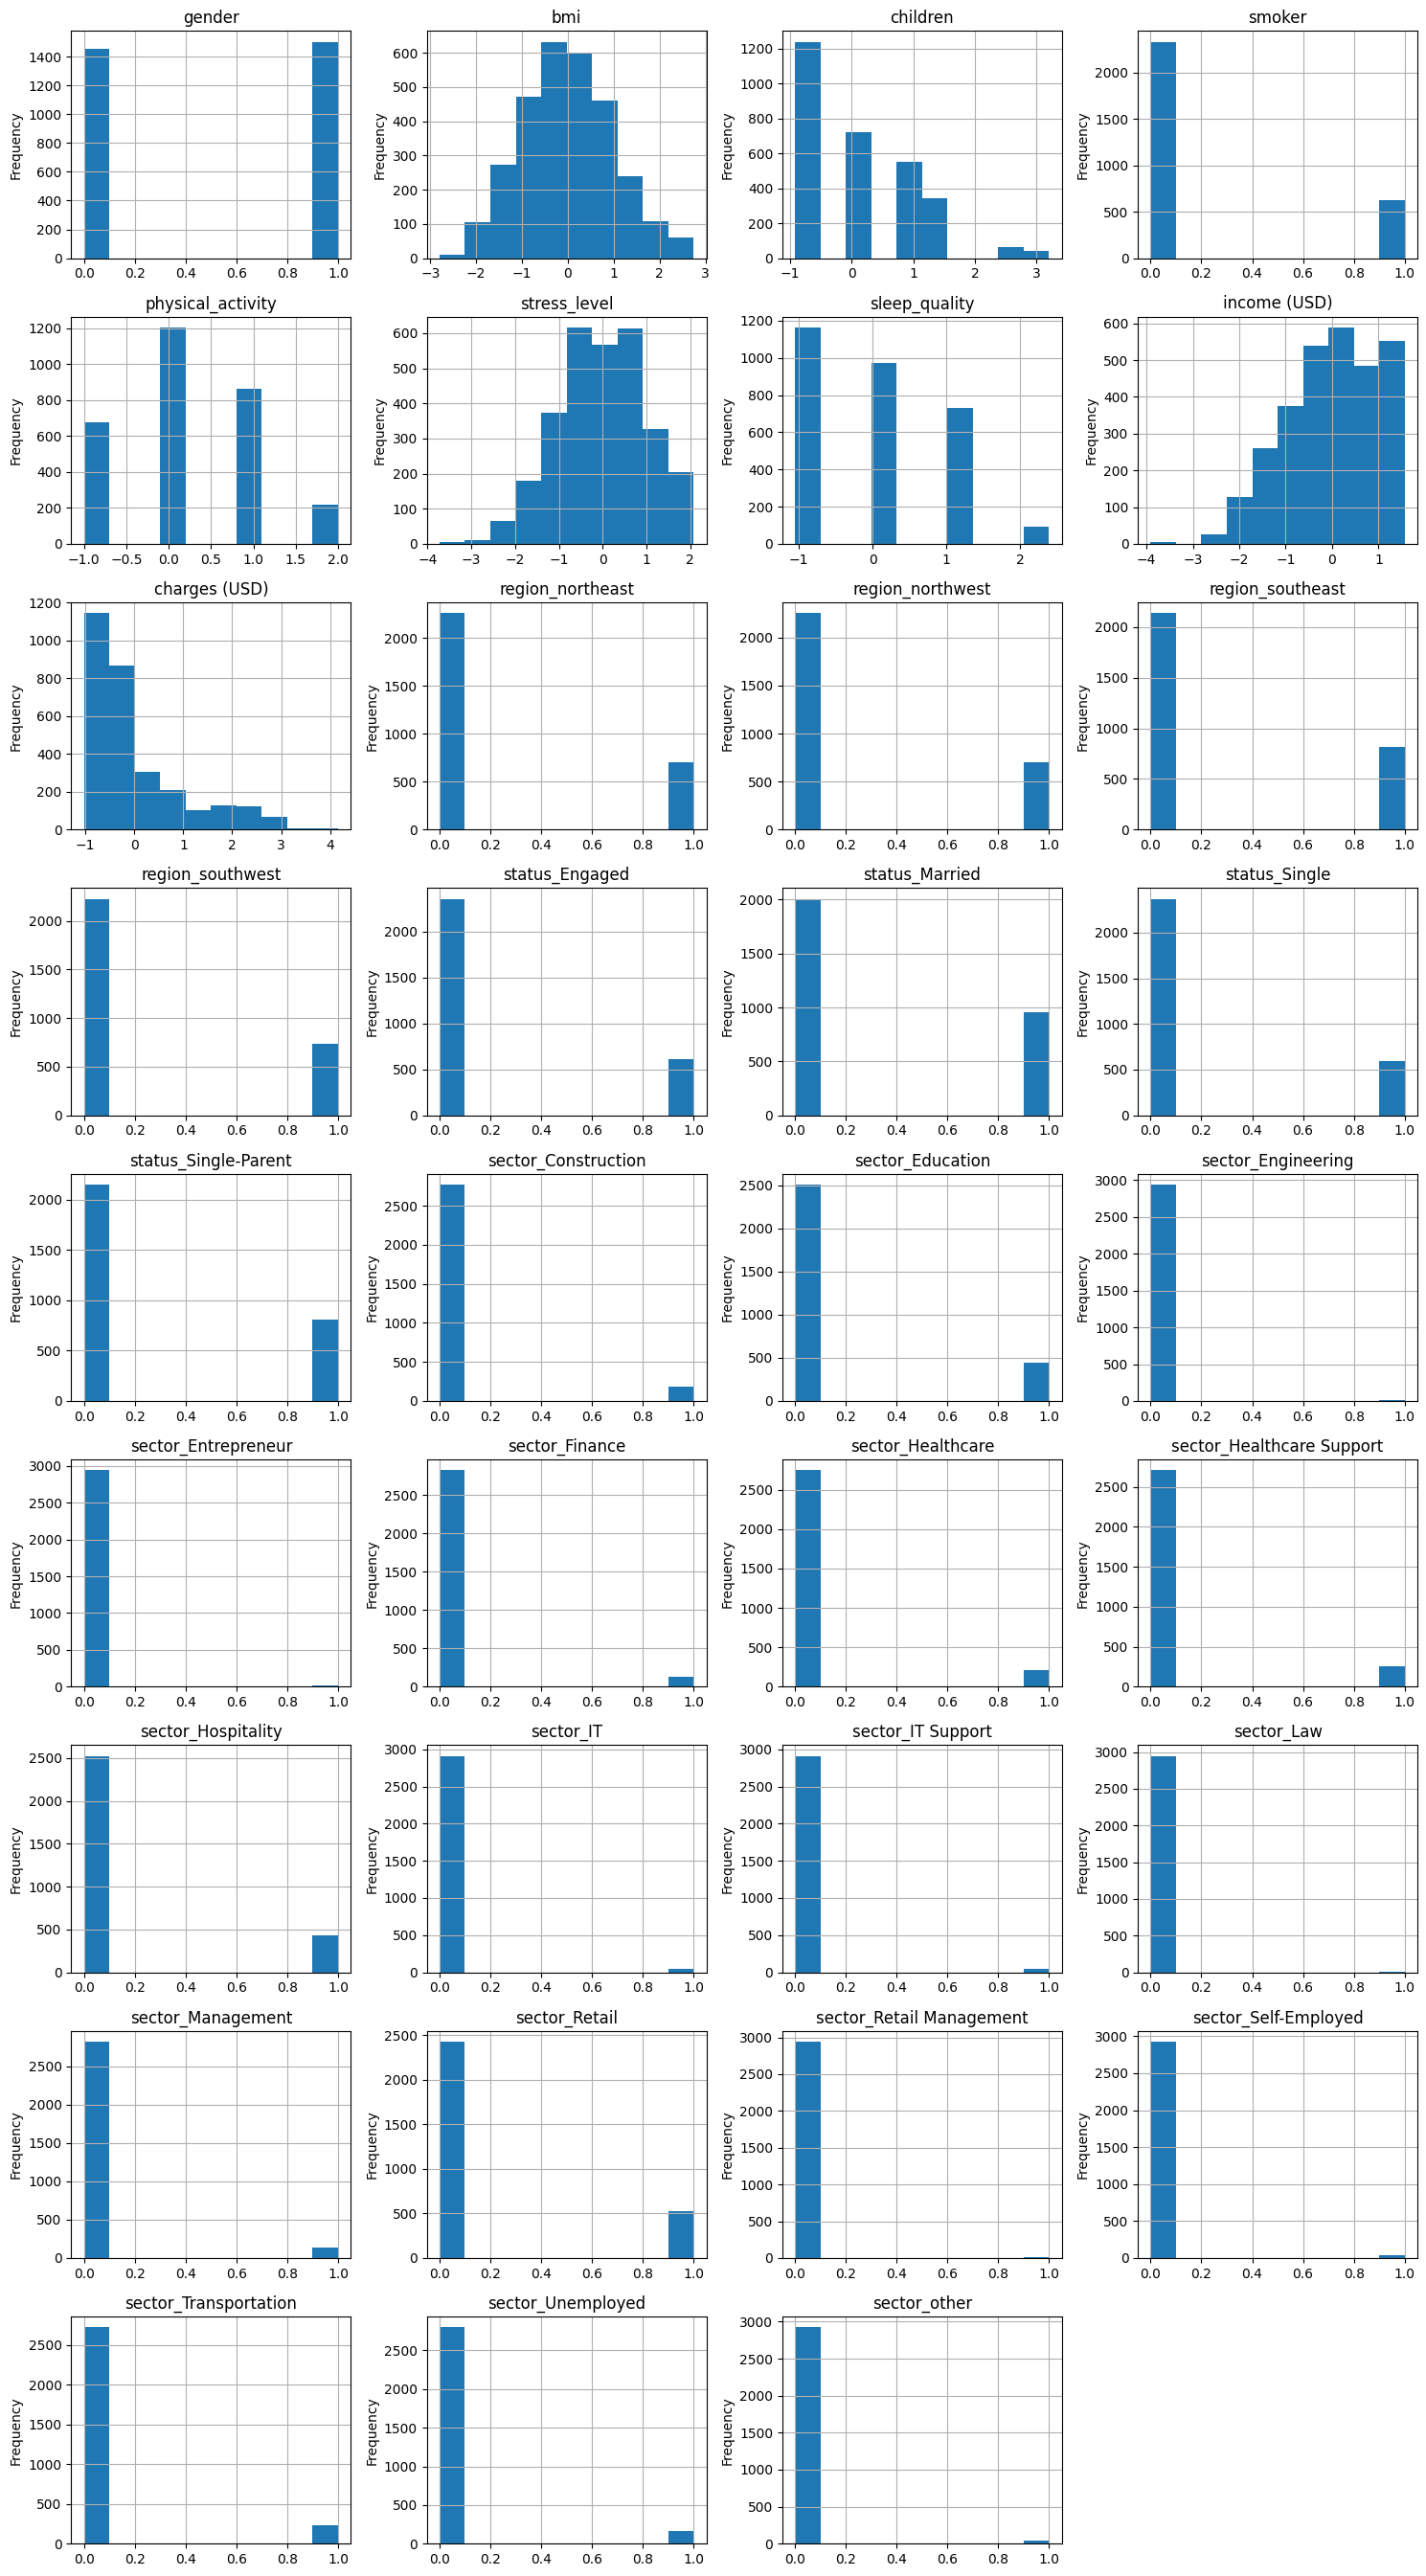

In [188]:
plot_num_cols(df_imputed_knn)

In [189]:
#Index reset
df_imputed_knn = df_imputed_knn.reset_index(drop=True)
df = df.reset_index(drop=True)

df[['smoker','physical_activity']] = df_imputed_knn[['smoker','physical_activity']]

In [190]:
df

,age,gender,bmi,children,smoker,physical_activity,stress_level,sleep_quality,income (USD),charges (USD),...,sector_IT,sector_IT Support,sector_Law,sector_Management,sector_Retail,sector_Retail Management,sector_Self-Employed,sector_Transportation,sector_Unemployed,sector_other
0,45.0,False,25.7000,3,0,0,6.9,1,10.699335,9101.79800,...,False,False,False,False,False,False,False,False,False,False
1,32.0,True,28.1200,4,1,-1,6.9,0,11.538163,21472.47880,...,False,True,False,False,False,False,False,False,False,False
2,41.0,False,37.1000,2,0,2,5.9,1,9.821813,7371.77200,...,False,False,False,False,False,False,False,True,False,False
3,26.0,True,31.0650,0,0,-1,5.9,1,9.608451,2699.56835,...,False,False,False,False,False,False,False,False,False,False
4,23.0,False,34.9600,3,0,-1,8.6,2,9.653306,4466.62140,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2954,54.0,True,34.2100,2,1,0,9.2,0,12.097550,44260.74990,...,False,False,False,False,False,False,False,False,False,False
2955,18.0,False,31.3500,4,0,-1,10.0,0,9.981672,4561.18850,...,False,False,False,False,True,False,False,False,False,False
2956,39.0,False,23.8700,5,0,0,5.8,2,10.501216,8582.30230,...,False,False,False,False,False,False,False,True,False,False
2957,58.0,True,25.1750,0,0,0,4.7,0,11.148757,11931.12525,...,False,False,False,False,False,False,False,False,False,False


In [191]:
# Convert boolean columns to 0/1
bool_columns = df.select_dtypes(include=['bool']).columns
df[bool_columns] = df[bool_columns].astype(int)

# Verify conversion
print("Boolean columns converted:", bool_columns.tolist())
print("Unique values in converted columns:")
for col in bool_columns:
    print(f"{col}: {df[col].unique()}")

Boolean columns converted: ['gender', 'region_northeast', 'region_northwest', 'region_southeast', 'region_southwest', 'status_Engaged', 'status_Married', 'status_Single', 'status_Single-Parent', 'sector_Construction', 'sector_Education', 'sector_Engineering', 'sector_Entrepreneur', 'sector_Finance', 'sector_Healthcare', 'sector_Healthcare Support', 'sector_Hospitality', 'sector_IT', 'sector_IT Support', 'sector_Law', 'sector_Management', 'sector_Retail', 'sector_Retail Management', 'sector_Self-Employed', 'sector_Transportation', 'sector_Unemployed', 'sector_other']
Unique values in converted columns:
gender: [0 1]
region_northeast: [0 1]
region_northwest: [0 1]
region_southeast: [0 1]
region_southwest: [1 0]
status_Engaged: [0 1]
status_Married: [0 1]
status_Single: [0 1]
status_Single-Parent: [1 0]
sector_Construction: [0 1]
sector_Education: [1 0]
sector_Engineering: [0 1]
sector_Entrepreneur: [0 1]
sector_Finance: [0 1]
sector_Healthcare: [0 1]
sector_Healthcare Support: [0 1]
sect

# 3. Build a supervised system based on Linear Regression capable of predicting charges(USD)

## Feature Selection

Original data: 35 features

TOP 15 SELECTED FEATURES:
 1. status_Married       Score: 0.6823
 2. income (USD)         Score: 0.6154
 3. sector_Retail        Score: 0.5016
 4. sector_Hospitality   Score: 0.4936
 5. smoker               Score: 0.4233
 6. status_Single-Parent Score: 0.4187
 7. status_Engaged       Score: 0.4034
 8. status_Single        Score: 0.3902
 9. sector_Education     Score: 0.3864
10. sector_Healthcare    Score: 0.3236
11. sector_Construction  Score: 0.3106
12. sector_Management    Score: 0.3035
13. sector_Finance       Score: 0.2976
14. sector_Healthcare Support Score: 0.2896
15. sector_IT Support    Score: 0.2820

Dataset reduced: 35 → 15 features


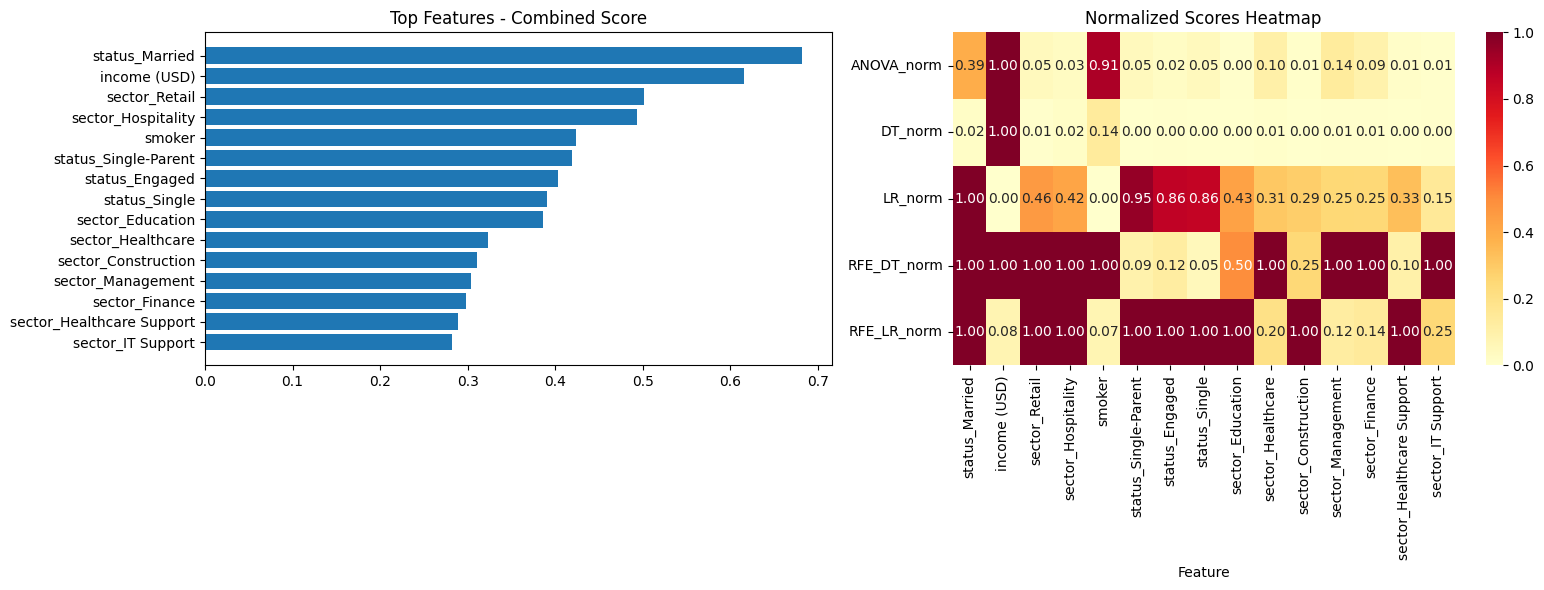

,status_Married,income (USD),sector_Retail,sector_Hospitality,smoker,status_Single-Parent,status_Engaged,status_Single,sector_Education,sector_Healthcare,sector_Construction,sector_Management,sector_Finance,sector_Healthcare Support,sector_IT Support,charges (USD)
0,0,10.699335,0,0,0,1,0,0,1,0,0,0,0,0,0,9101.79800
1,0,11.538163,0,0,1,0,1,0,0,0,0,0,0,0,1,21472.47880
2,0,9.821813,0,0,0,1,0,0,0,0,0,0,0,0,0,7371.77200
3,0,9.608451,0,0,0,0,0,1,1,0,0,0,0,0,0,2699.56835
4,1,9.653306,0,1,0,0,0,0,0,0,0,0,0,0,0,4466.62140
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2954,1,12.097550,0,0,1,0,0,0,0,0,0,0,1,0,0,44260.74990
2955,0,9.981672,1,0,0,1,0,0,0,0,0,0,0,0,0,4561.18850
2956,0,10.501216,0,0,0,1,0,0,0,0,0,0,0,0,0,8582.30230
2957,0,11.148757,0,0,0,0,0,1,1,0,0,0,0,0,0,11931.12525


In [192]:
# =============================================================================
# QUICK FEATURE SELECTION - SYNTHETIC VERSION
# =============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import RFE, f_classif, f_regression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import StandardScaler

# INPUT: Your DataFrame
# df = your_dataframe

# Configuration
TARGET_COLUMN = 'charges (USD)'  # Change this to your target column name
PROBLEM_TYPE = 'regression'  # 'classification' or 'regression'
N_FEATURES = 15  # Number of top features to select

# Prepare data
X = df.drop(columns=[TARGET_COLUMN])
y = df[TARGET_COLUMN]

print(f"Original data: {X.shape[1]} features")

# Initialize results storage
results = pd.DataFrame({'Feature': X.columns})

# 1. ANOVA
if PROBLEM_TYPE == 'classification':
    anova_scores = f_classif(X, y)[0]
else:
    anova_scores = f_regression(X, y)[0]
results['ANOVA'] = anova_scores

# 2. Decision Tree Importance
if PROBLEM_TYPE == 'classification':
    dt = DecisionTreeClassifier(random_state=42).fit(X, y)
else:
    dt = DecisionTreeRegressor(random_state=42).fit(X, y)
results['DT_Importance'] = dt.feature_importances_

# 3. Linear Model Coefficients
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

if PROBLEM_TYPE == 'classification':
    lr = LogisticRegression(max_iter=1000).fit(X_scaled, y)
    results['LR_Coeff'] = np.abs(lr.coef_[0])
else:
    lr = LinearRegression().fit(X_scaled, y)
    results['LR_Coeff'] = np.abs(lr.coef_)

# 4. RFE with Decision Tree
if PROBLEM_TYPE == 'classification':
    rfe_dt = RFE(DecisionTreeClassifier(random_state=42), n_features_to_select=N_FEATURES).fit(X, y)
else:
    rfe_dt = RFE(DecisionTreeRegressor(random_state=42), n_features_to_select=N_FEATURES).fit(X, y)
results['RFE_DT_Rank'] = rfe_dt.ranking_

# 5. RFE with Linear Model
if PROBLEM_TYPE == 'classification':
    rfe_lr = RFE(LogisticRegression(max_iter=1000), n_features_to_select=N_FEATURES).fit(X_scaled, y)
else:
    rfe_lr = RFE(LinearRegression(), n_features_to_select=N_FEATURES).fit(X_scaled, y)
results['RFE_LR_Rank'] = rfe_lr.ranking_

# Normalize and combine scores
results['ANOVA_norm'] = results['ANOVA'] / results['ANOVA'].max()
results['DT_norm'] = results['DT_Importance'] / results['DT_Importance'].max()
results['LR_norm'] = results['LR_Coeff'] / results['LR_Coeff'].max()
results['RFE_DT_norm'] = 1 / results['RFE_DT_Rank']  # Lower rank = better
results['RFE_LR_norm'] = 1 / results['RFE_LR_Rank']  # Lower rank = better

# Combined score
results['Combined_Score'] = results[['ANOVA_norm', 'DT_norm', 'LR_norm', 'RFE_DT_norm', 'RFE_LR_norm']].mean(axis=1)

# Get top features
top_features = results.nlargest(N_FEATURES, 'Combined_Score')
selected_features = top_features['Feature'].tolist()

# Create reduced dataset
df_reduced = df[selected_features + [TARGET_COLUMN]]

# =============================================================================
# RESULTS VISUALIZATION
# =============================================================================
print(f"\nTOP {N_FEATURES} SELECTED FEATURES:")
print("=" * 50)
for i, (_, row) in enumerate(top_features.iterrows(), 1):
    print(f"{i:2d}. {row['Feature']:20} Score: {row['Combined_Score']:.4f}")

print(f"\nDataset reduced: {X.shape[1]} → {len(selected_features)} features")

# Plot results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Combined scores
ax1.barh(range(len(top_features)), top_features['Combined_Score'])
ax1.set_yticks(range(len(top_features)))
ax1.set_yticklabels(top_features['Feature'])
ax1.set_title('Top Features - Combined Score')
ax1.invert_yaxis()

# Heatmap
scores_heatmap = top_features.set_index('Feature')[['ANOVA_norm', 'DT_norm', 'LR_norm', 'RFE_DT_norm', 'RFE_LR_norm']]
sns.heatmap(scores_heatmap.T, annot=True, cmap='YlOrRd', ax=ax2, fmt='.2f')
ax2.set_title('Normalized Scores Heatmap')

plt.tight_layout()
plt.show()

# Return reduced dataset
df_reduced

In [193]:

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.datasets import make_regression

np.random.seed(42)

In [194]:
df

,age,gender,bmi,children,smoker,physical_activity,stress_level,sleep_quality,income (USD),charges (USD),...,sector_IT,sector_IT Support,sector_Law,sector_Management,sector_Retail,sector_Retail Management,sector_Self-Employed,sector_Transportation,sector_Unemployed,sector_other
0,45.0,0,25.7000,3,0,0,6.9,1,10.699335,9101.79800,...,0,0,0,0,0,0,0,0,0,0
1,32.0,1,28.1200,4,1,-1,6.9,0,11.538163,21472.47880,...,0,1,0,0,0,0,0,0,0,0
2,41.0,0,37.1000,2,0,2,5.9,1,9.821813,7371.77200,...,0,0,0,0,0,0,0,1,0,0
3,26.0,1,31.0650,0,0,-1,5.9,1,9.608451,2699.56835,...,0,0,0,0,0,0,0,0,0,0
4,23.0,0,34.9600,3,0,-1,8.6,2,9.653306,4466.62140,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2954,54.0,1,34.2100,2,1,0,9.2,0,12.097550,44260.74990,...,0,0,0,0,0,0,0,0,0,0
2955,18.0,0,31.3500,4,0,-1,10.0,0,9.981672,4561.18850,...,0,0,0,0,1,0,0,0,0,0
2956,39.0,0,23.8700,5,0,0,5.8,2,10.501216,8582.30230,...,0,0,0,0,0,0,0,1,0,0
2957,58.0,1,25.1750,0,0,0,4.7,0,11.148757,11931.12525,...,0,0,0,0,0,0,0,0,0,0


In [195]:
df_reduced

,status_Married,income (USD),sector_Retail,sector_Hospitality,smoker,status_Single-Parent,status_Engaged,status_Single,sector_Education,sector_Healthcare,sector_Construction,sector_Management,sector_Finance,sector_Healthcare Support,sector_IT Support,charges (USD)
0,0,10.699335,0,0,0,1,0,0,1,0,0,0,0,0,0,9101.79800
1,0,11.538163,0,0,1,0,1,0,0,0,0,0,0,0,1,21472.47880
2,0,9.821813,0,0,0,1,0,0,0,0,0,0,0,0,0,7371.77200
3,0,9.608451,0,0,0,0,0,1,1,0,0,0,0,0,0,2699.56835
4,1,9.653306,0,1,0,0,0,0,0,0,0,0,0,0,0,4466.62140
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2954,1,12.097550,0,0,1,0,0,0,0,0,0,0,1,0,0,44260.74990
2955,0,9.981672,1,0,0,1,0,0,0,0,0,0,0,0,0,4561.18850
2956,0,10.501216,0,0,0,1,0,0,0,0,0,0,0,0,0,8582.30230
2957,0,11.148757,0,0,0,0,0,1,1,0,0,0,0,0,0,11931.12525


In [196]:
df_reduced_wo_income = df_reduced.drop('income (USD)', axis=1).copy()

In [197]:
df_reduced_wo_income

,status_Married,sector_Retail,sector_Hospitality,smoker,status_Single-Parent,status_Engaged,status_Single,sector_Education,sector_Healthcare,sector_Construction,sector_Management,sector_Finance,sector_Healthcare Support,sector_IT Support,charges (USD)
0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,9101.79800
1,0,0,0,1,0,1,0,0,0,0,0,0,0,1,21472.47880
2,0,0,0,0,1,0,0,0,0,0,0,0,0,0,7371.77200
3,0,0,0,0,0,0,1,1,0,0,0,0,0,0,2699.56835
4,1,0,1,0,0,0,0,0,0,0,0,0,0,0,4466.62140
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2954,1,0,0,1,0,0,0,0,0,0,0,1,0,0,44260.74990
2955,0,1,0,0,1,0,0,0,0,0,0,0,0,0,4561.18850
2956,0,0,0,0,1,0,0,0,0,0,0,0,0,0,8582.30230
2957,0,0,0,0,0,0,1,1,0,0,0,0,0,0,11931.12525


## Scaling 

In [198]:
from sklearn.preprocessing import StandardScaler

target = 'charges (USD)'

scaler = StandardScaler()
col_to_scale =['age', 'bmi', 'children', 'income (USD)']	 
scaling_col = [col for col in df_reduced.columns if col != target and col in col_to_scale] 
if len(scaling_col) > 0:
    df_reduced[scaling_col] = scaler.fit_transform(df_reduced[scaling_col])

col_to_scale =['age', 'bmi', 'children']
scaling_col = [col for col in df_reduced_wo_income.columns if col != target and col in col_to_scale]
if len(scaling_col) > 0:
    df_reduced_wo_income[scaling_col] = scaler.fit_transform(df_reduced_wo_income[scaling_col])

In [199]:
df_reduced

,status_Married,income (USD),sector_Retail,sector_Hospitality,smoker,status_Single-Parent,status_Engaged,status_Single,sector_Education,sector_Healthcare,sector_Construction,sector_Management,sector_Finance,sector_Healthcare Support,sector_IT Support,charges (USD)
0,0,0.089463,0,0,0,1,0,0,1,0,0,0,0,0,0,9101.79800
1,0,0.973316,0,0,1,0,1,0,0,0,0,0,0,0,1,21472.47880
2,0,-0.835160,0,0,0,1,0,0,0,0,0,0,0,0,0,7371.77200
3,0,-1.059974,0,0,0,0,0,1,1,0,0,0,0,0,0,2699.56835
4,1,-1.012711,0,1,0,0,0,0,0,0,0,0,0,0,0,4466.62140
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2954,1,1.562728,0,0,1,0,0,0,0,0,0,0,1,0,0,44260.74990
2955,0,-0.666720,1,0,0,1,0,0,0,0,0,0,0,0,0,4561.18850
2956,0,-0.119289,0,0,0,1,0,0,0,0,0,0,0,0,0,8582.30230
2957,0,0.563008,0,0,0,0,0,1,1,0,0,0,0,0,0,11931.12525


In [200]:
df_reduced_wo_income

,status_Married,sector_Retail,sector_Hospitality,smoker,status_Single-Parent,status_Engaged,status_Single,sector_Education,sector_Healthcare,sector_Construction,sector_Management,sector_Finance,sector_Healthcare Support,sector_IT Support,charges (USD)
0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,9101.79800
1,0,0,0,1,0,1,0,0,0,0,0,0,0,1,21472.47880
2,0,0,0,0,1,0,0,0,0,0,0,0,0,0,7371.77200
3,0,0,0,0,0,0,1,1,0,0,0,0,0,0,2699.56835
4,1,0,1,0,0,0,0,0,0,0,0,0,0,0,4466.62140
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2954,1,0,0,1,0,0,0,0,0,0,0,1,0,0,44260.74990
2955,0,1,0,0,1,0,0,0,0,0,0,0,0,0,4561.18850
2956,0,0,0,0,1,0,0,0,0,0,0,0,0,0,8582.30230
2957,0,0,0,0,0,0,1,1,0,0,0,0,0,0,11931.12525


## a) Linear Regression (sklearn)

### Code

In [201]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.inspection import permutation_importance

class LinearRegressionModel:
    """
    Complete class for Linear Regression that can be used with different datasets
    Assumes the input DataFrame is already encoded and scaled
    """
    
    def __init__(self, test_size=0.2, random_state=42):
        """
        Initialize the model
        
        Args:
            test_size (float): Percentage of data for test set (default: 0.2)
            random_state (int): Seed for reproducibility (default: 42)
        """
        self.model = LinearRegression()
        self.test_size = test_size
        self.random_state = random_state
        self.is_trained = False
        self.feature_names = None
        
    def prepare_data(self, df, target_column):
        """
        Prepare data for training by splitting into features and target
        
        Args:
            df (pd.DataFrame): Preprocessed DataFrame (already encoded and scaled)
            target_column (str): Name of the target column
            
        Returns:
            tuple: X_train, X_test, y_train, y_test
        """
        # Separate features and target
        X = df.drop(columns=[target_column])
        y = df[target_column]
        
        # Store feature names for later use
        self.feature_names = X.columns.tolist()
        
        # Split data into training and test sets
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, 
            test_size=self.test_size, 
            random_state=self.random_state
        )
        
        return X_train, X_test, y_train, y_test
    
    def train(self, X_train, y_train):
        """
        Train the linear regression model
        
        Args:
            X_train: Training features
            y_train: Training target values
        """
        self.model.fit(X_train, y_train)
        self.is_trained = True
        print("Model trained successfully!")
    
    def predict(self, X):
        """
        Make predictions using the trained model
        
        Args:
            X: Features for prediction
            
        Returns:
            array: Model predictions
        """
        if not self.is_trained:
            raise ValueError("Model must be trained before making predictions")
        return self.model.predict(X)
    
    def evaluate(self, X_test, y_test):
        """
        Evaluate model performance on test data
        
        Args:
            X_test: Test features
            y_test: True target values for test set
            
        Returns:
            dict: Dictionary containing evaluation metrics
        """
        if not self.is_trained:
            raise ValueError("Model must be trained before evaluation")
        
        # Generate predictions
        y_pred = self.predict(X_test)
        
        # Calculate evaluation metrics
        metrics = {
            'mse': mean_squared_error(y_test, y_pred),
            'rmse': np.sqrt(mean_squared_error(y_test, y_pred)),
            'mae': mean_absolute_error(y_test, y_pred),
            'r2': r2_score(y_test, y_pred),
            'adj_r2': self._calculate_adjusted_r2(X_test, y_test, y_pred)
        }
        
        return metrics
    
    def _calculate_adjusted_r2(self, X, y_true, y_pred):
        """
        Calculate adjusted R-squared score
        
        Args:
            X: Feature matrix
            y_true: True target values
            y_pred: Predicted target values
            
        Returns:
            float: Adjusted R-squared value
        """
        n = len(y_true)  # Number of samples
        p = X.shape[1]   # Number of features
        r2 = r2_score(y_true, y_pred)
        return 1 - (1 - r2) * (n - 1) / (n - p - 1)
    
    def cross_validate(self, X, y, cv=5):
        """
        Perform cross-validation to assess model stability
        
        Args:
            X: Complete feature matrix
            y: Complete target vector
            cv (int): Number of cross-validation folds (default: 5)
            
        Returns:
            dict: Cross-validation results
        """
        if not self.is_trained:
            raise ValueError("Model must be trained before cross-validation")
        
        # Perform cross-validation using R² score
        cv_scores = cross_val_score(self.model, X, y, cv=cv, scoring='r2')
        
        return {
            'mean_r2': cv_scores.mean(),
            'std_r2': cv_scores.std(),
            'all_scores': cv_scores
        }
    
    def get_coefficients(self):
        """
        Get model coefficients with feature names
        
        Returns:
            pd.DataFrame: DataFrame with features and their coefficients, sorted by absolute importance
        """
        if not self.is_trained:
            raise ValueError("Model must be trained before accessing coefficients")
        
        # Create DataFrame with feature names and coefficients
        coefficients = pd.DataFrame({
            'feature': self.feature_names,
            'coefficient': self.model.coef_
        }).sort_values('coefficient', key=abs, ascending=False)
        
        return coefficients
    
    def plot_feature_importance(self, figsize=(10, 6)):
        """
        Plot feature importance based on coefficient magnitudes
        """
        if not self.is_trained:
            raise ValueError("Model must be trained before plotting")
        
        # Get coefficients sorted by importance
        coef_df = self.get_coefficients()
        
        # Create horizontal bar plot
        plt.figure(figsize=figsize)
        sns.barplot(data=coef_df, x='coefficient', y='feature', palette='viridis')
        plt.title('Feature Importance - Linear Regression Coefficients')
        plt.xlabel('Coefficient Value')
        plt.ylabel('Features')
        plt.tight_layout()
        plt.show()
    
    def plot_predictions_vs_actual(self, X_test, y_test, figsize=(10, 6)):
        """
        Plot predicted values vs actual values with perfect prediction line
        """
        if not self.is_trained:
            raise ValueError("Model must be trained before plotting")
        
        # Generate predictions
        y_pred = self.predict(X_test)
        
        # Create scatter plot
        plt.figure(figsize=figsize)
        plt.scatter(y_test, y_pred, alpha=0.6, label='Predictions')
        
        # Add perfect prediction line (y=x)
        min_val = min(y_test.min(), y_pred.min())
        max_val = max(y_test.max(), y_pred.max())
        plt.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Perfect Prediction')
        
        plt.xlabel('Actual Values')
        plt.ylabel('Predicted Values')
        plt.title('Predictions vs Actual Values')
        plt.legend()
        plt.tight_layout()
        plt.show()
    
    def plot_residuals(self, X_test, y_test, figsize=(12, 5)):
        """
        Plot residual analysis: residuals vs predictions and residual distribution
        """
        if not self.is_trained:
            raise ValueError("Model must be trained before plotting")
        
        # Generate predictions and calculate residuals
        y_pred = self.predict(X_test)
        residuals = y_test - y_pred
        
        # Create subplots
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=figsize)
        
        # Residuals vs Predictions plot
        ax1.scatter(y_pred, residuals, alpha=0.6)
        ax1.axhline(y=0, color='r', linestyle='--', label='Zero Residual')
        ax1.set_xlabel('Predicted Values')
        ax1.set_ylabel('Residuals')
        ax1.set_title('Residuals vs Predicted Values')
        ax1.legend()
        
        # Residual distribution histogram
        ax2.hist(residuals, bins=30, alpha=0.7, edgecolor='black', density=True)
        ax2.set_xlabel('Residuals')
        ax2.set_ylabel('Density')
        ax2.set_title('Residual Distribution')
        
        plt.tight_layout()
        plt.show()
    
    def get_model_summary(self, X_test, y_test):
        """
        Generate comprehensive model summary
        
        Args:
            X_test: Test features
            y_test: Test target values
            
        Returns:
            dict: Complete model summary
        """
        metrics = self.evaluate(X_test, y_test)
        coefficients = self.get_coefficients()
        
        summary = {
            'metrics': metrics,
            'coefficients': coefficients,
            'intercept': self.model.intercept_,
            'n_features': len(self.feature_names)
        }
        
        return summary

def run_linear_regression(df, target_column, test_size=0.2, random_state=42, cv=5):
    """
    Complete pipeline function to run linear regression on any preprocessed dataset
    
    Args:
        df (pd.DataFrame): Preprocessed DataFrame (already encoded and scaled)
        target_column (str): Name of the target column
        test_size (float): Percentage for test set (default: 0.2)
        random_state (int): Random seed for reproducibility (default: 42)
        cv (int): Number of cross-validation folds (default: 5)
    
    Returns:
        tuple: (trained_model, evaluation_metrics, feature_coefficients)
    """
    
    # Initialize the model
    lr_model = LinearRegressionModel(test_size=test_size, random_state=random_state)
    
    # Prepare data (split into train/test)
    X_train, X_test, y_train, y_test = lr_model.prepare_data(df, target_column)
    
    # Train the model
    lr_model.train(X_train, y_train)
    
    # Evaluate model performance
    metrics = lr_model.evaluate(X_test, y_test)
    
    # Perform cross-validation on entire dataset
    cv_results = lr_model.cross_validate(
        pd.concat([X_train, X_test]), 
        pd.concat([y_train, y_test]), 
        cv=cv
    )
    
    # Get feature coefficients
    coefficients = lr_model.get_coefficients()
    
    # Print comprehensive results
    print("=" * 60)
    print("LINEAR REGRESSION COMPLETE RESULTS")
    print("=" * 60)
    print(f"\nPERFORMANCE METRICS:")
    print(f"R² Score: {metrics['r2']:.4f}")
    print(f"Adjusted R²: {metrics['adj_r2']:.4f}")
    print(f"Mean Squared Error (MSE): {metrics['mse']:.4f}")
    print(f"Root Mean Squared Error (RMSE): {metrics['rmse']:.4f}")
    print(f"Mean Absolute Error (MAE): {metrics['mae']:.4f}")
    
    print(f"\nCROSS-VALIDATION RESULTS (cv={cv}):")
    print(f"Mean R² Score: {cv_results['mean_r2']:.4f} (+/- {cv_results['std_r2'] * 2:.4f})")
    
    print(f"\nTOP 10 MOST IMPORTANT FEATURES:")
    print(coefficients.head(10).to_string(index=False))
    
    # Generate all plots
    print(f"\nGENERATING VISUALIZATIONS...")
    lr_model.plot_feature_importance()
    lr_model.plot_predictions_vs_actual(X_test, y_test)
    lr_model.plot_residuals(X_test, y_test)
    
    return lr_model, metrics, coefficients

### Implementation 1 (with income (USD))

Model trained successfully!
LINEAR REGRESSION COMPLETE RESULTS

PERFORMANCE METRICS:
R² Score: 0.7596
Adjusted R²: 0.7533
Mean Squared Error (MSE): 34302279.3806
Root Mean Squared Error (RMSE): 5856.8148
Mean Absolute Error (MAE): 3931.0977

CROSS-VALIDATION RESULTS (cv=5):
Mean R² Score: 0.7761 (+/- 0.0390)

TOP 10 MOST IMPORTANT FEATURES:
             feature   coefficient
      status_Married  9.402247e+16
       status_Single  9.402247e+16
      status_Engaged  9.402247e+16
status_Single-Parent  9.402247e+16
              smoker  8.990000e+03
   sector_Management  6.757000e+03
      sector_Finance  5.338500e+03
        income (USD)  4.992000e+03
 sector_Construction -3.374000e+03
   sector_Healthcare  3.253000e+03

GENERATING VISUALIZATIONS...


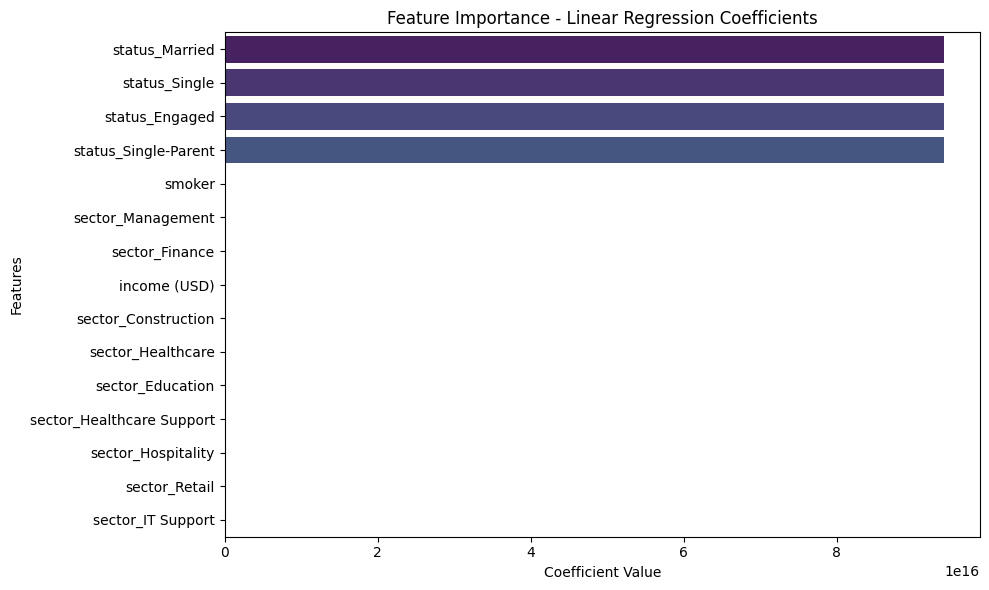

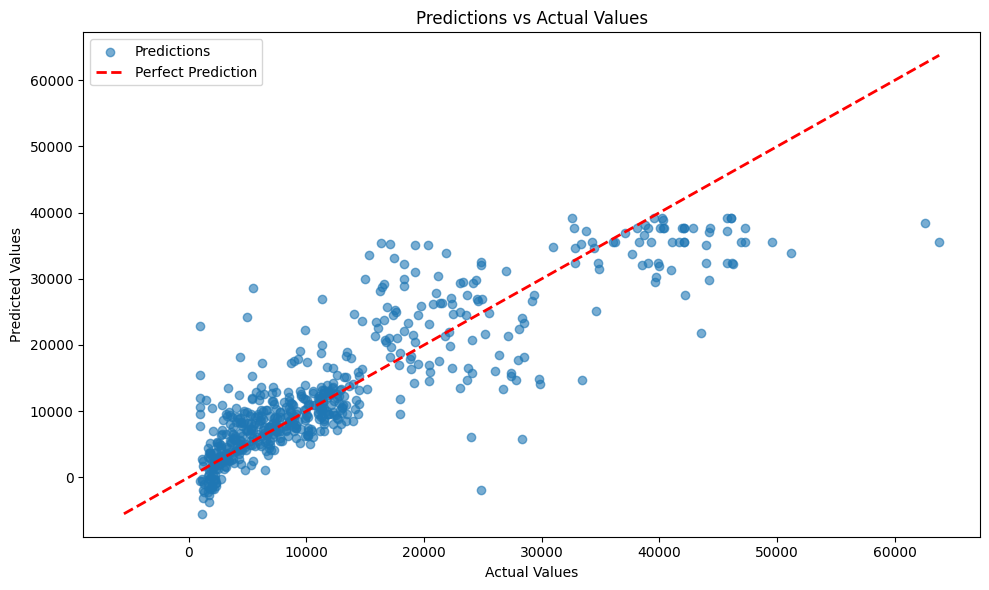

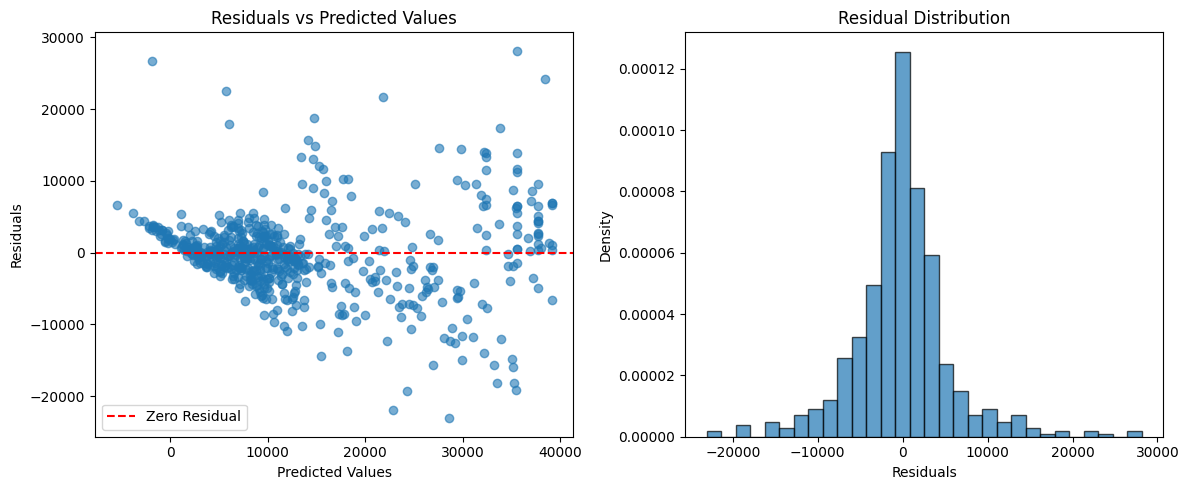

In [202]:
model, metrics, coef = run_linear_regression(df_reduced, target)

### Implementation 2 (with out income (USD))

Model trained successfully!
LINEAR REGRESSION COMPLETE RESULTS

PERFORMANCE METRICS:
R² Score: 0.6496
Adjusted R²: 0.6411
Mean Squared Error (MSE): 49985216.0700
Root Mean Squared Error (RMSE): 7070.0224
Mean Absolute Error (MAE): 5301.7564

CROSS-VALIDATION RESULTS (cv=5):
Mean R² Score: 0.6689 (+/- 0.0387)

TOP 10 MOST IMPORTANT FEATURES:
                  feature   coefficient
           status_Married  6.918253e+16
     status_Single-Parent  6.918253e+16
           status_Engaged  6.918253e+16
            status_Single  6.918253e+16
                   smoker  1.318400e+04
        sector_Management  9.712000e+03
           sector_Finance  8.054000e+03
        sector_Healthcare  6.250000e+03
      sector_Construction -3.728000e+03
sector_Healthcare Support -3.435480e+03

GENERATING VISUALIZATIONS...


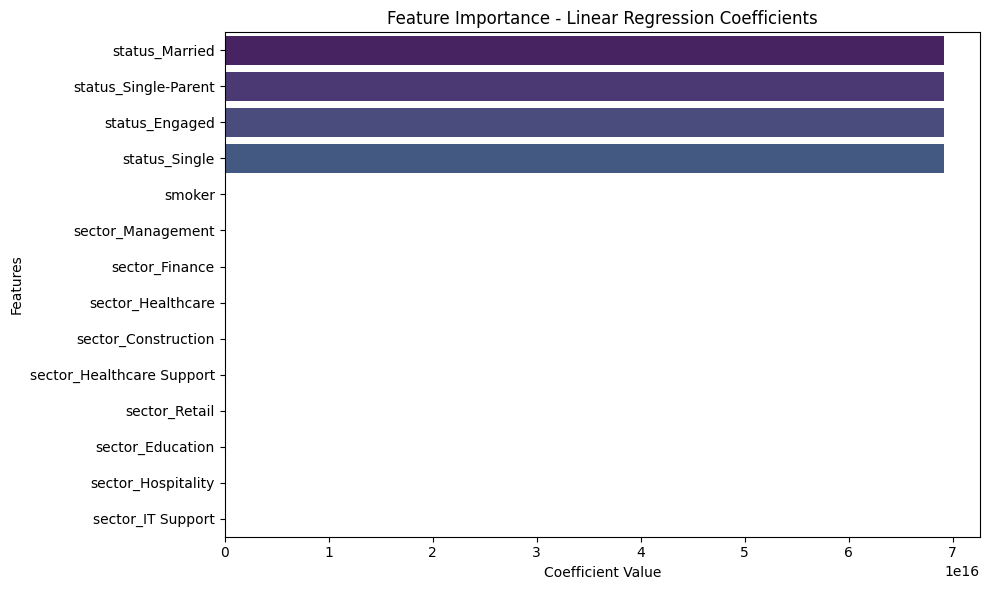

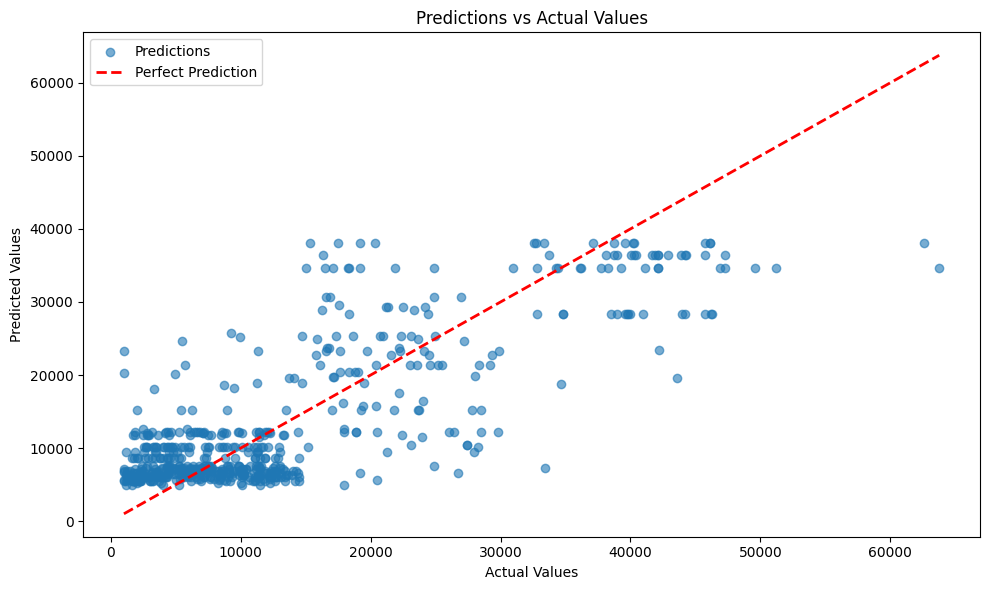

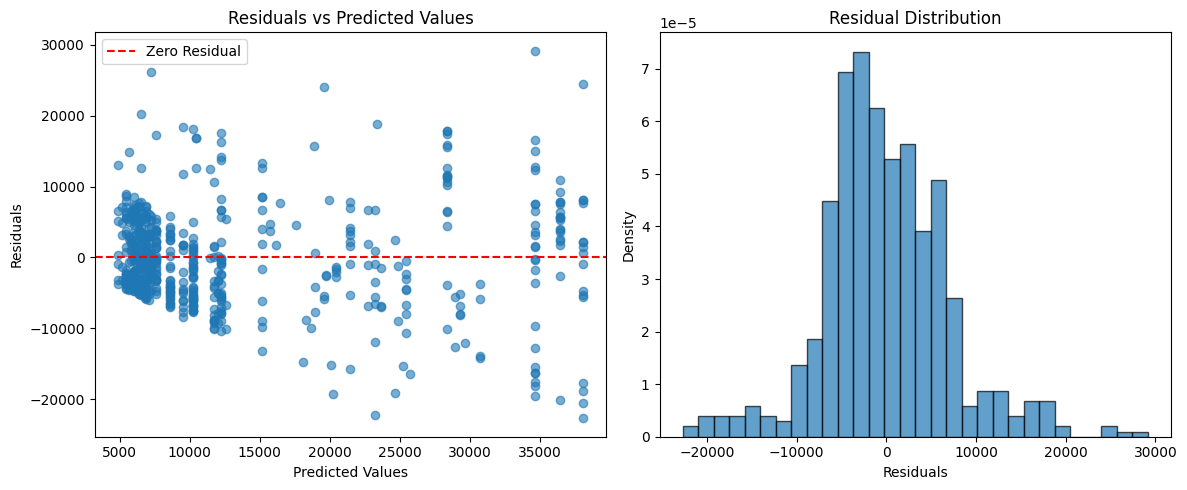

In [203]:
model, metrics, coef = run_linear_regression(df_reduced_wo_income, target)

## b) Linear Regression (Batch Gradient Descent)

### Code

In [204]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

class BatchGradientDescentLinearRegression:
    """
    Linear Regression implementation using Batch Gradient Descent
    """
    
    def __init__(self, learning_rate=0.01, n_iterations=1000, random_state=42):
        """
        Initialize the Batch Gradient Descent Linear Regression model
        
        Args:
            learning_rate (float): Step size for gradient descent (default: 0.01)
            n_iterations (int): Maximum number of iterations (default: 1000)
            random_state (int): Random seed for reproducibility (default: 42)
        """
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.random_state = random_state
        self.weights = None
        self.bias = None
        self.cost_history = []
        self.is_trained = False
        
    def _add_intercept(self, X):
        """Add intercept term to features"""
        intercept = np.ones((X.shape[0], 1))
        return np.concatenate([intercept, X], axis=1)
    
    def _compute_cost(self, X, y):
        """
        Compute the Mean Squared Error cost function
        
        Args:
            X: Feature matrix
            y: Target vector
            
        Returns:
            float: MSE cost
        """
        predictions = X.dot(self.weights) + self.bias
        errors = predictions - y
        cost = (1 / (2 * len(y))) * np.sum(errors ** 2)
        return cost
    
    def _compute_gradients(self, X, y):
        """
        Compute gradients for weights and bias
        
        Args:
            X: Feature matrix
            y: Target vector
            
        Returns:
            tuple: (weight_gradients, bias_gradient)
        """
        predictions = X.dot(self.weights) + self.bias
        errors = predictions - y
        
        # Compute gradients
        dw = (1 / len(y)) * X.T.dot(errors)
        db = (1 / len(y)) * np.sum(errors)
        
        return dw, db
    
    def fit(self, X, y, verbose=False, early_stopping=True, tolerance=1e-6):
        """
        Train the model using Batch Gradient Descent
        
        Args:
            X: Feature matrix
            y: Target vector
            verbose (bool): Whether to print progress (default: False)
            early_stopping (bool): Whether to stop early if convergence is reached
            tolerance (float): Convergence tolerance (default: 1e-6)
        """
        # GESTIONE NaN: Controlla se ci sono valori NaN negli input
        if np.any(np.isnan(X)) or np.any(np.isnan(y)):
            raise ValueError("Input contains NaN values. Please clean your data before training.")
        
        # Initialize parameters
        np.random.seed(self.random_state)
        self.weights = np.random.randn(X.shape[1])
        self.bias = np.random.randn()
        
        self.cost_history = []
        
        for i in range(self.n_iterations):
            # Compute gradients
            dw, db = self._compute_gradients(X, y)
            
            # Update parameters
            self.weights -= self.learning_rate * dw
            self.bias -= self.learning_rate * db
            
            # Compute and store cost
            cost = self._compute_cost(X, y)
            self.cost_history.append(cost)
            
            # GESTIONE NaN: Controlla se il costo è NaN
            if np.isnan(cost):
                if verbose:
                    print(f"Warning: Cost became NaN at iteration {i}. Stopping training.")
                break
            
            # Print progress every 100 iterations
            if verbose and i % 100 == 0:
                print(f"Iteration {i}: Cost = {cost:.6f}")
            
            # Early stopping check
            if early_stopping and i > 0:
                cost_change = abs(self.cost_history[-2] - cost)
                if cost_change < tolerance:
                    if verbose:
                        print(f"Convergence reached at iteration {i}")
                    break
        
        self.is_trained = True
        if verbose:
            print(f"Training completed. Final cost: {cost:.6f}")
    
    def predict(self, X):
        """
        Make predictions using the trained model
        
        Args:
            X: Feature matrix
            
        Returns:
            array: Predictions
        """
        if not self.is_trained:
            raise ValueError("Model must be trained before making predictions")
        
        # GESTIONE NaN: Controlla se ci sono NaN nei dati di predizione
        if np.any(np.isnan(X)):
            raise ValueError("Input for prediction contains NaN values.")
            
        return X.dot(self.weights) + self.bias
    
    def get_parameters(self):
        """
        Get model parameters
        
        Returns:
            dict: Model weights and bias
        """
        if not self.is_trained:
            raise ValueError("Model must be trained before accessing parameters")
        return {'weights': self.weights, 'bias': self.bias}
    
    def plot_cost_history(self, figsize=(10, 6)):
        """
        Plot the cost function history during training
        """
        if not self.is_trained:
            raise ValueError("Model must be trained before plotting")
        
        plt.figure(figsize=figsize)
        plt.plot(range(len(self.cost_history)), self.cost_history, 'b-', linewidth=2)
        plt.xlabel('Iteration')
        plt.ylabel('Cost (MSE)')
        plt.title('Cost Function History - Batch Gradient Descent')
        plt.grid(True, alpha=0.3)
        
        # Disable scientific notation on Y-axis
        plt.ticklabel_format(style='plain', axis='y')
        
        plt.show()

def find_optimal_learning_rate(X_train, y_train, X_val, y_val, learning_rates=[0.001, 0.01, 0.1, 0.5, 1.0], 
                              n_iterations=1000, plot_results=True):
    """
    Find the optimal learning rate by testing multiple values
    
    Args:
        X_train: Training features
        y_train: Training targets
        X_val: Validation features
        y_val: Validation targets
        learning_rates (list): List of learning rates to test
        n_iterations (int): Number of iterations for each run
        plot_results (bool): Whether to plot the results
        
    Returns:
        tuple: (best_learning_rate, results_df)
    """
    results = []
    
    for lr in learning_rates:
        try:
            # Train model with current learning rate
            model = BatchGradientDescentLinearRegression(
                learning_rate=lr, 
                n_iterations=n_iterations,
                random_state=42
            )
            model.fit(X_train, y_train, verbose=False)
            
            # Make predictions and calculate metrics
            y_pred = model.predict(X_val)
            mse = mean_squared_error(y_val, y_pred)
            r2 = r2_score(y_val, y_pred)
            
            # Check if model converged
            converged = len(model.cost_history) < n_iterations or (
                len(model.cost_history) >= 2 and 
                abs(model.cost_history[-1] - model.cost_history[-2]) < 1e-6
            )
            
            results.append({
                'learning_rate': lr,
                'mse': mse,
                'r2': r2,
                'final_cost': model.cost_history[-1],
                'iterations_to_converge': len(model.cost_history),
                'converged': converged,
                'success': True
            })
            
            print(f"✓ Learning Rate: {lr:.4f} | MSE: {mse:.4f} | R²: {r2:.4f} | "
                  f"Converged: {converged} | Iterations: {len(model.cost_history)}")
        
        except Exception as e:
            # GESTIONE NaN: Cattura eccezioni dovute a NaN
            print(f"✗ Learning Rate: {lr:.4f} | Failed: {str(e)}")
            results.append({
                'learning_rate': lr,
                'mse': np.nan,
                'r2': np.nan,
                'final_cost': np.nan,
                'iterations_to_converge': 0,
                'converged': False,
                'success': False
            })
    
    # Create results DataFrame
    results_df = pd.DataFrame(results)
    
    # Filtra solo i risultati che hanno avuto successo
    successful_results = results_df[results_df['success']]
    
    if successful_results.empty:
        raise ValueError("All learning rates failed. Check your data for NaN values or try different learning rates.")
    
    best_lr = successful_results.loc[successful_results['mse'].idxmin(), 'learning_rate']
    
    if plot_results:
        fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(15, 10))
        
        # Plot solo i risultati successful
        successful_df = results_df[results_df['success']]
        
        # Plot 1: MSE vs Learning Rate
        ax1.plot(successful_df['learning_rate'], successful_df['mse'], 'bo-', linewidth=2, markersize=8)
        ax1.set_xlabel('Learning Rate')
        ax1.set_ylabel('Validation MSE')
        ax1.set_title('Validation MSE vs Learning Rate')
        ax1.grid(True, alpha=0.3)
        ax1.ticklabel_format(style='plain', axis='y')
        
        # Plot 2: R² vs Learning Rate
        ax2.plot(successful_df['learning_rate'], successful_df['r2'], 'go-', linewidth=2, markersize=8)
        ax2.set_xlabel('Learning Rate')
        ax2.set_ylabel('Validation R²')
        ax2.set_title('Validation R² vs Learning Rate')
        ax2.grid(True, alpha=0.3)
        ax2.ticklabel_format(style='plain', axis='y')
        
        # Plot 3: Iterations to Converge
        ax3.bar(range(len(successful_df)), successful_df['iterations_to_converge'], 
               color=['green' if conv else 'red' for conv in successful_df['converged']])
        ax3.set_xlabel('Learning Rate Index')
        ax3.set_ylabel('Iterations to Converge')
        ax3.set_title('Iterations to Convergence')
        ax3.set_xticks(range(len(successful_df)))
        ax3.set_xticklabels([f'{lr:.3f}' for lr in successful_df['learning_rate']])
        ax3.ticklabel_format(style='plain', axis='y')
        
        # Plot 4: Final Cost
        ax4.plot(successful_df['learning_rate'], successful_df['final_cost'], 'ro-', linewidth=2, markersize=8)
        ax4.set_xlabel('Learning Rate')
        ax4.set_ylabel('Final Training Cost')
        ax4.set_title('Final Training Cost vs Learning Rate')
        ax4.grid(True, alpha=0.3)
        ax4.ticklabel_format(style='plain', axis='y')
        
        plt.tight_layout()
        plt.show()
    
    print(f"\nOptimal Learning Rate: {best_lr}")
    return best_lr, results_df

def analyze_convergence(X_train, y_train, optimal_learning_rate, max_iterations=2000):
    """
    Analyze convergence behavior with optimal learning rate
    
    Args:
        X_train: Training features
        y_train: Training targets
        optimal_learning_rate (float): Optimal learning rate found
        max_iterations (int): Maximum number of iterations to test
        
    Returns:
        BatchGradientDescentLinearRegression: Trained model
    """
    # GESTIONE NaN: Controlla input prima di addestrare
    if np.any(np.isnan(X_train)) or np.any(np.isnan(y_train)):
        raise ValueError("Training data contains NaN values. Please clean your data first.")
    
    # Train model with optimal learning rate
    model = BatchGradientDescentLinearRegression(
        learning_rate=optimal_learning_rate,
        n_iterations=max_iterations,
        random_state=42
    )
    
    print(f"Training model with learning rate: {optimal_learning_rate}")
    model.fit(X_train, y_train, verbose=True)
    
    # Plot cost history
    model.plot_cost_history()
    
    # Analyze convergence
    final_cost = model.cost_history[-1]
    cost_reduction = model.cost_history[0] - final_cost
    iterations_used = len(model.cost_history)
    
    print(f"\nConvergence Analysis:")
    print(f"Initial Cost: {model.cost_history[0]:.6f}")
    print(f"Final Cost: {final_cost:.6f}")
    print(f"Cost Reduction: {cost_reduction:.6f}")
    print(f"Iterations Used: {iterations_used}")
    print(f"Convergence Ratio: {cost_reduction / model.cost_history[0] * 100:.2f}%")
    
    return model

def run_batch_gradient_descent_regression(df, target_column, test_size=0.2, val_size=0.2, 
                                        random_state=42, learning_rates=None):
    """
    Complete pipeline for Batch Gradient Descent Linear Regression
    """
    if learning_rates is None:
        learning_rates = [0.001, 0.005, 0.01, 0.05, 0.1, 0.5, 1.0]
    
    # GESTIONE NaN: Pulisci il dataset dai NaN PRIMA di tutto
    print("Checking for NaN values in the dataset...")
    nan_count = df.isnull().sum().sum()
    if nan_count > 0:
        print(f"Found {nan_count} NaN values in the dataset. Removing rows with NaN...")
        df_clean = df.dropna().copy()
        print(f"Dataset shape after cleaning: {df_clean.shape} (removed {len(df) - len(df_clean)} rows)")
    else:
        df_clean = df.copy()
        print("No NaN values found in the dataset.")
    
    if df_clean.empty:
        raise ValueError("No data remaining after NaN removal. Please check your dataset.")
    
    # Prepare data
    X = df_clean.drop(columns=[target_column]).values
    y = df_clean[target_column].values
    
    # GESTIONE NaN: Controllo finale prima dello split
    if np.any(np.isnan(X)) or np.any(np.isnan(y)):
        raise ValueError("NaN values still present after cleaning. Please check your data preprocessing.")
    
    # Split data: first into train+val and test, then split train+val into train and val
    X_temp, X_test, y_temp, y_test = train_test_split(
        X, y, test_size=test_size, random_state=random_state
    )
    
    val_size_adj = val_size / (1 - test_size)  # Adjust validation size
    X_train, X_val, y_train, y_val = train_test_split(
        X_temp, y_temp, test_size=val_size_adj, random_state=random_state
    )
    
    print("Data Preparation Complete:")
    print(f"Training set: {X_train.shape}")
    print(f"Validation set: {X_val.shape}")
    print(f"Test set: {X_test.shape}")
    
    # Step 1: Find optimal learning rate
    print("\n" + "="*60)
    print("STEP 1: FINDING OPTIMAL LEARNING RATE")
    print("="*60)
    
    optimal_lr, lr_results = find_optimal_learning_rate(
        X_train, y_train, X_val, y_val, 
        learning_rates=learning_rates,
        n_iterations=1000
    )
    
    # Step 2: Analyze convergence with optimal learning rate
    print("\n" + "="*60)
    print("STEP 2: CONVERGENCE ANALYSIS WITH OPTIMAL LEARNING RATE")
    print("="*60)
    
    final_model = analyze_convergence(X_train, y_train, optimal_lr, max_iterations=2000)
    
    # Step 3: Final evaluation on test set
    print("\n" + "="*60)
    print("STEP 3: FINAL EVALUATION ON TEST SET")
    print("="*60)
    
    y_pred = final_model.predict(X_test)
    
    metrics = {
        'mse': mean_squared_error(y_test, y_pred),
        'rmse': np.sqrt(mean_squared_error(y_test, y_pred)),
        'mae': mean_absolute_error(y_test, y_pred),
        'r2': r2_score(y_test, y_pred)
    }
    
    # Print results
    print("\nFINAL MODEL PERFORMANCE:")
    print(f"R² Score: {metrics['r2']:.4f}")
    print(f"MSE: {metrics['mse']:.4f}")
    print(f"RMSE: {metrics['rmse']:.4f}")
    print(f"MAE: {metrics['mae']:.4f}")
    print(f"Optimal Learning Rate: {optimal_lr}")
    print(f"Final Iterations: {len(final_model.cost_history)}")
    
    # Plot predictions vs actual
    plt.figure(figsize=(10, 6))
    plt.scatter(y_test, y_pred, alpha=0.6)
    plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
    plt.xlabel('Actual Values')
    plt.ylabel('Predicted Values')
    plt.title('Batch Gradient Descent: Predictions vs Actual Values')
    plt.ticklabel_format(style='plain', axis='both')
    plt.show()
    
    # Plot residuals
    residuals = y_test - y_pred
    plt.figure(figsize=(12, 5))
    
    plt.subplot(1, 2, 1)
    plt.scatter(y_pred, residuals, alpha=0.6)
    plt.axhline(y=0, color='r', linestyle='--')
    plt.xlabel('Predicted Values')
    plt.ylabel('Residuals')
    plt.title('Residuals vs Predicted Values')
    plt.ticklabel_format(style='plain', axis='both')
    
    plt.subplot(1, 2, 2)
    plt.hist(residuals, bins=30, alpha=0.7, edgecolor='black')
    plt.xlabel('Residuals')
    plt.ylabel('Frequency')
    plt.title('Residual Distribution')
    plt.ticklabel_format(style='plain', axis='x')
    
    plt.tight_layout()
    plt.show()
    
    return final_model, metrics, optimal_lr

### Implementation 1 (with income (USD))

Checking for NaN values in the dataset...
No NaN values found in the dataset.
Data Preparation Complete:
Training set: (1775, 15)
Validation set: (592, 15)
Test set: (592, 15)

STEP 1: FINDING OPTIMAL LEARNING RATE
✓ Learning Rate: 0.0100 | MSE: 33447596.0231 | R²: 0.7468 | Converged: False | Iterations: 1000
✓ Learning Rate: 0.0600 | MSE: 30910826.5848 | R²: 0.7660 | Converged: False | Iterations: 1000
✓ Learning Rate: 0.1100 | MSE: 30790102.5019 | R²: 0.7669 | Converged: False | Iterations: 1000
✓ Learning Rate: 0.1600 | MSE: 30767243.5809 | R²: 0.7671 | Converged: False | Iterations: 1000
✓ Learning Rate: 0.2100 | MSE: 30760659.5159 | R²: 0.7671 | Converged: False | Iterations: 1000
✓ Learning Rate: 0.2600 | MSE: 30758322.3614 | R²: 0.7672 | Converged: False | Iterations: 1000
✓ Learning Rate: 0.3100 | MSE: 30757356.5182 | R²: 0.7672 | Converged: False | Iterations: 1000
✓ Learning Rate: 0.3600 | MSE: 30756911.7308 | R²: 0.7672 | Converged: False | Iterations: 1000
✓ Learning Rate: 

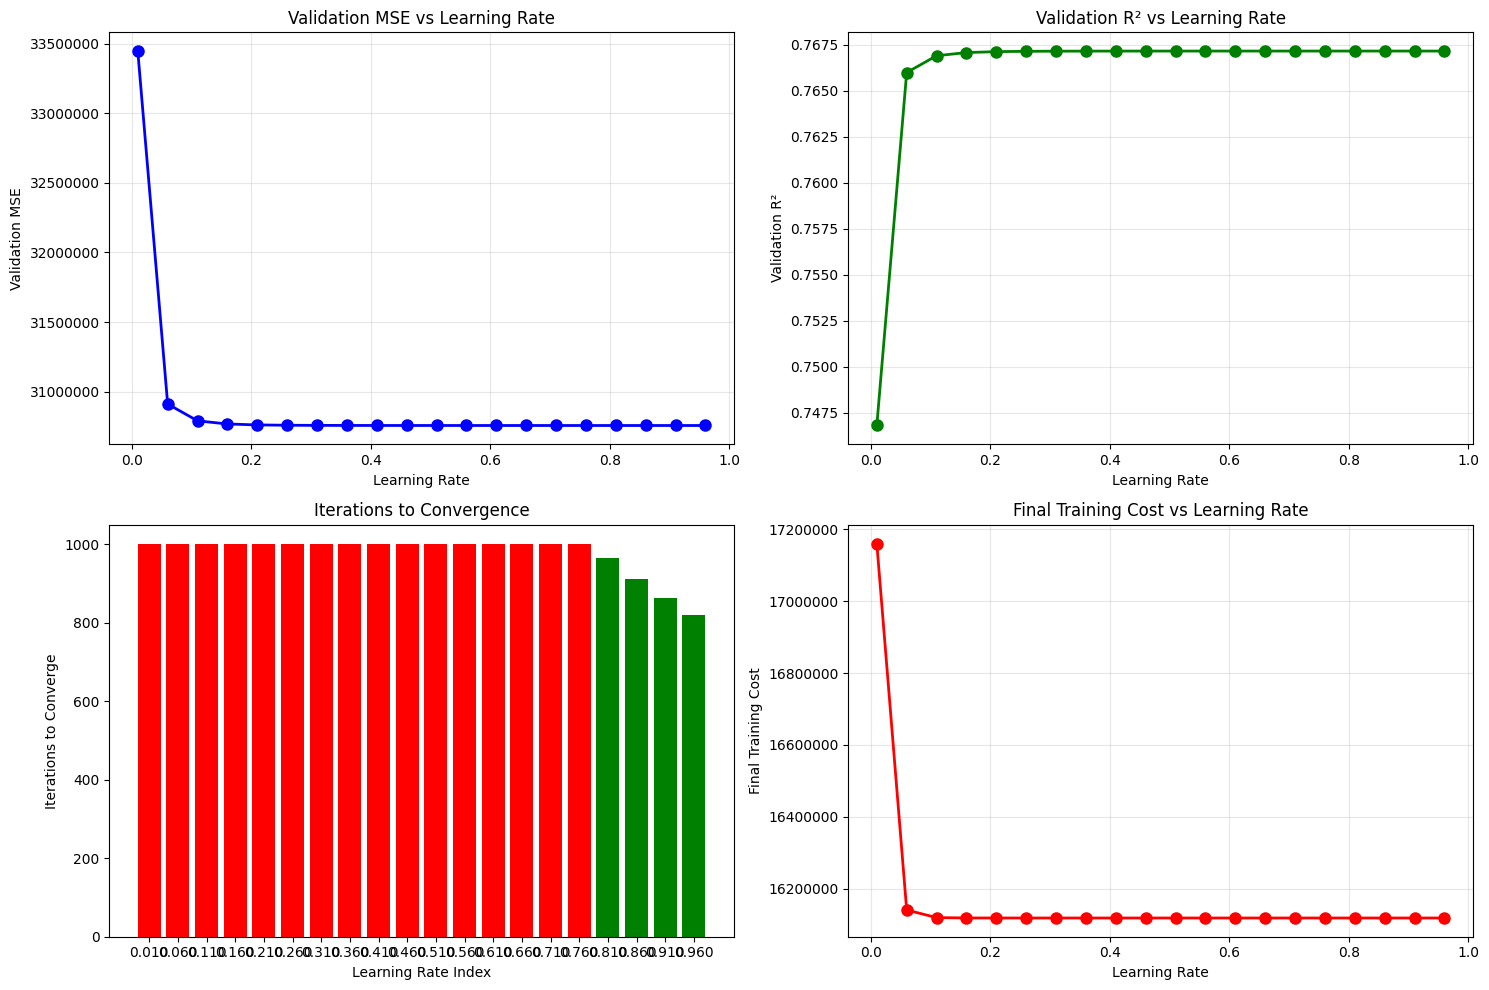


Optimal Learning Rate: 0.96

STEP 2: CONVERGENCE ANALYSIS WITH OPTIMAL LEARNING RATE
Training model with learning rate: 0.96
Iteration 0: Cost = 39798230.491446
Iteration 100: Cost = 16120733.524070
Iteration 200: Cost = 16118651.811410
Iteration 300: Cost = 16118604.500699
Iteration 400: Cost = 16118599.957964
Iteration 500: Cost = 16118599.479727
Iteration 600: Cost = 16118599.428943
Iteration 700: Cost = 16118599.423544
Iteration 800: Cost = 16118599.422969
Convergence reached at iteration 820
Training completed. Final cost: 16118599.422945


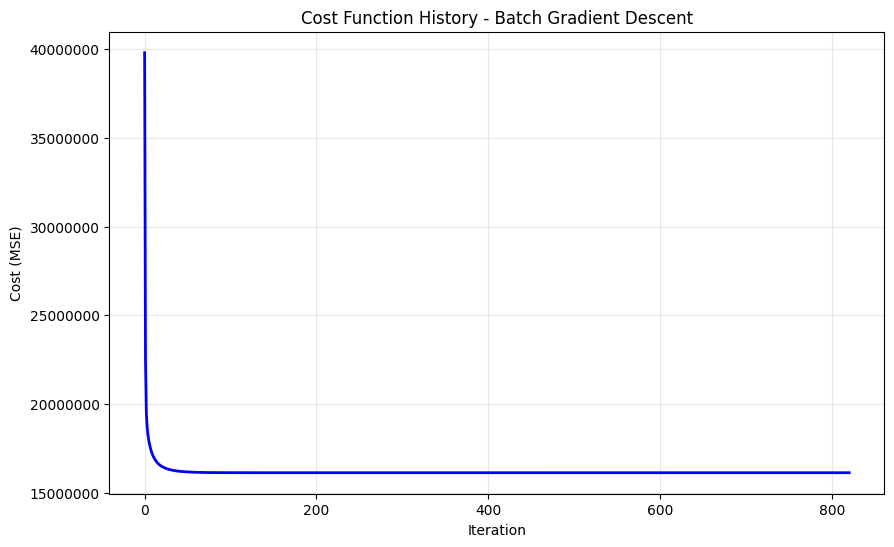


Convergence Analysis:
Initial Cost: 39798230.491446
Final Cost: 16118599.422945
Cost Reduction: 23679631.068502
Iterations Used: 821
Convergence Ratio: 59.50%

STEP 3: FINAL EVALUATION ON TEST SET

FINAL MODEL PERFORMANCE:
R² Score: 0.7603
MSE: 34192182.2152
RMSE: 5847.4082
MAE: 3937.3105
Optimal Learning Rate: 0.96
Final Iterations: 821


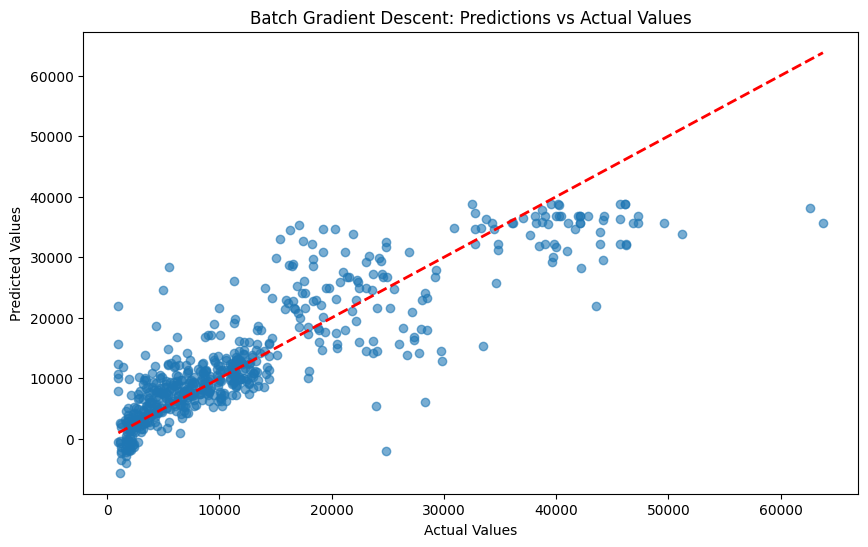

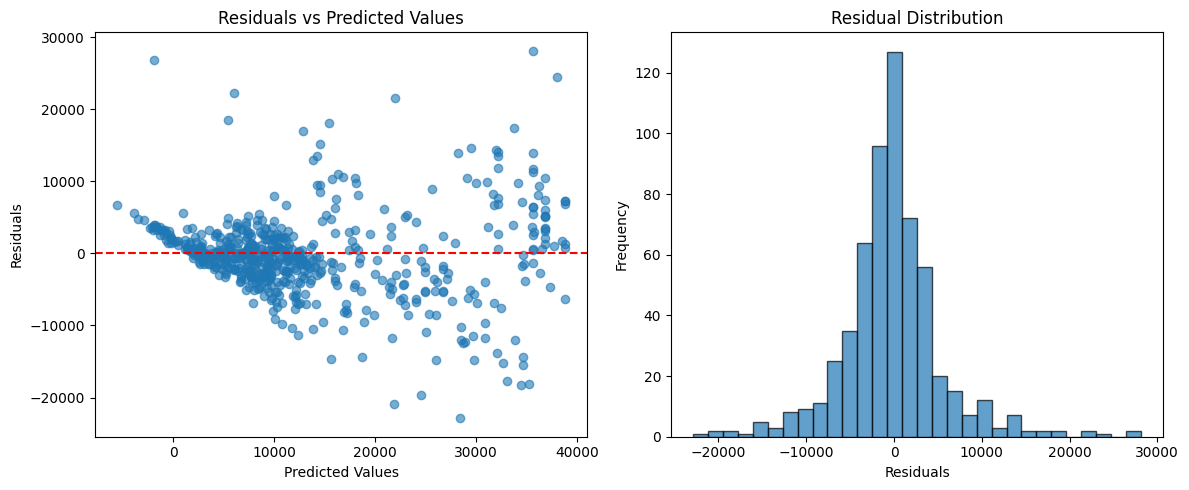

In [205]:
model, metrics, best_lr = run_batch_gradient_descent_regression(df_reduced, target ,learning_rates=np.round(np.arange(0.01,1,0.05),2))

### Implementation 2 (with out income (USD))

Checking for NaN values in the dataset...
No NaN values found in the dataset.
Data Preparation Complete:
Training set: (1775, 14)
Validation set: (592, 14)
Test set: (592, 14)

STEP 1: FINDING OPTIMAL LEARNING RATE
✓ Learning Rate: 0.0100 | MSE: 45596777.0260 | R²: 0.6548 | Converged: False | Iterations: 1000
✓ Learning Rate: 0.0600 | MSE: 43372250.8147 | R²: 0.6717 | Converged: False | Iterations: 1000
✓ Learning Rate: 0.1100 | MSE: 43312537.3814 | R²: 0.6721 | Converged: False | Iterations: 1000
✓ Learning Rate: 0.1600 | MSE: 43315247.1736 | R²: 0.6721 | Converged: False | Iterations: 1000
✓ Learning Rate: 0.2100 | MSE: 43322008.3374 | R²: 0.6720 | Converged: False | Iterations: 1000
✓ Learning Rate: 0.2600 | MSE: 43327431.1905 | R²: 0.6720 | Converged: False | Iterations: 1000
✓ Learning Rate: 0.3100 | MSE: 43331021.3923 | R²: 0.6720 | Converged: False | Iterations: 1000
✓ Learning Rate: 0.3600 | MSE: 43333213.8252 | R²: 0.6720 | Converged: False | Iterations: 1000
✓ Learning Rate: 

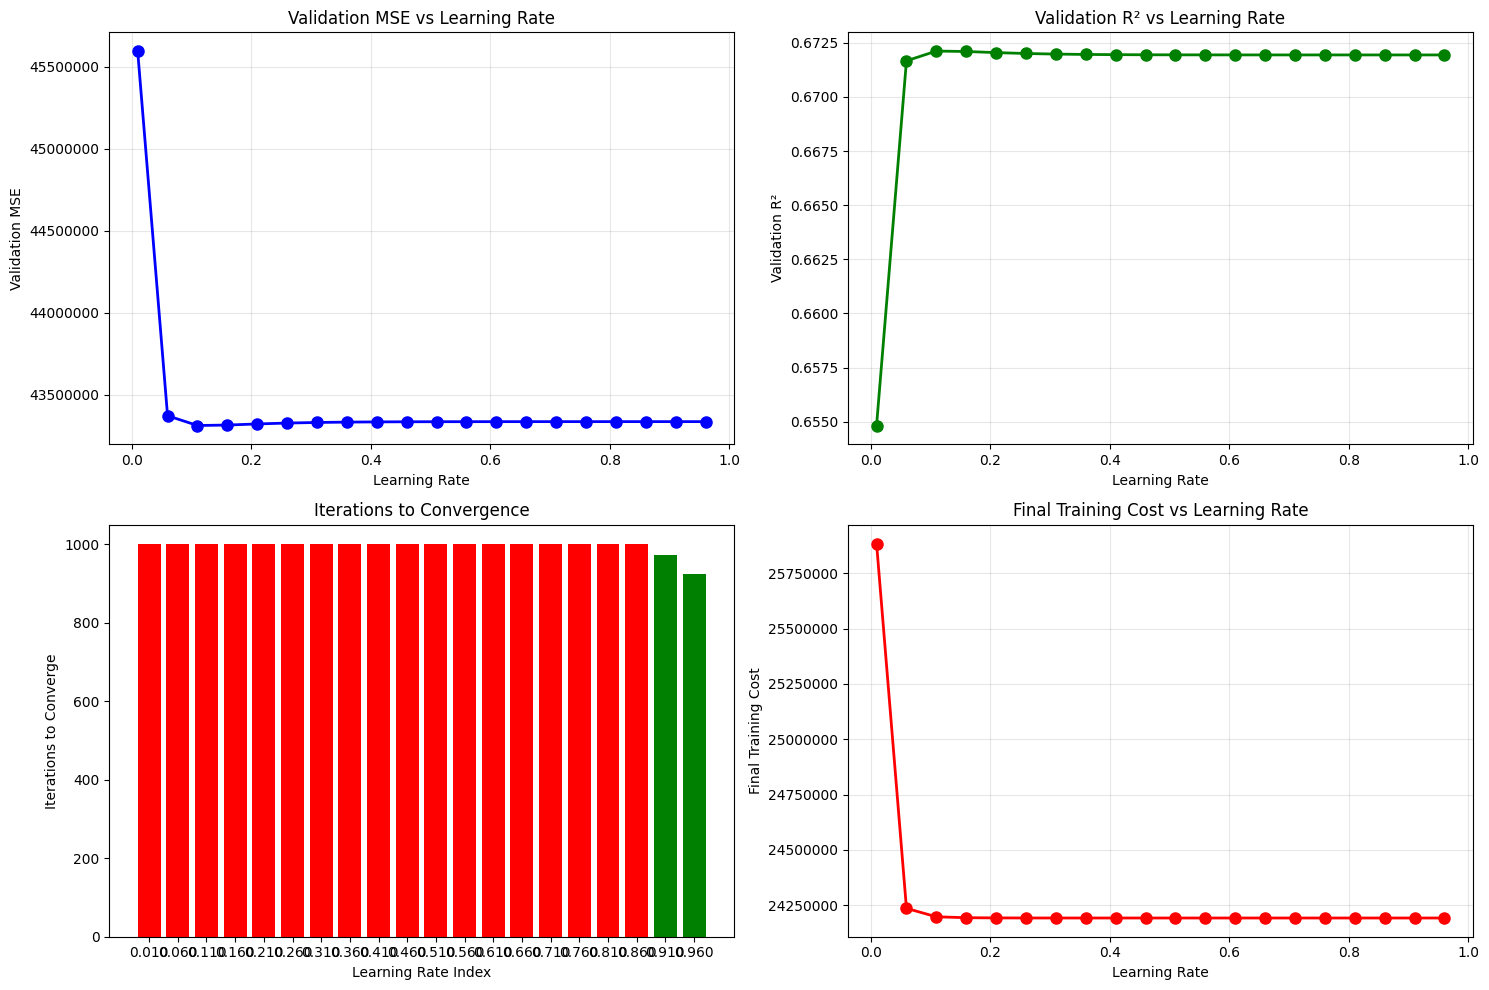


Optimal Learning Rate: 0.11

STEP 2: CONVERGENCE ANALYSIS WITH OPTIMAL LEARNING RATE
Training model with learning rate: 0.11
Iteration 0: Cost = 136670465.781551
Iteration 100: Cost = 25631233.265848
Iteration 200: Cost = 24655090.662713
Iteration 300: Cost = 24402164.282893
Iteration 400: Cost = 24298039.260601
Iteration 500: Cost = 24248489.701870
Iteration 600: Cost = 24223655.008541
Iteration 700: Cost = 24210721.150474
Iteration 800: Cost = 24203690.488533
Iteration 900: Cost = 24199672.890026
Iteration 1000: Cost = 24197248.289607
Iteration 1100: Cost = 24195703.473971
Iteration 1200: Cost = 24194669.890792
Iteration 1300: Cost = 24193949.934933
Iteration 1400: Cost = 24193432.742677
Iteration 1500: Cost = 24193052.823228
Iteration 1600: Cost = 24192769.363508
Iteration 1700: Cost = 24192555.616652
Iteration 1800: Cost = 24192393.280470
Iteration 1900: Cost = 24192269.394608
Training completed. Final cost: 24192175.372881


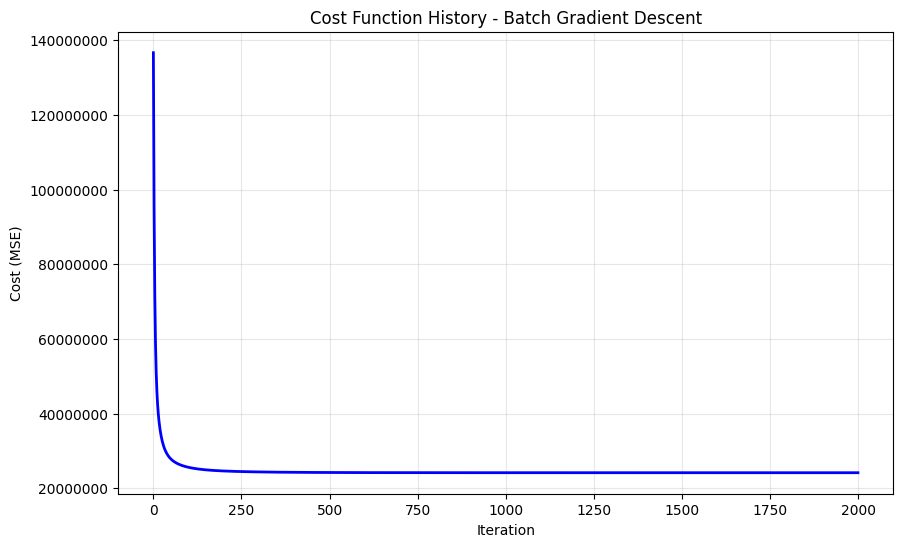


Convergence Analysis:
Initial Cost: 136670465.781551
Final Cost: 24192175.372881
Cost Reduction: 112478290.408670
Iterations Used: 2000
Convergence Ratio: 82.30%

STEP 3: FINAL EVALUATION ON TEST SET

FINAL MODEL PERFORMANCE:
R² Score: 0.6502
MSE: 49899154.5687
RMSE: 7063.9334
MAE: 5298.4469
Optimal Learning Rate: 0.11
Final Iterations: 2000


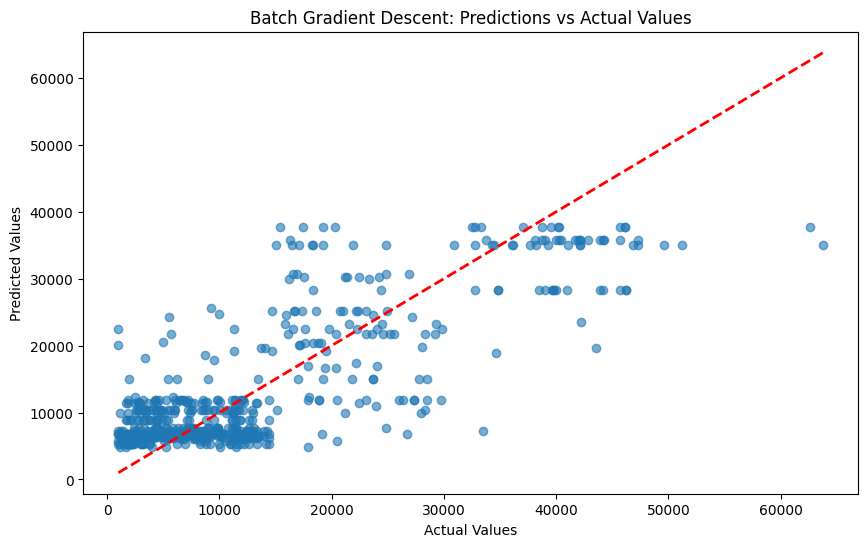

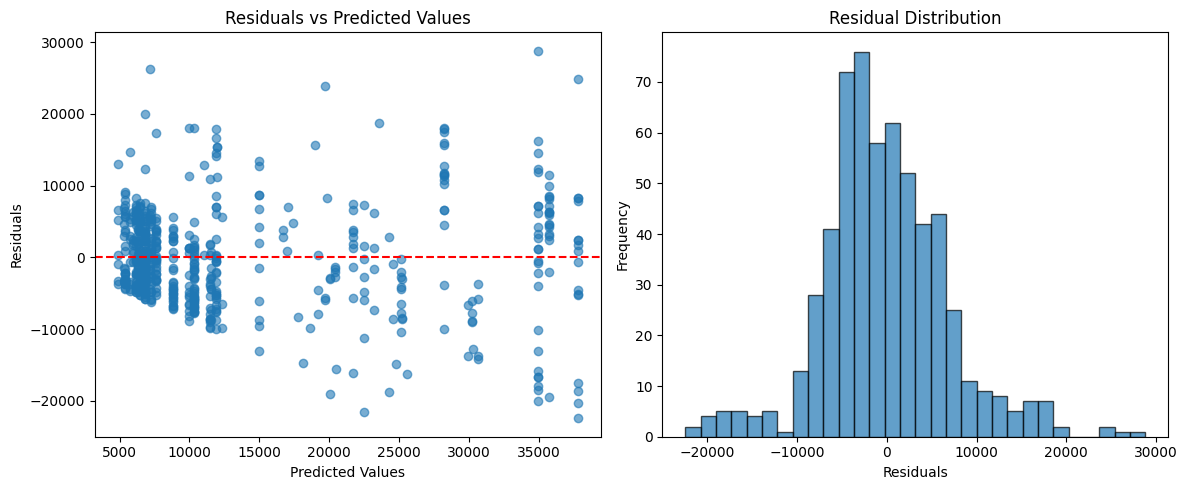

In [245]:
model, metrics, best_lr = run_batch_gradient_descent_regression(df_reduced_wo_income, target ,learning_rates=np.round(np.arange(0.01,1,0.05),2))

## c) Linear Regression (Mini-Batch Gradient Descent)

### Code

In [207]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

class MiniBatchGradientDescentLinearRegression:
    """
    Linear Regression implementation using Mini-Batch Gradient Descent
    """
    
    def __init__(self, learning_rate=0.01, n_iterations=1000, batch_size=32, 
                 random_state=42, shuffle=True):
        """
        Initialize the Mini-Batch Gradient Descent Linear Regression model
        
        Args:
            learning_rate (float): Step size for gradient descent (default: 0.01)
            n_iterations (int): Maximum number of iterations (default: 1000)
            batch_size (int): Size of mini-batches (power of 2, max 128)
            random_state (int): Random seed for reproducibility (default: 42)
            shuffle (bool): Whether to shuffle data before batching (default: True)
        """
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.batch_size = batch_size
        self.random_state = random_state
        self.shuffle = shuffle
        self.weights = None
        self.bias = None
        self.cost_history = []
        self.is_trained = False
        
        # Validate batch size
        self._validate_batch_size()
    
    def _validate_batch_size(self):
        """Validate that batch size is a power of 2 and <= 128"""
        if self.batch_size > 128:
            raise ValueError("Batch size must be <= 128")
        if not (self.batch_size & (self.batch_size - 1) == 0) and self.batch_size != 0:
            raise ValueError("Batch size must be a power of 2")
    
    def _create_mini_batches(self, X, y):
        """
        Create mini-batches from the dataset
        
        Args:
            X: Feature matrix
            y: Target vector
            
        Returns:
            list: List of mini-batches as (X_batch, y_batch) tuples
        """
        n_samples = X.shape[0]
        indices = np.arange(n_samples)
        
        if self.shuffle:
            np.random.shuffle(indices)
        
        mini_batches = []
        
        for i in range(0, n_samples, self.batch_size):
            batch_indices = indices[i:i + self.batch_size]
            X_batch = X[batch_indices]
            y_batch = y[batch_indices]
            mini_batches.append((X_batch, y_batch))
        
        return mini_batches
    
    def _compute_cost(self, X, y):
        """
        Compute the Mean Squared Error cost function
        
        Args:
            X: Feature matrix
            y: Target vector
            
        Returns:
            float: MSE cost
        """
        predictions = X.dot(self.weights) + self.bias
        errors = predictions - y
        cost = (1 / (2 * len(y))) * np.sum(errors ** 2)
        return cost
    
    def _compute_gradients(self, X_batch, y_batch):
        """
        Compute gradients for weights and bias on a mini-batch
        
        Args:
            X_batch: Mini-batch features
            y_batch: Mini-batch targets
            
        Returns:
            tuple: (weight_gradients, bias_gradient)
        """
        predictions = X_batch.dot(self.weights) + self.bias
        errors = predictions - y_batch
        
        # Compute gradients
        dw = (1 / len(y_batch)) * X_batch.T.dot(errors)
        db = (1 / len(y_batch)) * np.sum(errors)
        
        return dw, db
    
    def fit(self, X, y, verbose=False, early_stopping=True, tolerance=1e-6):
        """
        Train the model using Mini-Batch Gradient Descent
        
        Args:
            X: Feature matrix
            y: Target vector
            verbose (bool): Whether to print progress (default: False)
            early_stopping (bool): Whether to stop early if convergence is reached
            tolerance (float): Convergence tolerance (default: 1e-6)
        """
        # Initialize parameters
        np.random.seed(self.random_state)
        self.weights = np.random.randn(X.shape[1])
        self.bias = np.random.randn()
        
        self.cost_history = []
        n_samples = X.shape[0]
        n_batches = int(np.ceil(n_samples / self.batch_size))
        
        print(f"Training with batch size: {self.batch_size}, number of batches: {n_batches}")
        
        for i in range(self.n_iterations):
            # Create mini-batches for this epoch
            mini_batches = self._create_mini_batches(X, y)
            epoch_cost = 0
            
            for X_batch, y_batch in mini_batches:
                # Compute gradients on current mini-batch
                dw, db = self._compute_gradients(X_batch, y_batch)
                
                # Update parameters
                self.weights -= self.learning_rate * dw
                self.bias -= self.learning_rate * db
                
                # Compute cost for this mini-batch
                batch_cost = self._compute_cost(X_batch, y_batch)
                epoch_cost += batch_cost
            
            # Average cost over all batches in this epoch
            epoch_cost /= n_batches
            self.cost_history.append(epoch_cost)
            
            # Print progress every 100 iterations
            if verbose and i % 100 == 0:
                print(f"Iteration {i}: Cost = {epoch_cost:.6f}")
            
            # Early stopping check
            if early_stopping and i > 0:
                cost_change = abs(self.cost_history[-2] - epoch_cost)
                if cost_change < tolerance:
                    if verbose:
                        print(f"Convergence reached at iteration {i}")
                    break
        
        self.is_trained = True
        if verbose:
            print(f"Training completed. Final cost: {epoch_cost:.6f}")
    
    def predict(self, X):
        """
        Make predictions using the trained model
        
        Args:
            X: Feature matrix
            
        Returns:
            array: Predictions
        """
        if not self.is_trained:
            raise ValueError("Model must be trained before making predictions")
        return X.dot(self.weights) + self.bias
    
    def get_parameters(self):
        """
        Get model parameters
        
        Returns:
            dict: Model weights and bias
        """
        if not self.is_trained:
            raise ValueError("Model must be trained before accessing parameters")
        return {'weights': self.weights, 'bias': self.bias}
    
    def plot_cost_history(self, figsize=(10, 6)):
        """
        Plot the cost function history during training
        """
        if not self.is_trained:
            raise ValueError("Model must be trained before plotting")
        
        plt.figure(figsize=figsize)
        plt.plot(range(len(self.cost_history)), self.cost_history, 'b-', linewidth=2)
        plt.xlabel('Iteration (Epoch)')
        plt.ylabel('Cost (MSE)')
        plt.title(f'Cost Function History - Mini-Batch GD (batch_size={self.batch_size})')
        plt.grid(True, alpha=0.3)
        
        # Disable scientific notation on Y-axis
        plt.ticklabel_format(style='plain', axis='y')
        
        plt.show()

def find_optimal_learning_rate_mb(X_train, y_train, X_val, y_val, batch_size=32,
                                 learning_rates=[0.001, 0.01, 0.1, 0.5, 1.0], 
                                 n_iterations=1000, plot_results=True):
    """
    Find the optimal learning rate for Mini-Batch Gradient Descent
    
    Args:
        X_train: Training features
        y_train: Training targets
        X_val: Validation features
        y_val: Validation targets
        batch_size (int): Batch size to use
        learning_rates (list): List of learning rates to test
        n_iterations (int): Number of iterations for each run
        plot_results (bool): Whether to plot the results
        
    Returns:
        tuple: (best_learning_rate, results_df)
    """
    results = []
    
    for lr in learning_rates:
        # Train model with current learning rate
        model = MiniBatchGradientDescentLinearRegression(
            learning_rate=lr, 
            n_iterations=n_iterations,
            batch_size=batch_size,
            random_state=42
        )
        model.fit(X_train, y_train, verbose=False)
        
        # Make predictions and calculate metrics
        y_pred = model.predict(X_val)
        mse = mean_squared_error(y_val, y_pred)
        r2 = r2_score(y_val, y_pred)
        
        # Check if model converged
        converged = len(model.cost_history) < n_iterations or (
            len(model.cost_history) >= 2 and 
            abs(model.cost_history[-1] - model.cost_history[-2]) < 1e-6
        )
        
        results.append({
            'learning_rate': lr,
            'mse': mse,
            'r2': r2,
            'final_cost': model.cost_history[-1],
            'iterations_to_converge': len(model.cost_history),
            'converged': converged
        })
        
        print(f"Learning Rate: {lr:.4f} | MSE: {mse:.4f} | R²: {r2:.4f} | "
              f"Converged: {converged} | Iterations: {len(model.cost_history)}")
    
    # Create results DataFrame
    results_df = pd.DataFrame(results)
    best_lr = results_df.loc[results_df['mse'].idxmin(), 'learning_rate']
    
    if plot_results:
        fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(15, 10))
        
        # Plot 1: MSE vs Learning Rate
        ax1.plot(results_df['learning_rate'], results_df['mse'], 'bo-', linewidth=2, markersize=8)
        ax1.set_xlabel('Learning Rate')
        ax1.set_ylabel('Validation MSE')
        ax1.set_title(f'Validation MSE vs Learning Rate (batch_size={batch_size})')
        ax1.grid(True, alpha=0.3)
        ax1.ticklabel_format(style='plain', axis='y')
        
        # Plot 2: R² vs Learning Rate
        ax2.plot(results_df['learning_rate'], results_df['r2'], 'go-', linewidth=2, markersize=8)
        ax2.set_xlabel('Learning Rate')
        ax2.set_ylabel('Validation R²')
        ax2.set_title(f'Validation R² vs Learning Rate (batch_size={batch_size})')
        ax2.grid(True, alpha=0.3)
        ax2.ticklabel_format(style='plain', axis='y')
        
        # Plot 3: Iterations to Converge
        ax3.bar(range(len(results_df)), results_df['iterations_to_converge'], 
               color=['green' if conv else 'red' for conv in results_df['converged']])
        ax3.set_xlabel('Learning Rate Index')
        ax3.set_ylabel('Iterations to Converge')
        ax3.set_title(f'Iterations to Convergence (batch_size={batch_size})')
        ax3.set_xticks(range(len(results_df)))
        ax3.set_xticklabels([f'{lr:.3f}' for lr in results_df['learning_rate']])
        ax3.ticklabel_format(style='plain', axis='y')
        
        # Plot 4: Final Cost
        ax4.plot(results_df['learning_rate'], results_df['final_cost'], 'ro-', linewidth=2, markersize=8)
        ax4.set_xlabel('Learning Rate')
        ax4.set_ylabel('Final Training Cost')
        ax4.set_title(f'Final Training Cost vs Learning Rate (batch_size={batch_size})')
        ax4.grid(True, alpha=0.3)
        ax4.ticklabel_format(style='plain', axis='y')
        
        plt.tight_layout()
        plt.show()
    
    print(f"\nOptimal Learning Rate: {best_lr}")
    return best_lr, results_df

def compare_batch_sizes(X_train, y_train, X_val, y_val, batch_sizes=[16, 32, 64, 128],
                       learning_rate=0.01, n_iterations=1000, plot_results=True):
    """
    Compare performance across different batch sizes
    
    Args:
        X_train: Training features
        y_train: Training targets
        X_val: Validation features
        y_val: Validation targets
        batch_sizes (list): List of batch sizes to compare
        learning_rate (float): Learning rate to use
        n_iterations (int): Number of iterations
        plot_results (bool): Whether to plot comparison
        
    Returns:
        pd.DataFrame: Comparison results
    """
    results = []
    
    for batch_size in batch_sizes:
        print(f"\nTesting batch size: {batch_size}")
        
        # Train model with current batch size
        model = MiniBatchGradientDescentLinearRegression(
            learning_rate=learning_rate,
            n_iterations=n_iterations,
            batch_size=batch_size,
            random_state=42
        )
        model.fit(X_train, y_train, verbose=False)
        
        # Make predictions and calculate metrics
        y_pred = model.predict(X_val)
        mse = mean_squared_error(y_val, y_pred)
        r2 = r2_score(y_val, y_pred)
        
        # Calculate training time (approximate with iterations to converge)
        iterations_used = len(model.cost_history)
        
        results.append({
            'batch_size': batch_size,
            'mse': mse,
            'r2': r2,
            'iterations_to_converge': iterations_used,
            'final_cost': model.cost_history[-1],
            'convergence_speed': iterations_used / n_iterations  # Lower is faster
        })
        
        print(f"Batch Size: {batch_size} | MSE: {mse:.4f} | R²: {r2:.4f} | "
              f"Iterations: {iterations_used}")
    
    results_df = pd.DataFrame(results)
    
    if plot_results:
        fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(15, 10))
        
        # Plot 1: MSE vs Batch Size
        ax1.plot(results_df['batch_size'], results_df['mse'], 'bo-', linewidth=2, markersize=8)
        ax1.set_xlabel('Batch Size')
        ax1.set_ylabel('Validation MSE')
        ax1.set_title('Validation MSE vs Batch Size')
        ax1.grid(True, alpha=0.3)
        ax1.ticklabel_format(style='plain', axis='y')
        
        # Plot 2: R² vs Batch Size
        ax2.plot(results_df['batch_size'], results_df['r2'], 'go-', linewidth=2, markersize=8)
        ax2.set_xlabel('Batch Size')
        ax2.set_ylabel('Validation R²')
        ax2.set_title('Validation R² vs Batch Size')
        ax2.grid(True, alpha=0.3)
        ax2.ticklabel_format(style='plain', axis='y')
        
        # Plot 3: Iterations to Converge vs Batch Size
        ax3.bar(results_df['batch_size'], results_df['iterations_to_converge'], 
               color='orange', alpha=0.7)
        ax3.set_xlabel('Batch Size')
        ax3.set_ylabel('Iterations to Converge')
        ax3.set_title('Convergence Speed vs Batch Size')
        ax3.ticklabel_format(style='plain', axis='y')
        
        # Plot 4: Final Cost vs Batch Size
        ax4.plot(results_df['batch_size'], results_df['final_cost'], 'ro-', linewidth=2, markersize=8)
        ax4.set_xlabel('Batch Size')
        ax4.set_ylabel('Final Training Cost')
        ax4.set_title('Final Training Cost vs Batch Size')
        ax4.grid(True, alpha=0.3)
        ax4.ticklabel_format(style='plain', axis='y')
        
        plt.tight_layout()
        plt.show()
    
    return results_df

def analyze_convergence_mb(X_train, y_train, optimal_learning_rate, batch_size=32, max_iterations=2000):
    """
    Analyze convergence behavior with optimal learning rate and batch size
    """
    # Train model with optimal parameters
    model = MiniBatchGradientDescentLinearRegression(
        learning_rate=optimal_learning_rate,
        n_iterations=max_iterations,
        batch_size=batch_size,
        random_state=42
    )
    
    print(f"Training model with learning rate: {optimal_learning_rate}, batch size: {batch_size}")
    model.fit(X_train, y_train, verbose=True)
    
    # Plot cost history
    model.plot_cost_history()
    
    # Analyze convergence
    final_cost = model.cost_history[-1]
    cost_reduction = model.cost_history[0] - final_cost
    iterations_used = len(model.cost_history)
    
    print(f"\nConvergence Analysis:")
    print(f"Initial Cost: {model.cost_history[0]:.6f}")
    print(f"Final Cost: {final_cost:.6f}")
    print(f"Cost Reduction: {cost_reduction:.6f}")
    print(f"Iterations Used: {iterations_used}")
    print(f"Convergence Ratio: {cost_reduction / model.cost_history[0] * 100:.2f}%")
    
    return model

def run_mini_batch_gradient_descent_regression(df, target_column, test_size=0.2, val_size=0.2, 
                                             random_state=42, learning_rates=None,
                                             batch_sizes=None):
    """
    Complete pipeline for Mini-Batch Gradient Descent Linear Regression
    
    Args:
        df (pd.DataFrame): Input DataFrame (should be encoded and scaled)
        target_column (str): Name of target column
        test_size (float): Percentage for test set
        val_size (float): Percentage for validation set (from training data)
        random_state (int): Random seed
        learning_rates (list): List of learning rates to test
        batch_sizes (list): List of batch sizes to test (powers of 2, max 128)
        
    Returns:
        tuple: (trained_model, evaluation_metrics, optimal_learning_rate, optimal_batch_size)
    """
    if learning_rates is None:
        learning_rates = [0.001, 0.005, 0.01, 0.05, 0.1, 0.5, 1.0]
    
    if batch_sizes is None:
        batch_sizes = [16, 32, 64, 128]
    
    # Prepare data
    X = df.drop(columns=[target_column]).values
    y = df[target_column].values
    
    # Split data
    X_temp, X_test, y_temp, y_test = train_test_split(
        X, y, test_size=test_size, random_state=random_state
    )
    
    val_size_adj = val_size / (1 - test_size)
    X_train, X_val, y_train, y_val = train_test_split(
        X_temp, y_temp, test_size=val_size_adj, random_state=random_state
    )
    
    print("Data Preparation Complete:")
    print(f"Training set: {X_train.shape}")
    print(f"Validation set: {X_val.shape}")
    print(f"Test set: {X_test.shape}")
    
    # Step 1: Compare different batch sizes
    print("\n" + "="*70)
    print("STEP 1: COMPARING DIFFERENT BATCH SIZES")
    print("="*70)
    
    batch_comparison = compare_batch_sizes(
        X_train, y_train, X_val, y_val,
        batch_sizes=batch_sizes,
        learning_rate=0.01,  # Default learning rate for batch size comparison
        n_iterations=1000
    )
    
    # Select best batch size (lowest MSE)
    optimal_batch_size = batch_comparison.loc[batch_comparison['mse'].idxmin(), 'batch_size']
    print(f"\nOptimal Batch Size: {optimal_batch_size}")
    
    # Step 2: Find optimal learning rate for best batch size
    print("\n" + "="*70)
    print("STEP 2: FINDING OPTIMAL LEARNING RATE FOR BATCH SIZE", optimal_batch_size)
    print("="*70)
    
    optimal_lr, lr_results = find_optimal_learning_rate_mb(
        X_train, y_train, X_val, y_val,
        batch_size=optimal_batch_size,
        learning_rates=learning_rates,
        n_iterations=1000
    )
    
    # Step 3: Analyze convergence with optimal parameters
    print("\n" + "="*70)
    print("STEP 3: CONVERGENCE ANALYSIS WITH OPTIMAL PARAMETERS")
    print("="*70)
    
    final_model = analyze_convergence_mb(
        X_train, y_train, optimal_lr, optimal_batch_size, max_iterations=2000
    )
    
    # Step 4: Final evaluation on test set
    print("\n" + "="*70)
    print("STEP 4: FINAL EVALUATION ON TEST SET")
    print("="*70)
    
    y_pred = final_model.predict(X_test)
    
    metrics = {
        'mse': mean_squared_error(y_test, y_pred),
        'rmse': np.sqrt(mean_squared_error(y_test, y_pred)),
        'mae': mean_absolute_error(y_test, y_pred),
        'r2': r2_score(y_test, y_pred)
    }
    
    # Print results
    print("\nFINAL MODEL PERFORMANCE:")
    print(f"R² Score: {metrics['r2']:.4f}")
    print(f"MSE: {metrics['mse']:.4f}")
    print(f"RMSE: {metrics['rmse']:.4f}")
    print(f"MAE: {metrics['mae']:.4f}")
    print(f"Optimal Learning Rate: {optimal_lr}")
    print(f"Optimal Batch Size: {optimal_batch_size}")
    print(f"Final Iterations: {len(final_model.cost_history)}")
    
    # Plot predictions vs actual
    plt.figure(figsize=(10, 6))
    plt.scatter(y_test, y_pred, alpha=0.6)
    plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
    plt.xlabel('Actual Values')
    plt.ylabel('Predicted Values')
    plt.title(f'Mini-Batch GD: Predictions vs Actual (batch_size={optimal_batch_size})')
    plt.ticklabel_format(style='plain', axis='both')
    plt.show()
    
    # Plot residuals
    residuals = y_test - y_pred
    plt.figure(figsize=(12, 5))
    
    plt.subplot(1, 2, 1)
    plt.scatter(y_pred, residuals, alpha=0.6)
    plt.axhline(y=0, color='r', linestyle='--')
    plt.xlabel('Predicted Values')
    plt.ylabel('Residuals')
    plt.title('Residuals vs Predicted Values')
    plt.ticklabel_format(style='plain', axis='both')
    
    plt.subplot(1, 2, 2)
    plt.hist(residuals, bins=30, alpha=0.7, edgecolor='black')
    plt.xlabel('Residuals')
    plt.ylabel('Frequency')
    plt.title('Residual Distribution')
    plt.ticklabel_format(style='plain', axis='x')
    
    plt.tight_layout()
    plt.show()
    
    return final_model, metrics, optimal_lr, optimal_batch_size

### Implementation 1 (with income (USD))

Data Preparation Complete:
Training set: (1775, 15)
Validation set: (592, 15)
Test set: (592, 15)

STEP 1: COMPARING DIFFERENT BATCH SIZES

Testing batch size: 2
Training with batch size: 2, number of batches: 888
Batch Size: 2 | MSE: 30907670.6763 | R²: 0.7660 | Iterations: 1000

Testing batch size: 4
Training with batch size: 4, number of batches: 444
Batch Size: 4 | MSE: 30986158.1374 | R²: 0.7654 | Iterations: 1000

Testing batch size: 8
Training with batch size: 8, number of batches: 222
Batch Size: 8 | MSE: 30901979.4262 | R²: 0.7661 | Iterations: 1000

Testing batch size: 16
Training with batch size: 16, number of batches: 111
Batch Size: 16 | MSE: 30823393.8521 | R²: 0.7667 | Iterations: 1000

Testing batch size: 32
Training with batch size: 32, number of batches: 56
Batch Size: 32 | MSE: 30780120.1040 | R²: 0.7670 | Iterations: 1000

Testing batch size: 64
Training with batch size: 64, number of batches: 28
Batch Size: 64 | MSE: 30771234.5329 | R²: 0.7671 | Iterations: 1000

T

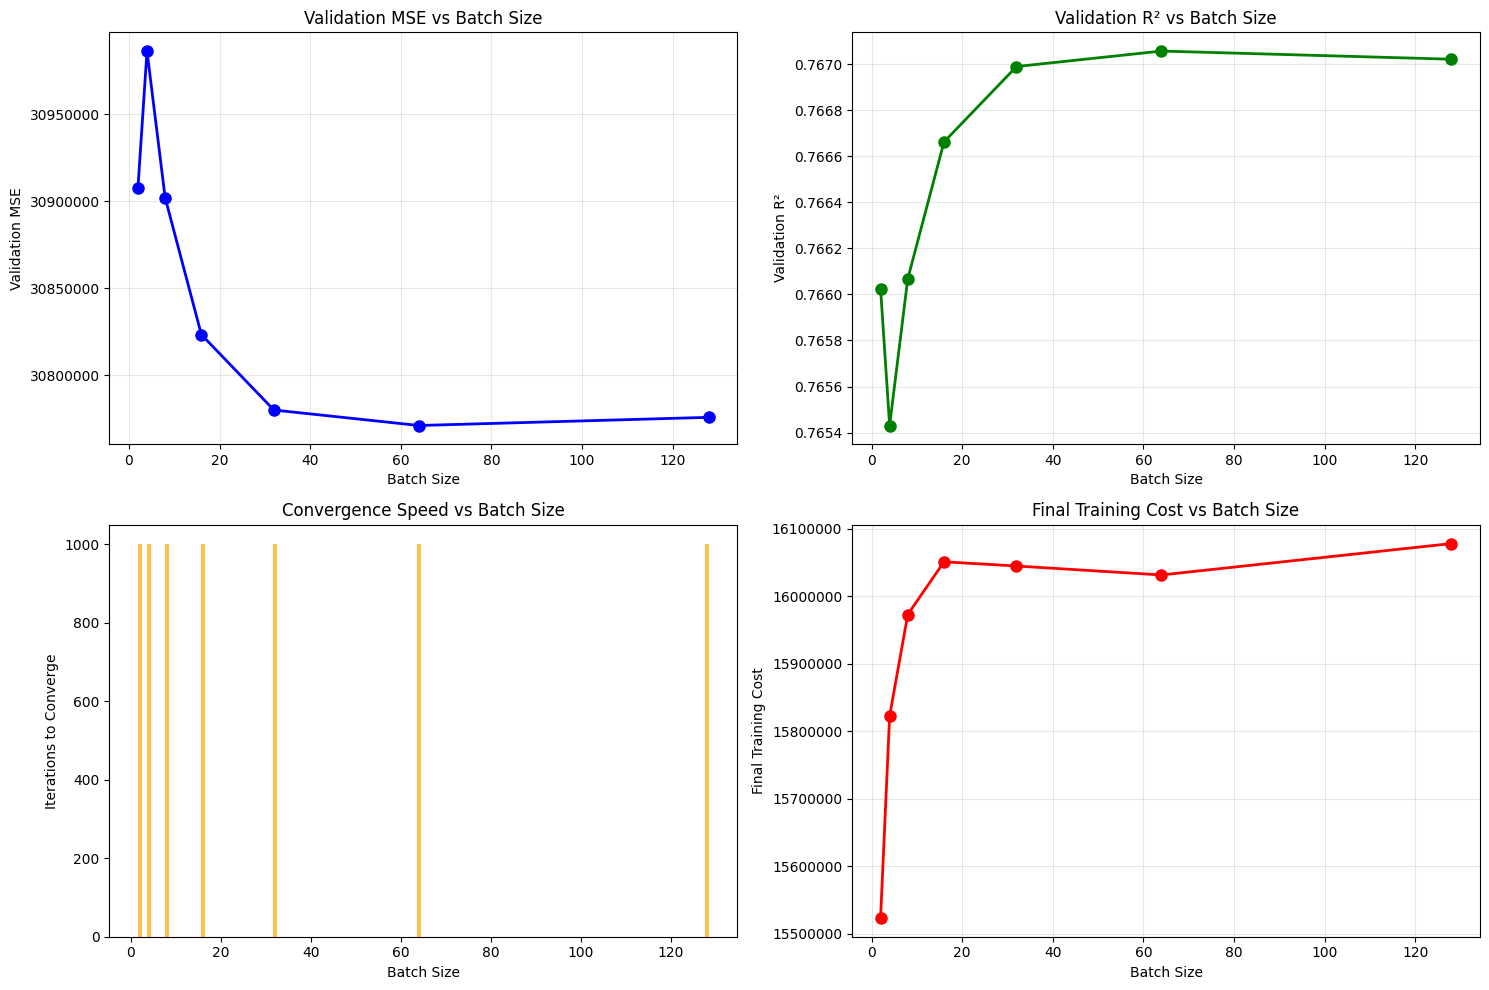


Optimal Batch Size: 64

STEP 2: FINDING OPTIMAL LEARNING RATE FOR BATCH SIZE 64
Training with batch size: 64, number of batches: 28
Learning Rate: 0.0100 | MSE: 30771234.5329 | R²: 0.7671 | Converged: False | Iterations: 1000
Training with batch size: 64, number of batches: 28
Learning Rate: 0.0600 | MSE: 30869320.1866 | R²: 0.7663 | Converged: False | Iterations: 1000
Training with batch size: 64, number of batches: 28
Learning Rate: 0.1100 | MSE: 30971029.4981 | R²: 0.7655 | Converged: False | Iterations: 1000
Training with batch size: 64, number of batches: 28
Learning Rate: 0.1600 | MSE: 31016785.3153 | R²: 0.7652 | Converged: False | Iterations: 1000
Training with batch size: 64, number of batches: 28
Learning Rate: 0.2100 | MSE: 31010293.3604 | R²: 0.7652 | Converged: False | Iterations: 1000
Training with batch size: 64, number of batches: 28
Learning Rate: 0.2600 | MSE: 30976802.8354 | R²: 0.7655 | Converged: False | Iterations: 1000
Training with batch size: 64, number of bat

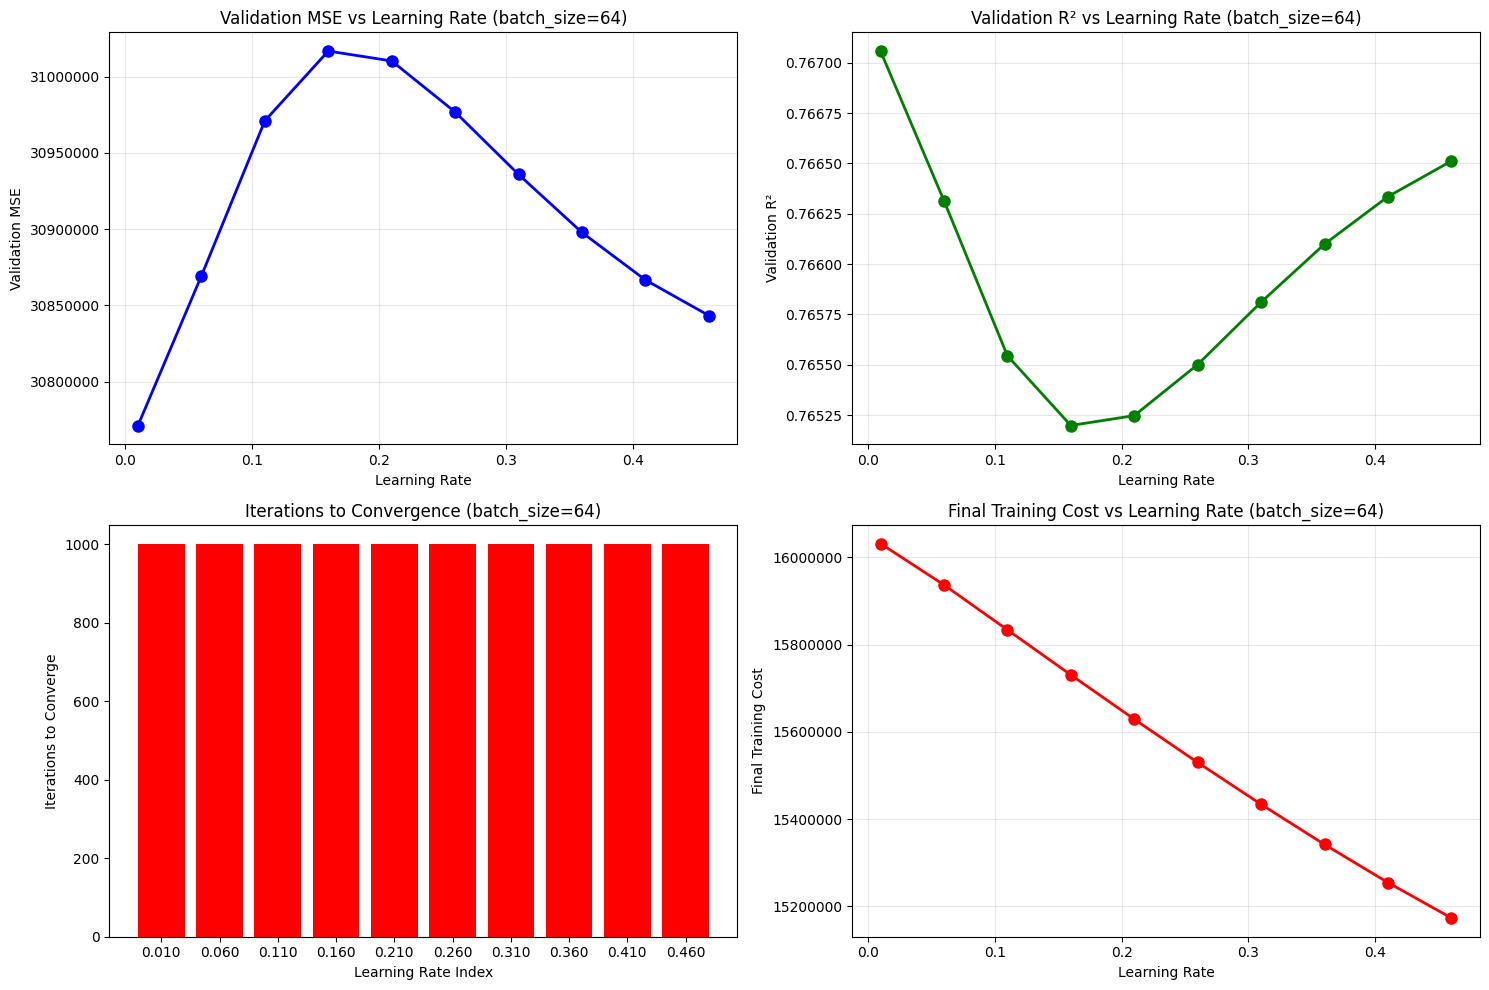


Optimal Learning Rate: 0.01

STEP 3: CONVERGENCE ANALYSIS WITH OPTIMAL PARAMETERS
Training model with learning rate: 0.01, batch size: 64
Training with batch size: 64, number of batches: 28
Iteration 0: Cost = 122150818.604878
Iteration 100: Cost = 16239332.382069
Iteration 200: Cost = 16158668.699938
Iteration 300: Cost = 16085568.350306
Iteration 400: Cost = 16088704.400962
Iteration 500: Cost = 16073252.661995
Iteration 600: Cost = 16030799.834437
Iteration 700: Cost = 16086325.480115
Iteration 800: Cost = 16139197.817787
Iteration 900: Cost = 16127286.827354
Iteration 1000: Cost = 16072791.463527
Iteration 1100: Cost = 16068373.283400
Iteration 1200: Cost = 16048055.520746
Iteration 1300: Cost = 16073706.269377
Iteration 1400: Cost = 16082822.644250
Iteration 1500: Cost = 16050448.673605
Iteration 1600: Cost = 16075985.759877
Iteration 1700: Cost = 16066151.762514
Iteration 1800: Cost = 16074244.835104
Iteration 1900: Cost = 16216891.833796
Training completed. Final cost: 16045541

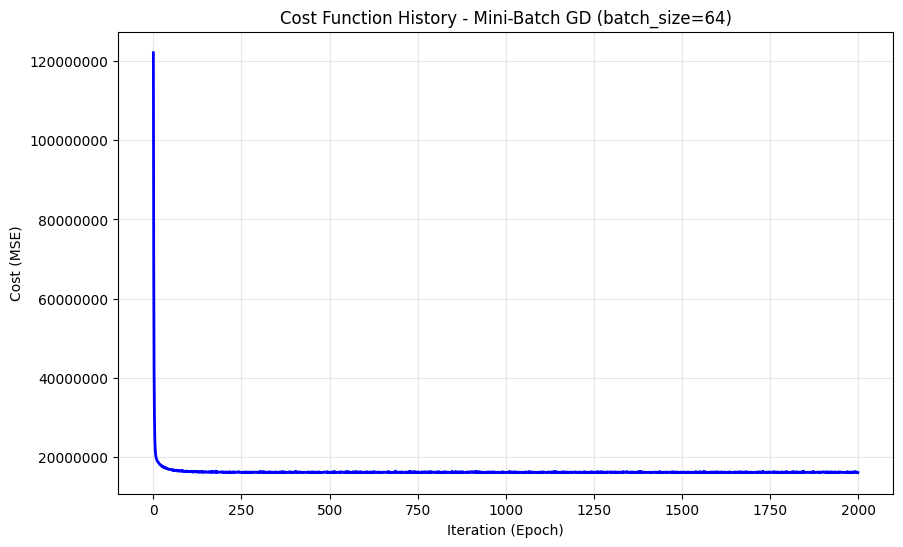


Convergence Analysis:
Initial Cost: 122150818.604878
Final Cost: 16045541.922702
Cost Reduction: 106105276.682176
Iterations Used: 2000
Convergence Ratio: 86.86%

STEP 4: FINAL EVALUATION ON TEST SET

FINAL MODEL PERFORMANCE:
R² Score: 0.7604
MSE: 34181447.3731
RMSE: 5846.4902
MAE: 3935.1150
Optimal Learning Rate: 0.01
Optimal Batch Size: 64
Final Iterations: 2000


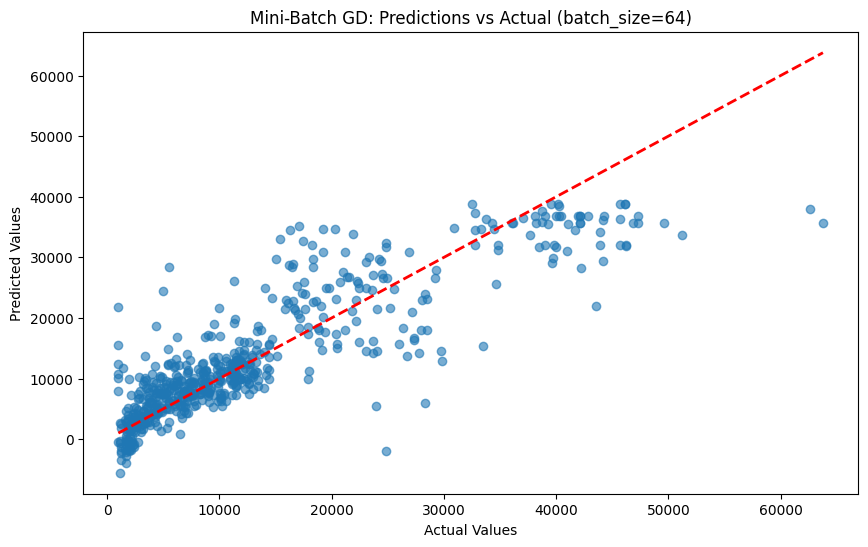

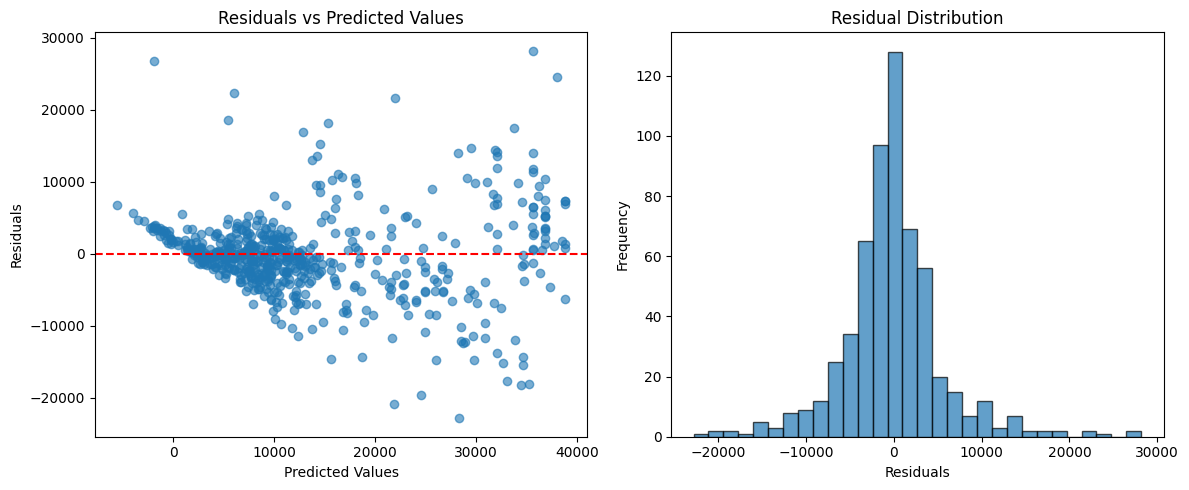

In [208]:
model, metrics, best_lr, best_batch_size = run_mini_batch_gradient_descent_regression(
    df_reduced,
    target,
    batch_sizes=[2**i for i in range(1, 8)],
    learning_rates=np.round(np.arange(0.01,0.5,0.05),2)
    )

### Implementation 2 (with out income (USD))

Data Preparation Complete:
Training set: (1775, 14)
Validation set: (592, 14)
Test set: (592, 14)

STEP 1: COMPARING DIFFERENT BATCH SIZES

Testing batch size: 2
Training with batch size: 2, number of batches: 888
Batch Size: 2 | MSE: 43344469.3238 | R²: 0.6719 | Iterations: 1000

Testing batch size: 4
Training with batch size: 4, number of batches: 444
Batch Size: 4 | MSE: 43370117.5175 | R²: 0.6717 | Iterations: 1000

Testing batch size: 8
Training with batch size: 8, number of batches: 222
Batch Size: 8 | MSE: 43354056.9917 | R²: 0.6718 | Iterations: 1000

Testing batch size: 16
Training with batch size: 16, number of batches: 111
Batch Size: 16 | MSE: 43340264.0437 | R²: 0.6719 | Iterations: 1000

Testing batch size: 32
Training with batch size: 32, number of batches: 56
Batch Size: 32 | MSE: 43333180.4166 | R²: 0.6720 | Iterations: 1000

Testing batch size: 64
Training with batch size: 64, number of batches: 28
Batch Size: 64 | MSE: 43325906.6043 | R²: 0.6720 | Iterations: 1000

T

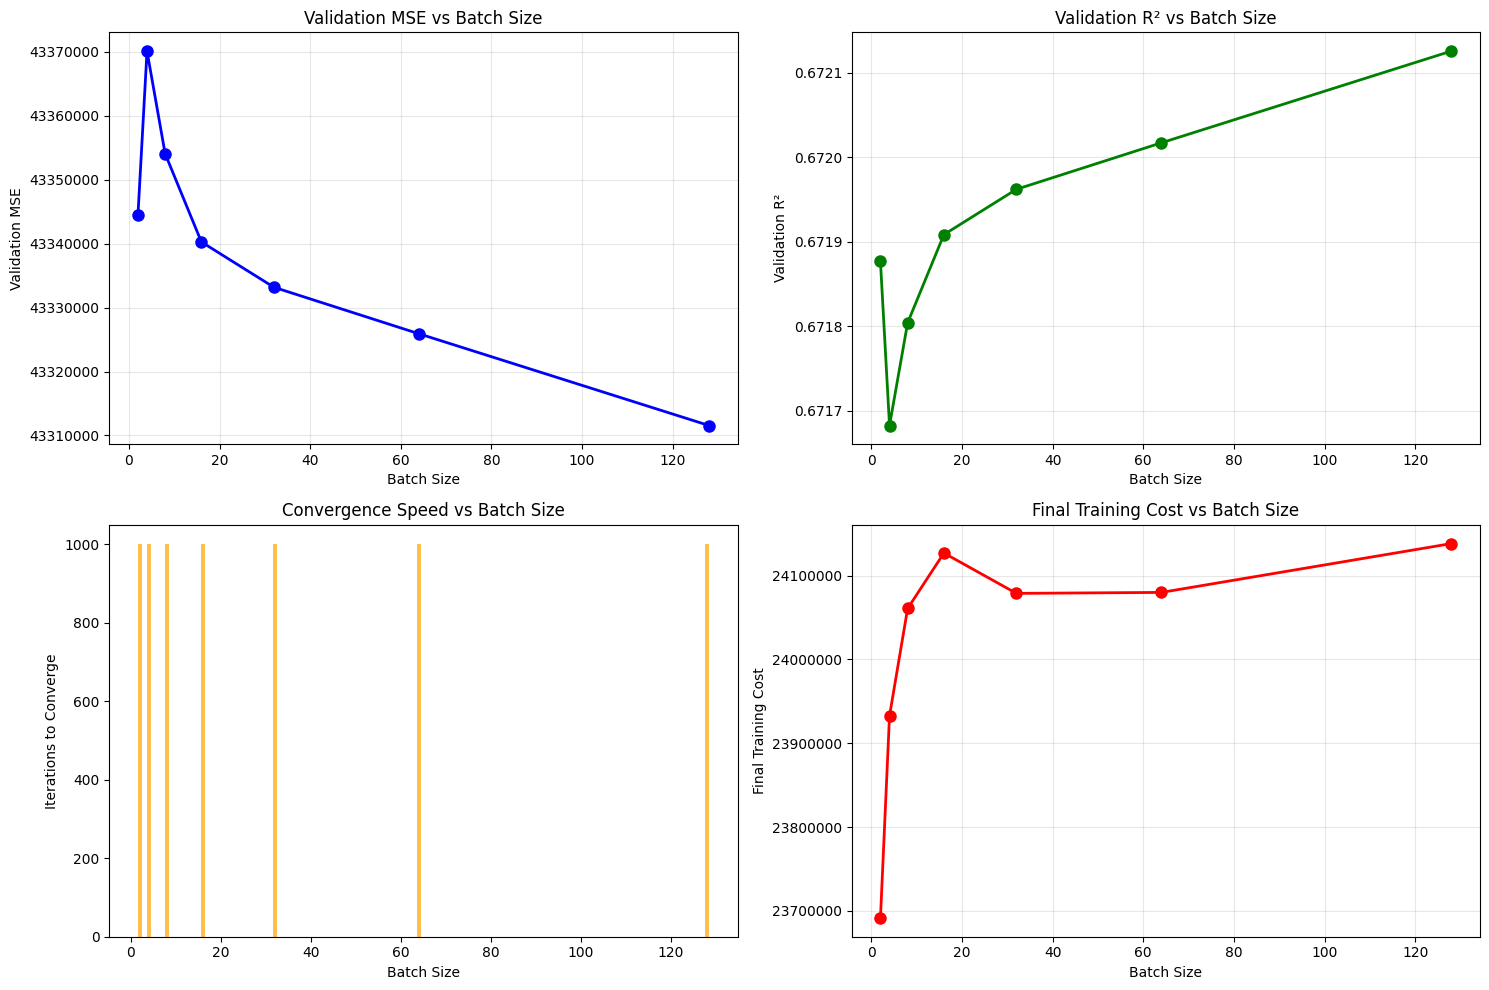


Optimal Batch Size: 128

STEP 2: FINDING OPTIMAL LEARNING RATE FOR BATCH SIZE 128
Training with batch size: 128, number of batches: 14
Learning Rate: 0.0100 | MSE: 43311559.3701 | R²: 0.6721 | Converged: False | Iterations: 1000
Training with batch size: 128, number of batches: 14
Learning Rate: 0.0600 | MSE: 43339264.9709 | R²: 0.6719 | Converged: False | Iterations: 1000
Training with batch size: 128, number of batches: 14
Learning Rate: 0.1100 | MSE: 43349025.8906 | R²: 0.6718 | Converged: False | Iterations: 1000
Training with batch size: 128, number of batches: 14
Learning Rate: 0.1600 | MSE: 43360611.8224 | R²: 0.6718 | Converged: False | Iterations: 1000
Training with batch size: 128, number of batches: 14
Learning Rate: 0.2100 | MSE: 43372189.6024 | R²: 0.6717 | Converged: False | Iterations: 1000
Training with batch size: 128, number of batches: 14
Learning Rate: 0.2600 | MSE: 43382917.1387 | R²: 0.6716 | Converged: False | Iterations: 1000
Training with batch size: 128, numb

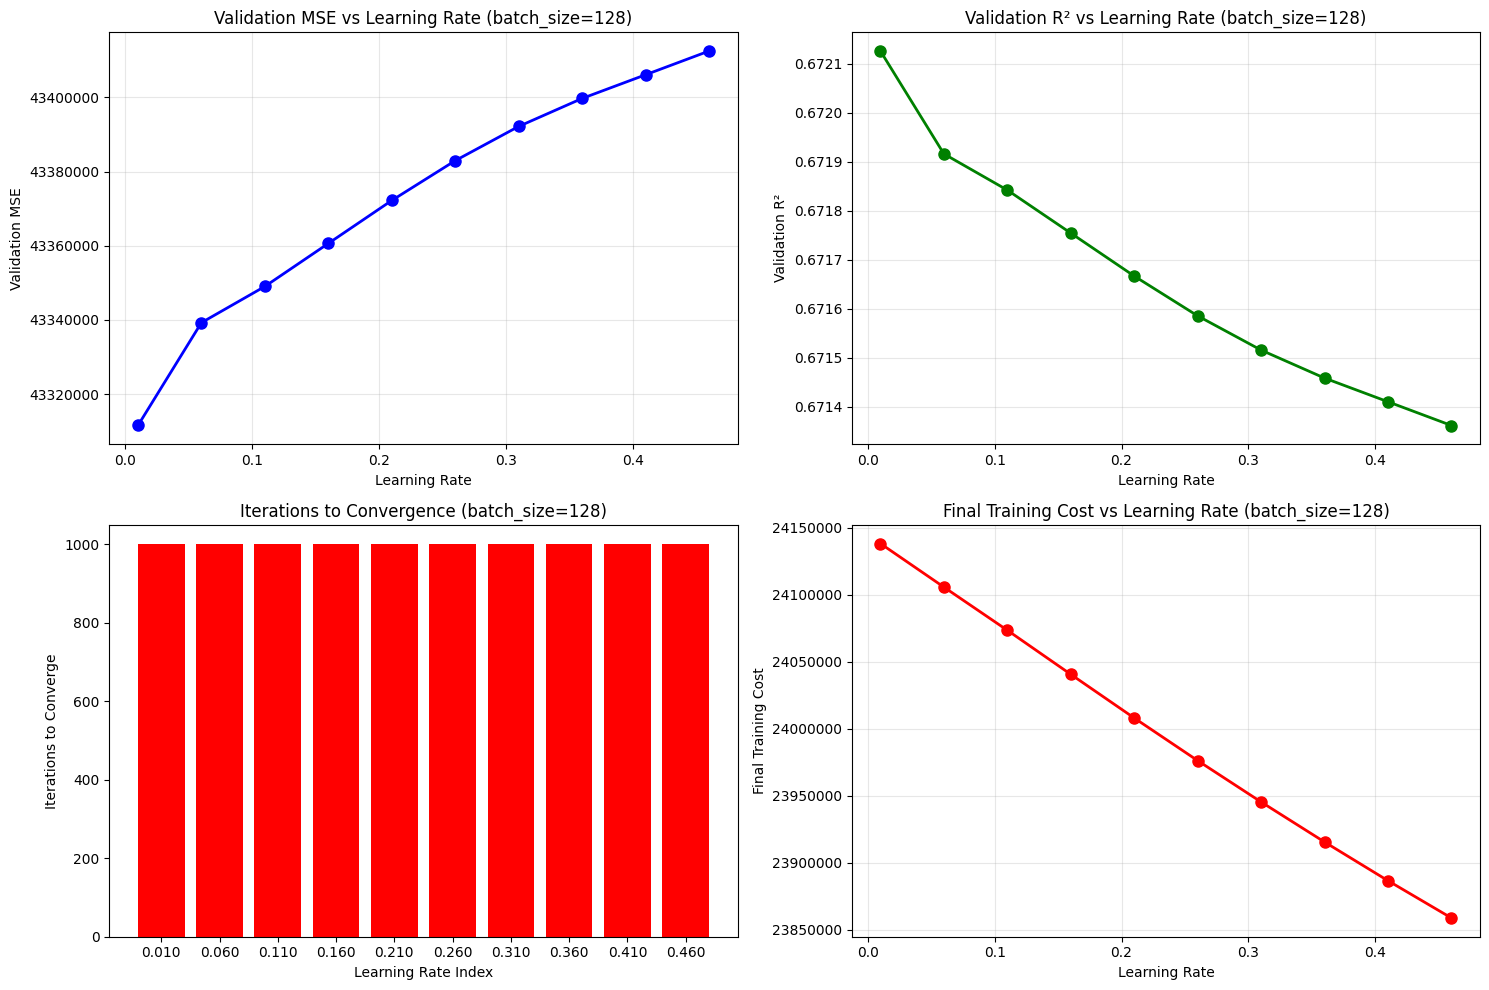


Optimal Learning Rate: 0.01

STEP 3: CONVERGENCE ANALYSIS WITH OPTIMAL PARAMETERS
Training model with learning rate: 0.01, batch size: 128
Training with batch size: 128, number of batches: 14
Iteration 0: Cost = 147850919.329696
Iteration 100: Cost = 25206990.171638
Iteration 200: Cost = 24492485.397682
Iteration 300: Cost = 24315524.699126
Iteration 400: Cost = 24270022.044278
Iteration 500: Cost = 24132945.474932
Iteration 600: Cost = 24164612.714083
Iteration 700: Cost = 24205408.596447
Iteration 800: Cost = 24190756.789073
Iteration 900: Cost = 24224811.139215
Iteration 1000: Cost = 24129645.811284
Iteration 1100: Cost = 24121671.636979
Iteration 1200: Cost = 24222370.421987
Iteration 1300: Cost = 24161352.797802
Iteration 1400: Cost = 24163612.851050
Iteration 1500: Cost = 24154320.074120
Iteration 1600: Cost = 24164821.655429
Iteration 1700: Cost = 24170295.789965
Iteration 1800: Cost = 24203868.237083
Iteration 1900: Cost = 24212875.854273
Training completed. Final cost: 241311

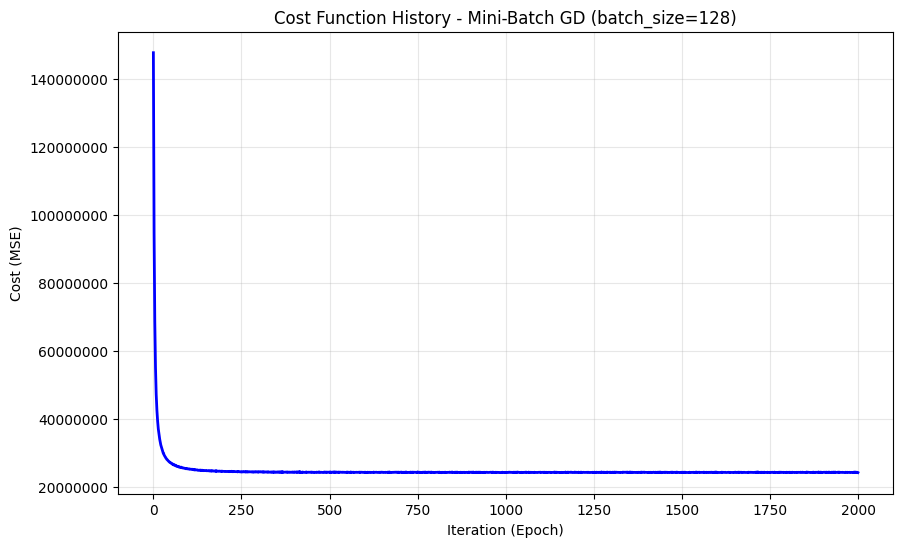


Convergence Analysis:
Initial Cost: 147850919.329696
Final Cost: 24131192.604567
Cost Reduction: 123719726.725129
Iterations Used: 2000
Convergence Ratio: 83.68%

STEP 4: FINAL EVALUATION ON TEST SET

FINAL MODEL PERFORMANCE:
R² Score: 0.6502
MSE: 49900798.5621
RMSE: 7064.0497
MAE: 5297.2497
Optimal Learning Rate: 0.01
Optimal Batch Size: 128
Final Iterations: 2000


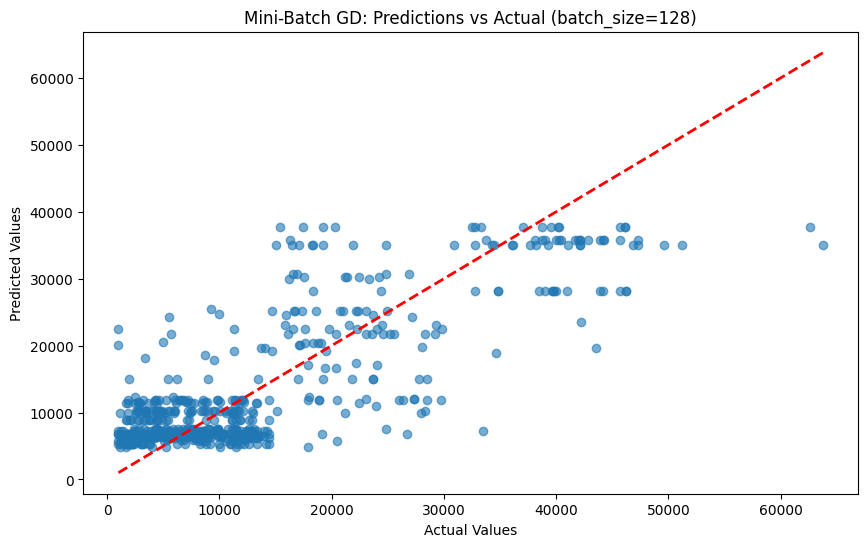

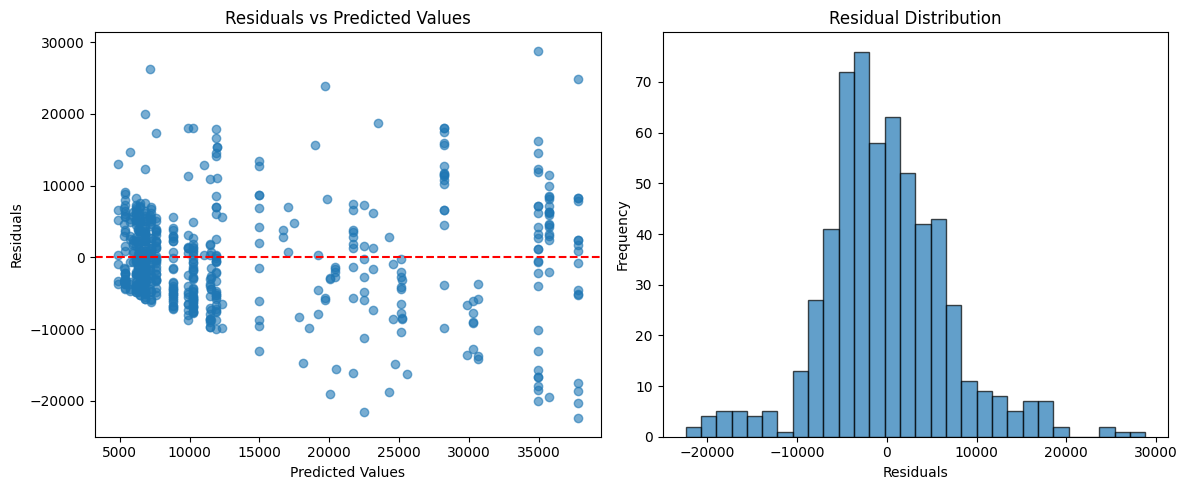

In [209]:
model, metrics, best_lr, best_batch_size = run_mini_batch_gradient_descent_regression(
    df_reduced_wo_income,
    target,
    batch_sizes=[2**i for i in range(1, 8)],
    learning_rates=np.round(np.arange(0.01,0.5,0.05),2)
    )

## d) Linear regression (Batch Gradient Descent) complete dataset


### Augmented dataset

In [210]:
df_aug = df.copy()

# ------------------------------
# 2a. Polynomial terms for numerical features
# ------------------------------
# Squared and cubic terms to capture non-linear relationships
numerical_cols = ['age', 'bmi', 'children', 'stress_level', 'physical_activity', 'income (USD)']
for col in numerical_cols:
    if col in df_aug.columns:
        df_aug[f'{col}2'] = df_aug[col] ** 2

# ------------------------------
# 2b. Interactions between numerical and binary features
# ------------------------------
# Example: income*smoker or age*smoker
binary_cols = ['smoker', 'gender']
for b_col in binary_cols:
    for n_col in numerical_cols:
        if b_col in df_aug.columns and n_col in df_aug.columns:
            df_aug[f'{n_col}_{b_col}'] = df_aug[n_col] * df_aug[b_col]

# ------------------------------
# 2c. Interactions between numerical features
# ------------------------------
# Example: age*bmi, age*stress_level
for i in range(len(numerical_cols)):
    for j in range(i+1, len(numerical_cols)):
        col1 = numerical_cols[i]
        col2 = numerical_cols[j]
        if col1 in df_aug.columns and col2 in df_aug.columns:
            df_aug[f'{col1}_{col2}'] = df_aug[col1] * df_aug[col2]

# ------------------------------
# 2d. Interactions between numerical and categorical features
# ------------------------------
# Categorical columns starting with 'region_', 'status_', 'sector_'
categorical_cols = [c for c in df_aug.columns if c.startswith(('region_', 'status_', 'sector_'))]
for cat_col in categorical_cols:
    for n_col in numerical_cols:
        if cat_col in df_aug.columns and n_col in df_aug.columns:
            df_aug[f'{cat_col}_{n_col}'] = df_aug[cat_col] * df_aug[n_col]

# ------------------------------
# 2e. Interactions between binary and categorical features
# ------------------------------
# Example: smoker*sector_Healthcare
for cat_col in categorical_cols:
    for b_col in binary_cols:
        if cat_col in df_aug.columns and b_col in df_aug.columns:
            df_aug[f'{cat_col}_{b_col}'] = df_aug[cat_col] * df_aug[b_col]

# ==============================
# 3️⃣ Standardize all features except the target
# ==============================
scaler = StandardScaler()
feature_cols = [c for c in df_aug.columns if c != 'charges (USD)']  # exclude target
df_aug[feature_cols] = scaler.fit_transform(df_aug[feature_cols])

# ==============================
# 4️⃣ Final augmented dataset
# ==============================
dataset_augmented = df_aug.copy()

print("Augmented dataset created!")
print("Number of features:", dataset_augmented.shape[1])
print(dataset_augmented.head())


Augmented dataset created!
Number of features: 277
        age    gender       bmi  children    smoker  physical_activity  \
0  0.414872 -1.016012 -0.822191  1.555194 -0.518525          -0.240784   
1 -0.515723  0.984240 -0.427076  2.381373  1.928548          -1.380750   
2  0.128535 -1.016012  1.039094  0.729015 -0.518525           2.039150   
3 -0.945228  0.984240  0.053756 -0.923344 -0.518525          -1.380750   
4 -1.159981 -1.016012  0.689695  1.555194 -0.518525          -1.380750   

   stress_level  sleep_quality  income (USD)  charges (USD)  ...  \
0      0.280011       0.096673      0.089463     9101.79800  ...   
1      0.280011      -1.052142      0.973316    21472.47880  ...   
2     -0.300655       0.096673     -0.835160     7371.77200  ...   
3     -0.300655       0.096673     -1.059974     2699.56835  ...   
4      1.267143       1.245488     -1.012711     4466.62140  ...   

   sector_Retail Management_smoker  sector_Retail Management_gender  \
0                       

In [211]:
df_aug

,age,gender,bmi,children,smoker,physical_activity,stress_level,sleep_quality,income (USD),charges (USD),...,sector_Retail Management_smoker,sector_Retail Management_gender,sector_Self-Employed_smoker,sector_Self-Employed_gender,sector_Transportation_smoker,sector_Transportation_gender,sector_Unemployed_smoker,sector_Unemployed_gender,sector_other_smoker,sector_other_gender
0,0.414872,-1.016012,-0.822191,1.555194,-0.518525,-0.240784,0.280011,0.096673,0.089463,9101.79800,...,-0.052067,-0.052067,-0.073734,-0.063812,-0.018387,-0.188949,0.0,-0.167763,-0.061085,-0.086548
1,-0.515723,0.984240,-0.427076,2.381373,1.928548,-1.380750,0.280011,-1.052142,0.973316,21472.47880,...,-0.052067,-0.052067,-0.073734,-0.063812,-0.018387,-0.188949,0.0,-0.167763,-0.061085,-0.086548
2,0.128535,-1.016012,1.039094,0.729015,-0.518525,2.039150,-0.300655,0.096673,-0.835160,7371.77200,...,-0.052067,-0.052067,-0.073734,-0.063812,-0.018387,-0.188949,0.0,-0.167763,-0.061085,-0.086548
3,-0.945228,0.984240,0.053756,-0.923344,-0.518525,-1.380750,-0.300655,0.096673,-1.059974,2699.56835,...,-0.052067,-0.052067,-0.073734,-0.063812,-0.018387,-0.188949,0.0,-0.167763,-0.061085,-0.086548
4,-1.159981,-1.016012,0.689695,1.555194,-0.518525,-1.380750,1.267143,1.245488,-1.012711,4466.62140,...,-0.052067,-0.052067,-0.073734,-0.063812,-0.018387,-0.188949,0.0,-0.167763,-0.061085,-0.086548
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2954,1.059129,0.984240,0.567242,0.729015,1.928548,-0.240784,1.615543,-1.052142,1.562728,44260.74990,...,-0.052067,-0.052067,-0.073734,-0.063812,-0.018387,-0.188949,0.0,-0.167763,-0.061085,-0.086548
2955,-1.517902,-1.016012,0.100288,2.381373,-0.518525,-1.380750,2.080076,-1.052142,-0.666720,4561.18850,...,-0.052067,-0.052067,-0.073734,-0.063812,-0.018387,-0.188949,0.0,-0.167763,-0.061085,-0.086548
2956,-0.014634,-1.016012,-1.120976,3.207552,-0.518525,-0.240784,-0.358722,1.245488,-0.119289,8582.30230,...,-0.052067,-0.052067,-0.073734,-0.063812,-0.018387,-0.188949,0.0,-0.167763,-0.061085,-0.086548
2957,1.345466,0.984240,-0.907908,-0.923344,-0.518525,-0.240784,-0.997455,-1.052142,0.563008,11931.12525,...,-0.052067,-0.052067,-0.073734,-0.063812,-0.018387,-0.188949,0.0,-0.167763,-0.061085,-0.086548


### Implementation

Checking for NaN values in the dataset...
No NaN values found in the dataset.
Data Preparation Complete:
Training set: (1775, 276)
Validation set: (592, 276)
Test set: (592, 276)

STEP 1: FINDING OPTIMAL LEARNING RATE
✓ Learning Rate: 0.0010 | MSE: 47910855.8766 | R²: 0.6373 | Converged: False | Iterations: 1000
✓ Learning Rate: 0.0060 | MSE: 21461016.4645 | R²: 0.8375 | Converged: False | Iterations: 1000
✓ Learning Rate: 0.0110 | MSE: 21112953.2057 | R²: 0.8402 | Converged: False | Iterations: 1000
✓ Learning Rate: 0.0160 | MSE: 20842078.7863 | R²: 0.8422 | Converged: False | Iterations: 1000
✓ Learning Rate: 0.0210 | MSE: 20645706.8790 | R²: 0.8437 | Converged: False | Iterations: 1000
✓ Learning Rate: 0.0260 | MSE: 20508507.3054 | R²: 0.8447 | Converged: False | Iterations: 1000
✓ Learning Rate: 0.0310 | MSE: 20413751.6527 | R²: 0.8455 | Converged: False | Iterations: 1000
✓ Learning Rate: 0.0360 | MSE: 20348450.8296 | R²: 0.8460 | Converged: False | Iterations: 1000
✓ Learning Rat

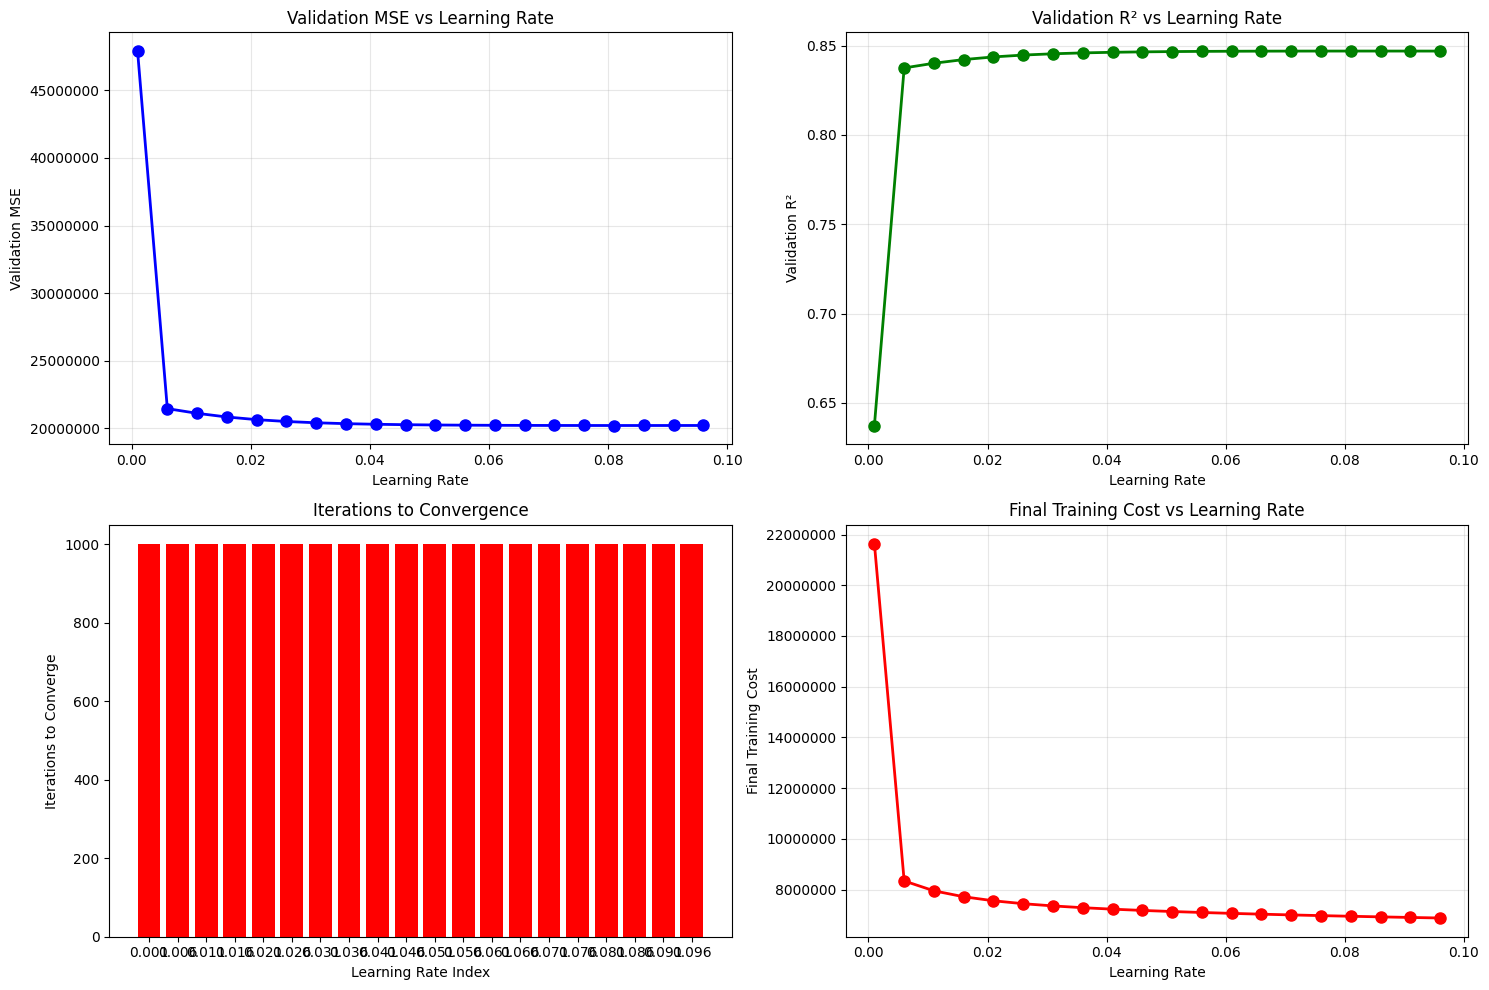


Optimal Learning Rate: 0.081

STEP 2: CONVERGENCE ANALYSIS WITH OPTIMAL LEARNING RATE
Training model with learning rate: 0.081
Iteration 0: Cost = 112534129.183068
Iteration 100: Cost = 8138929.192732
Iteration 200: Cost = 7705006.493848
Iteration 300: Cost = 7475744.146123
Iteration 400: Cost = 7332230.930802
Iteration 500: Cost = 7231151.167828
Iteration 600: Cost = 7153495.084692
Iteration 700: Cost = 7090080.825751
Iteration 800: Cost = 7036097.005914
Iteration 900: Cost = 6988817.777700
Iteration 1000: Cost = 6946580.867180
Iteration 1100: Cost = 6908303.458332
Iteration 1200: Cost = 6873239.427167
Iteration 1300: Cost = 6840850.356039
Iteration 1400: Cost = 6810732.954084
Iteration 1500: Cost = 6782575.927168
Iteration 1600: Cost = 6756133.044423
Iteration 1700: Cost = 6731205.570841
Iteration 1800: Cost = 6707630.372825
Iteration 1900: Cost = 6685271.604526
Training completed. Final cost: 6664222.183986


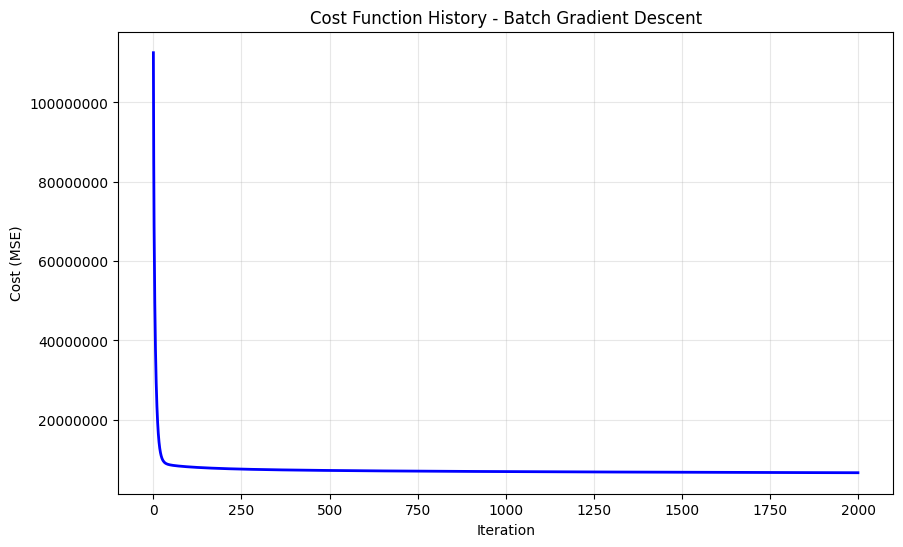


Convergence Analysis:
Initial Cost: 112534129.183068
Final Cost: 6664222.183986
Cost Reduction: 105869906.999082
Iterations Used: 2000
Convergence Ratio: 94.08%

STEP 3: FINAL EVALUATION ON TEST SET

FINAL MODEL PERFORMANCE:
R² Score: 0.8544
MSE: 20768742.6409
RMSE: 4557.2736
MAE: 2690.5670
Optimal Learning Rate: 0.081
Final Iterations: 2000


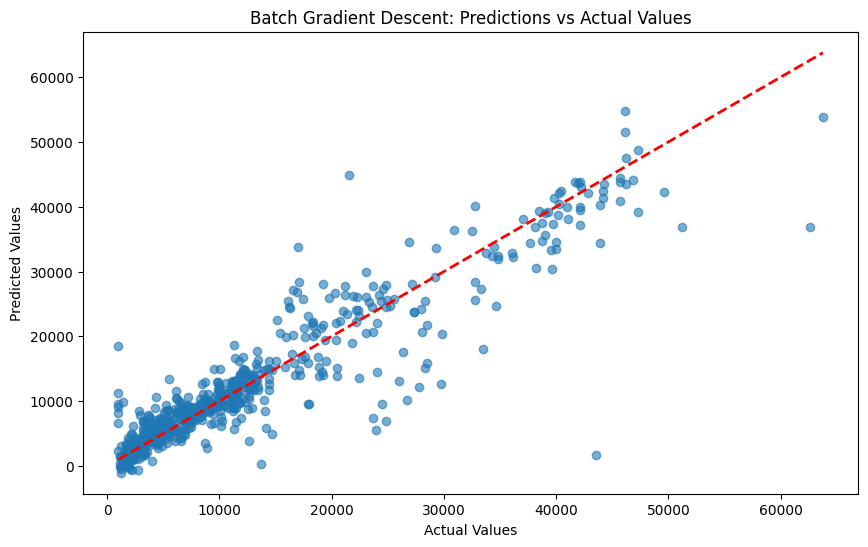

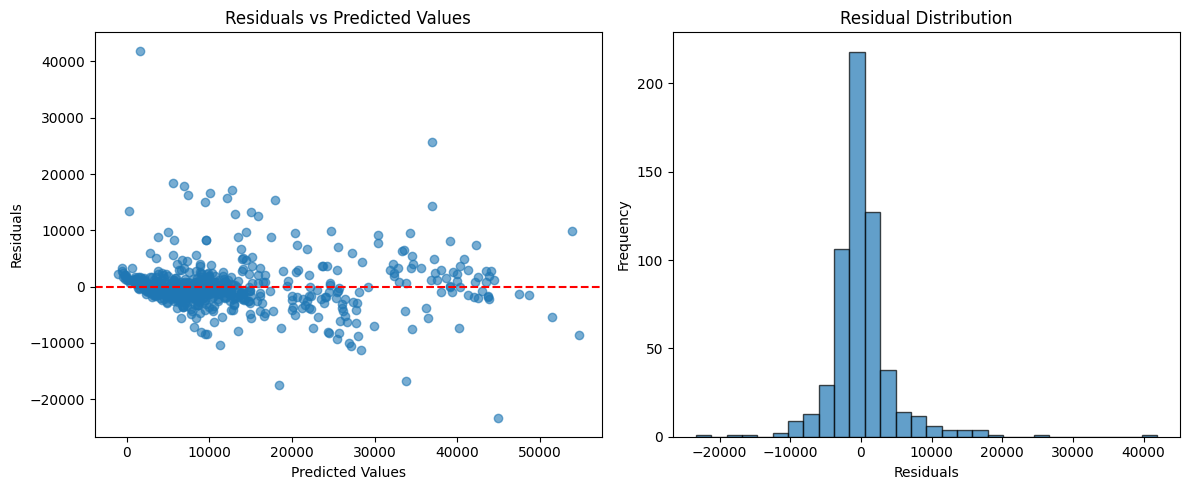

In [212]:
model, metrics, best_lr = run_batch_gradient_descent_regression(df_aug, target ,learning_rates=np.arange(0.001, 0.1, 0.005).tolist())

## f) Linear Regression model with Lasso regularization (dataset_augmented)


In [213]:
X = df_aug.drop(columns=[target])
y = df_aug[target]

In [214]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [231]:
from sklearn.linear_model import Lasso

alphas = [0.00001, 0.00005, 0.0001, 0.0005, 0.001, 0.005, 0.01, 0.05, 0.1, 0.5, 1, 5, 10, 50, 75, 100]
results = []

for alpha in alphas:
    lasso = Lasso(alpha=alpha, max_iter=10000)
    lasso.fit(X_train, y_train)
    
    n_features = np.sum(lasso.coef_ != 0)
    
    test_score = lasso.score(X_test, y_test)  # R^2
    
    results.append((alpha, n_features, test_score))

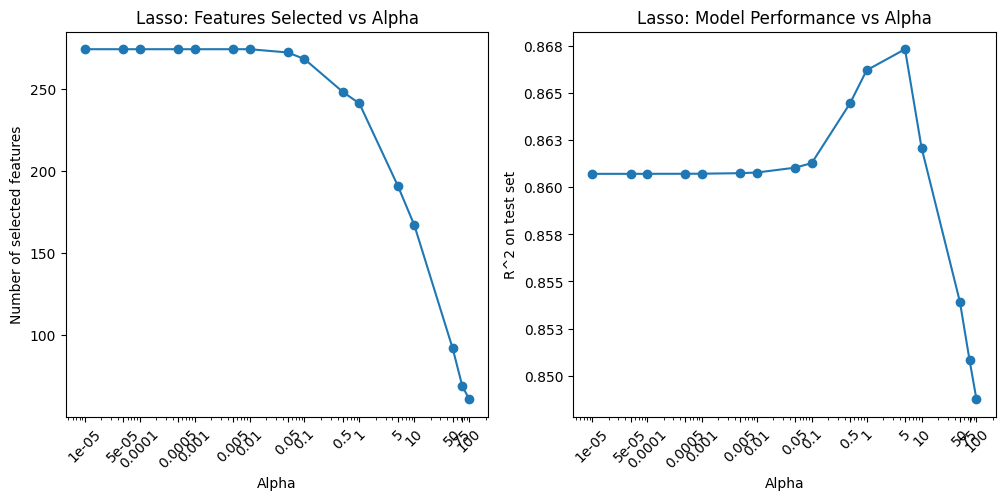

In [216]:
import matplotlib.ticker as mticker

alphas_list, n_features_list, test_scores = zip(*results)

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(alphas_list, n_features_list, marker='o')
plt.xscale('log')
plt.xlabel('Alpha')
plt.ylabel('Number of selected features')
plt.title('Lasso: Features Selected vs Alpha')
plt.gca().yaxis.set_major_formatter(mticker.StrMethodFormatter('{x:.0f}'))
plt.xticks(alphas, labels=[str(a) for a in alphas])
plt.xticks(rotation=45)


plt.subplot(1,2,2)
plt.plot(alphas_list, test_scores, marker='o')
plt.xscale('log')
plt.xlabel('Alpha')
plt.ylabel('R^2 on test set')
plt.title('Lasso: Model Performance vs Alpha')
plt.gca().yaxis.set_major_formatter(mticker.StrMethodFormatter('{x:.3f}'))
plt.xticks(alphas, labels=[str(a) for a in alphas])
plt.xticks(rotation=45)


plt.show()


In [247]:
# Find the index of the maximum score using enumerate and max with a custom key
max_index, max_score = max(enumerate(test_scores), key=lambda x: x[1])

# Get the corresponding alpha and number of features using the found index
best_alpha = alphas_list[max_index]
best_n_features = n_features_list[max_index]

print(f"Highest score: {max_score}")
print(f"Corresponding alpha: {best_alpha}")
print(f"Number of features: {best_n_features}")

Highest score: 0.8673363874050288
Corresponding alpha: 5
Number of features: 191


## g) Ridge Regression model for best 𝜶 (dataset_augmented)

In [248]:
from sklearn.model_selection import train_test_split

X = dataset_augmented.drop(columns=[target])
y = dataset_augmented[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [249]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [250]:
alphas = [0.00001, 0.00005, 0.0001, 0.0005, 0.001, 0.005, 0.01, 0.05, 0.1, 0.5, 1, 5, 10, 50, 75, 100]

results = []

for alpha in alphas:
    ridge = Ridge(alpha=alpha, max_iter=10000)
    ridge.fit(X_train, y_train)
    
    n_features = np.sum(np.abs(ridge.coef_) > 1e-6)
    
    test_score = ridge.score(X_test, y_test)
    
    results.append((alpha, n_features, test_score))

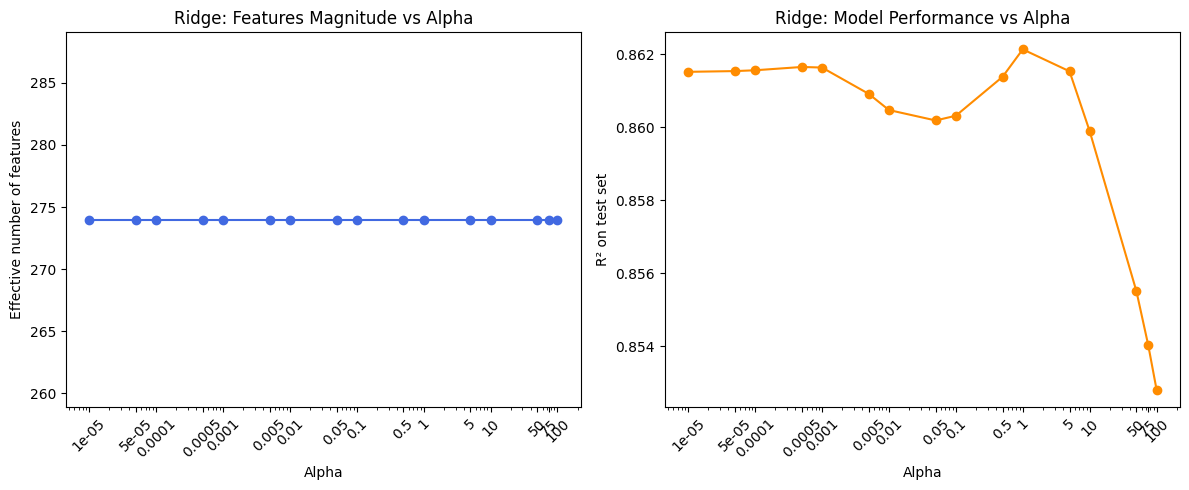

In [251]:
alphas_list, n_features_list, test_scores = zip(*results)


plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(alphas_list, n_features_list, marker='o', color='royalblue')
plt.xscale('log')
plt.xlabel('Alpha')
plt.ylabel('Effective number of features')
plt.title('Ridge: Features Magnitude vs Alpha')
plt.gca().yaxis.set_major_formatter(mticker.StrMethodFormatter('{x:.0f}'))
plt.xticks(alphas, labels=[str(a) for a in alphas])
plt.xticks(rotation=45)

plt.subplot(1,2,2)
plt.plot(alphas_list, test_scores, marker='o', color='darkorange')
plt.xscale('log')
plt.xlabel('Alpha')
plt.ylabel('R² on test set')
plt.title('Ridge: Model Performance vs Alpha')
plt.gca().yaxis.set_major_formatter(mticker.StrMethodFormatter('{x:.3f}'))
plt.xticks(alphas, labels=[str(a) for a in alphas])
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [252]:
max_index, max_score = max(enumerate(test_scores), key=lambda x: x[1])
best_alpha = alphas_list[max_index]
best_n_features = n_features_list[max_index]

print(f"Highest R² score: {max_score:.4f}")
print(f"Corresponding alpha: {best_alpha}")
print(f"Number of features effectively used: {best_n_features}")

Highest R² score: 0.8621
Corresponding alpha: 1
Number of features effectively used: 274


# 4 stratify the problem according to gender

## DataFrame

In [222]:
# from the encoding
'''
# Gender - binary encoding
df['gender'] = df['gender'].map({'female': False, 'male': True})
'''
# male = 1, female = 0
df

,age,gender,bmi,children,smoker,physical_activity,stress_level,sleep_quality,income (USD),charges (USD),...,sector_IT,sector_IT Support,sector_Law,sector_Management,sector_Retail,sector_Retail Management,sector_Self-Employed,sector_Transportation,sector_Unemployed,sector_other
0,45.0,0,25.7000,3,0,0,6.9,1,10.699335,9101.79800,...,0,0,0,0,0,0,0,0,0,0
1,32.0,1,28.1200,4,1,-1,6.9,0,11.538163,21472.47880,...,0,1,0,0,0,0,0,0,0,0
2,41.0,0,37.1000,2,0,2,5.9,1,9.821813,7371.77200,...,0,0,0,0,0,0,0,1,0,0
3,26.0,1,31.0650,0,0,-1,5.9,1,9.608451,2699.56835,...,0,0,0,0,0,0,0,0,0,0
4,23.0,0,34.9600,3,0,-1,8.6,2,9.653306,4466.62140,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2954,54.0,1,34.2100,2,1,0,9.2,0,12.097550,44260.74990,...,0,0,0,0,0,0,0,0,0,0
2955,18.0,0,31.3500,4,0,-1,10.0,0,9.981672,4561.18850,...,0,0,0,0,1,0,0,0,0,0
2956,39.0,0,23.8700,5,0,0,5.8,2,10.501216,8582.30230,...,0,0,0,0,0,0,0,1,0,0
2957,58.0,1,25.1750,0,0,0,4.7,0,11.148757,11931.12525,...,0,0,0,0,0,0,0,0,0,0


In [223]:
df_male =  df[df['gender'] == 1]
df_female =  df[df['gender'] == 0]

In [224]:
df_male

,age,gender,bmi,children,smoker,physical_activity,stress_level,sleep_quality,income (USD),charges (USD),...,sector_IT,sector_IT Support,sector_Law,sector_Management,sector_Retail,sector_Retail Management,sector_Self-Employed,sector_Transportation,sector_Unemployed,sector_other
1,32.00000,1,28.120000,4,1,-1,6.9,0,11.538163,21472.478800,...,0,1,0,0,0,0,0,0,0,0
3,26.00000,1,31.065000,0,0,-1,5.9,1,9.608451,2699.568350,...,0,0,0,0,0,0,0,0,0,0
7,44.00000,1,30.690000,2,0,-1,4.8,1,10.864926,7731.427100,...,0,0,0,0,0,0,0,0,0,0
9,18.00000,1,34.430000,0,0,-1,5.2,1,9.339323,1137.469700,...,0,0,0,0,1,0,0,0,0,0
15,26.93778,1,29.837539,0,0,1,5.7,0,11.332656,15566.085115,...,0,0,0,0,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2944,29.00000,1,31.730000,2,0,1,7.2,1,9.607931,4433.387700,...,0,0,0,0,1,0,0,0,0,0
2948,28.00000,1,30.875000,0,0,-1,5.2,2,9.731993,3062.508250,...,0,0,0,0,0,0,0,0,0,0
2951,37.00000,1,22.705000,3,0,0,7.2,0,10.573208,6985.506950,...,0,0,0,0,0,0,0,0,0,0
2954,54.00000,1,34.210000,2,1,0,9.2,0,12.097550,44260.749900,...,0,0,0,0,0,0,0,0,0,0


In [225]:
df_female

,age,gender,bmi,children,smoker,physical_activity,stress_level,sleep_quality,income (USD),charges (USD),...,sector_IT,sector_IT Support,sector_Law,sector_Management,sector_Retail,sector_Retail Management,sector_Self-Employed,sector_Transportation,sector_Unemployed,sector_other
0,45.0,0,25.7000,3,0,0,6.9,1,10.699335,9101.7980,...,0,0,0,0,0,0,0,0,0,0
2,41.0,0,37.1000,2,0,2,5.9,1,9.821813,7371.7720,...,0,0,0,0,0,0,0,1,0,0
4,23.0,0,34.9600,3,0,-1,8.6,2,9.653306,4466.6214,...,0,0,0,0,0,0,0,0,0,0
5,18.0,0,32.1200,2,0,-1,6.4,1,9.720714,2801.2588,...,0,0,0,0,0,0,0,0,1,0
6,52.0,0,44.7000,3,0,1,8.0,2,10.974195,11411.6850,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2952,60.0,0,28.7000,1,0,-1,5.1,1,10.757941,13224.6930,...,0,0,0,0,0,0,0,0,0,0
2953,50.0,0,27.6000,1,1,1,4.7,2,11.295958,24520.2640,...,0,0,0,0,0,0,0,0,0,0
2955,18.0,0,31.3500,4,0,-1,10.0,0,9.981672,4561.1885,...,0,0,0,0,1,0,0,0,0,0
2956,39.0,0,23.8700,5,0,0,5.8,2,10.501216,8582.3023,...,0,0,0,0,0,0,0,1,0,0


In [226]:
df_red_col = df_reduced.columns
df_red_col_woi = df_reduced_wo_income.columns

df_male_reduced = df_male[df_red_col]
df_male_reduced_woi = df_male[df_red_col_woi]

df_female_reduced = df_female[df_red_col]
df_female_reduced_woi = df_female[df_red_col_woi]



## Implementation (Batch Gradient Descent)

### Male

####  with income (USD)

Checking for NaN values in the dataset...
No NaN values found in the dataset.
Data Preparation Complete:
Training set: (901, 15)
Validation set: (301, 15)
Test set: (301, 15)

STEP 1: FINDING OPTIMAL LEARNING RATE
✓ Learning Rate: 0.0010 | MSE: 92916358.0757 | R²: 0.4576 | Converged: False | Iterations: 1000
✓ Learning Rate: 0.0060 | MSE: 48043624.3618 | R²: 0.7195 | Converged: False | Iterations: 1000
✓ Learning Rate: 0.0110 | MSE: 44032241.7464 | R²: 0.7429 | Converged: False | Iterations: 1000
✓ Learning Rate: 0.0160 | MSE: 42480207.2711 | R²: 0.7520 | Converged: False | Iterations: 1000
✓ Learning Rate: 0.0210 | MSE: inf | R²: -inf | Converged: False | Iterations: 1000
✗ Learning Rate: 0.0260 | Failed: Input contains NaN.


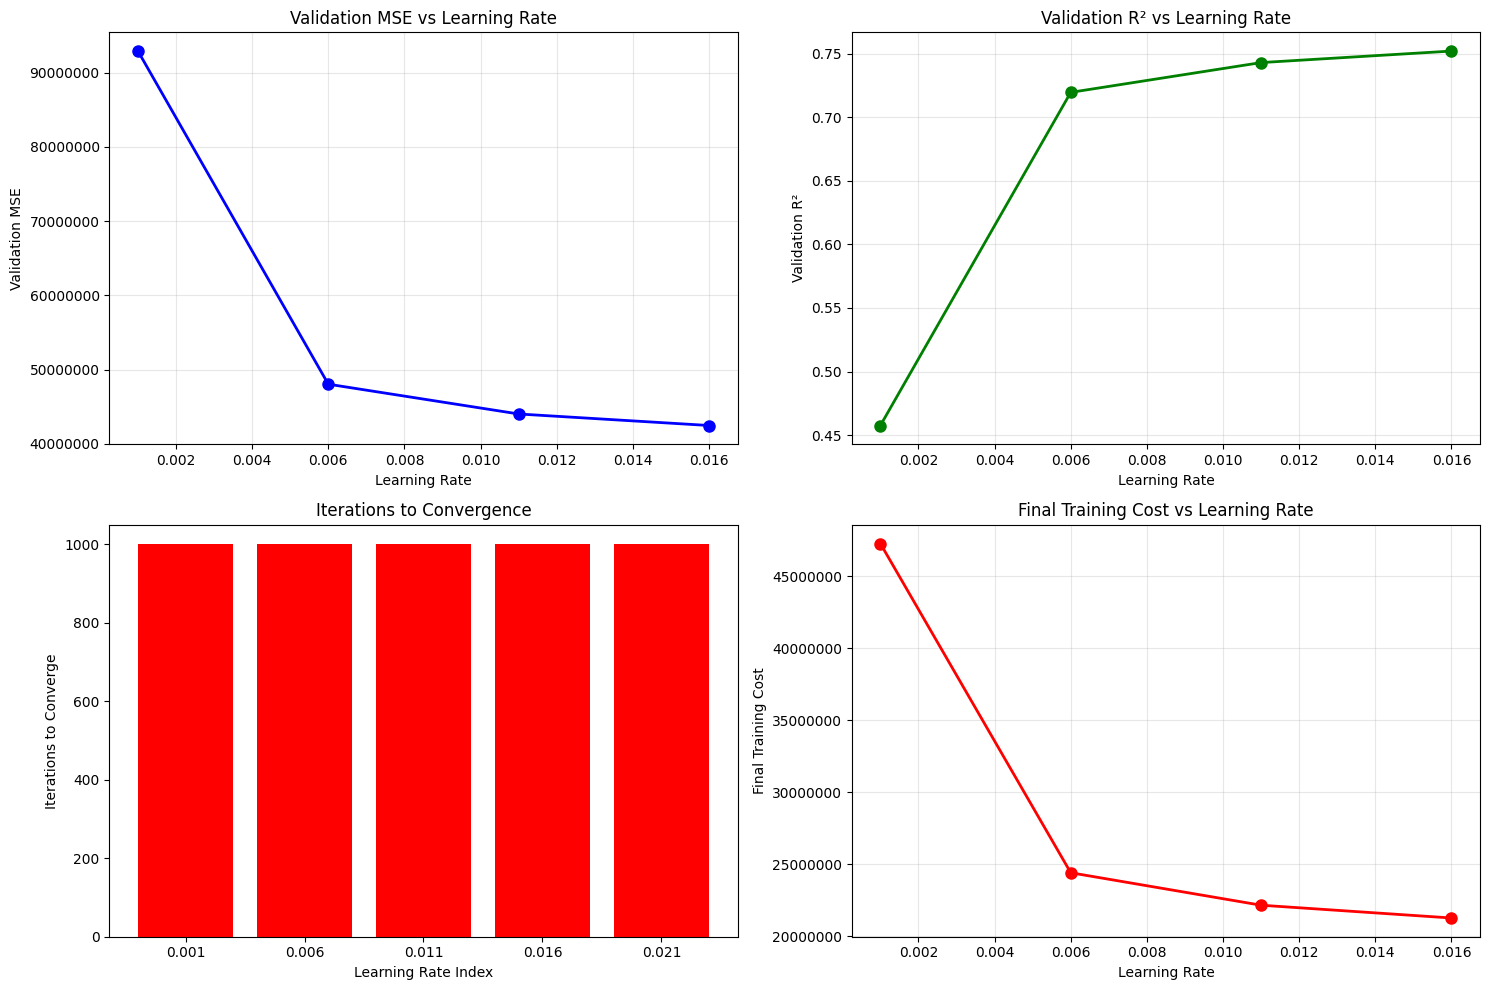


Optimal Learning Rate: 0.016

STEP 2: CONVERGENCE ANALYSIS WITH OPTIMAL LEARNING RATE
Training model with learning rate: 0.016
Iteration 0: Cost = 155319927.595067
Iteration 100: Cost = 39014727.548306
Iteration 200: Cost = 29163444.052465
Iteration 300: Cost = 25674046.936847
Iteration 400: Cost = 24081838.656536
Iteration 500: Cost = 23163827.273673
Iteration 600: Cost = 22548253.319930
Iteration 700: Cost = 22099819.728618
Iteration 800: Cost = 21756837.235767
Iteration 900: Cost = 21485216.828870
Iteration 1000: Cost = 21263750.135741
Iteration 1100: Cost = 21078406.601458
Iteration 1200: Cost = 20919605.308932
Iteration 1300: Cost = 20780679.262257
Iteration 1400: Cost = 20656924.136585
Iteration 1500: Cost = 20544979.217800
Iteration 1600: Cost = 20442414.049565
Iteration 1700: Cost = 20347448.299801
Iteration 1800: Cost = 20258759.987880
Iteration 1900: Cost = 20175353.153248
Training completed. Final cost: 20097234.457212


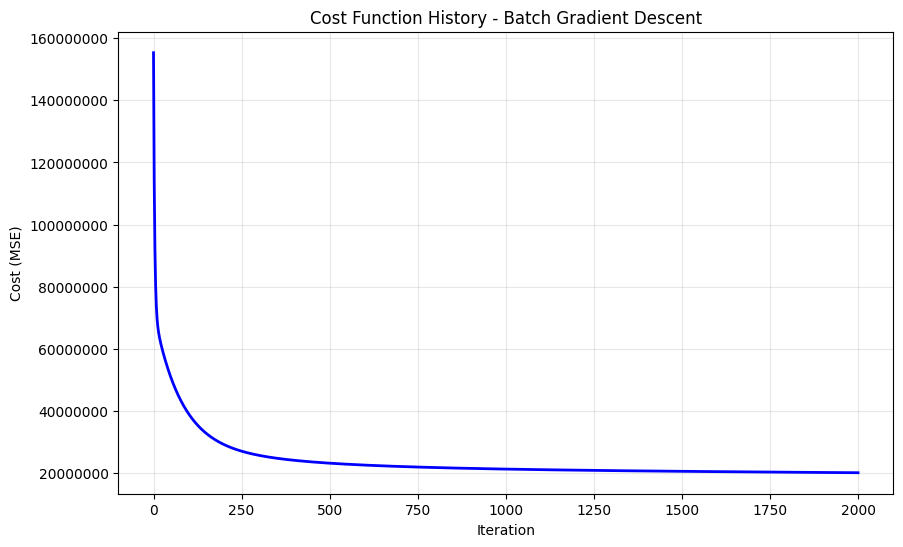


Convergence Analysis:
Initial Cost: 155319927.595067
Final Cost: 20097234.457212
Cost Reduction: 135222693.137855
Iterations Used: 2000
Convergence Ratio: 87.06%

STEP 3: FINAL EVALUATION ON TEST SET

FINAL MODEL PERFORMANCE:
R² Score: 0.7193
MSE: 43055054.8622
RMSE: 6561.6351
MAE: 4828.1713
Optimal Learning Rate: 0.016
Final Iterations: 2000


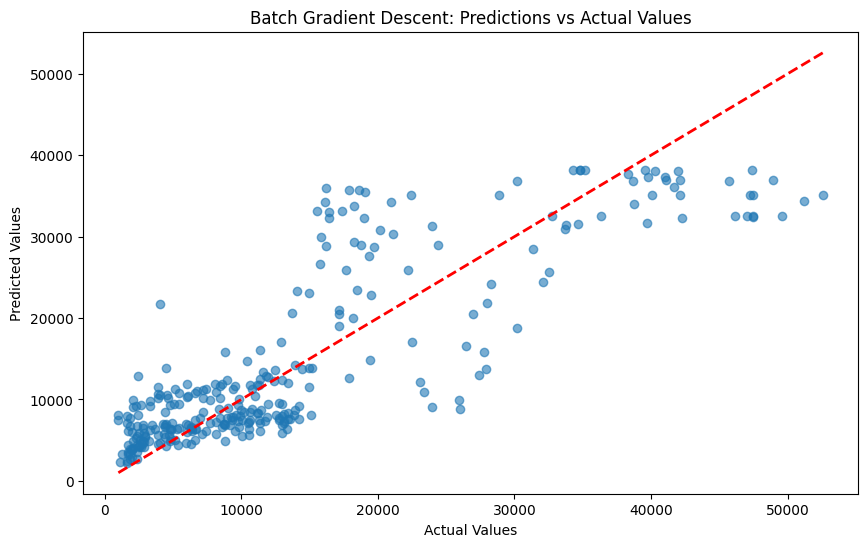

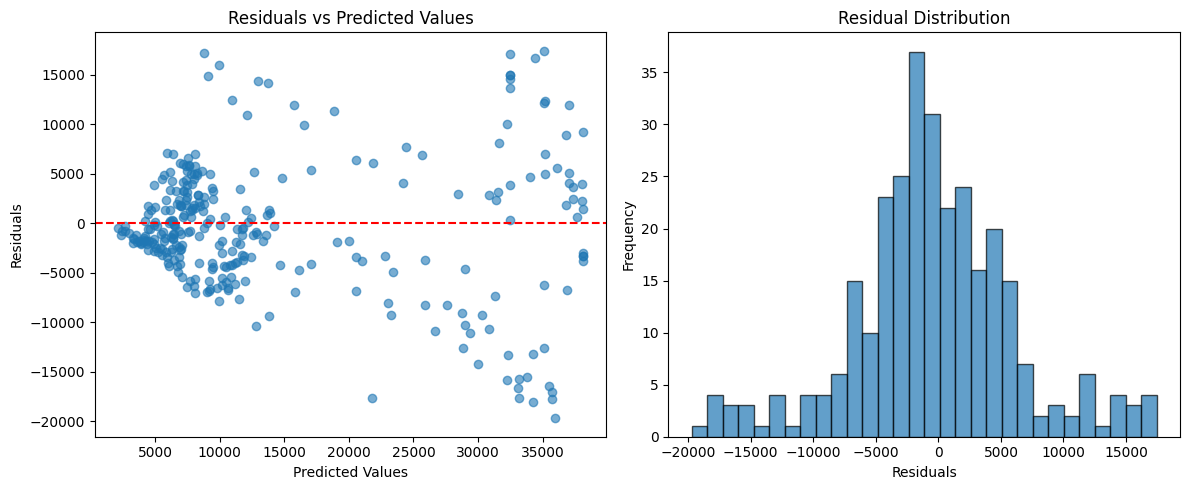

(<__main__.BatchGradientDescentLinearRegression at 0x24a358efe00>,
 {'mse': 43055054.86217986,
  'rmse': 6561.635075358874,
  'mae': 4828.171301104738,
  'r2': 0.7193411415987032},
 0.016)

In [227]:
run_batch_gradient_descent_regression(df_male_reduced, target ,learning_rates=np.arange(0.001, 0.027, 0.005).tolist())

####  with out income (USD)

Checking for NaN values in the dataset...
No NaN values found in the dataset.
Data Preparation Complete:
Training set: (901, 14)
Validation set: (301, 14)
Test set: (301, 14)

STEP 1: FINDING OPTIMAL LEARNING RATE
✓ Learning Rate: 0.0010 | MSE: 108615583.2645 | R²: 0.3659 | Converged: False | Iterations: 1000
✓ Learning Rate: 0.0060 | MSE: 58029523.2757 | R²: 0.6612 | Converged: False | Iterations: 1000
✓ Learning Rate: 0.0110 | MSE: 54442963.6770 | R²: 0.6822 | Converged: False | Iterations: 1000
✓ Learning Rate: 0.0160 | MSE: 53302074.1405 | R²: 0.6888 | Converged: False | Iterations: 1000
✓ Learning Rate: 0.0210 | MSE: 52725732.1443 | R²: 0.6922 | Converged: False | Iterations: 1000
✓ Learning Rate: 0.0260 | MSE: 52333282.1808 | R²: 0.6945 | Converged: False | Iterations: 1000


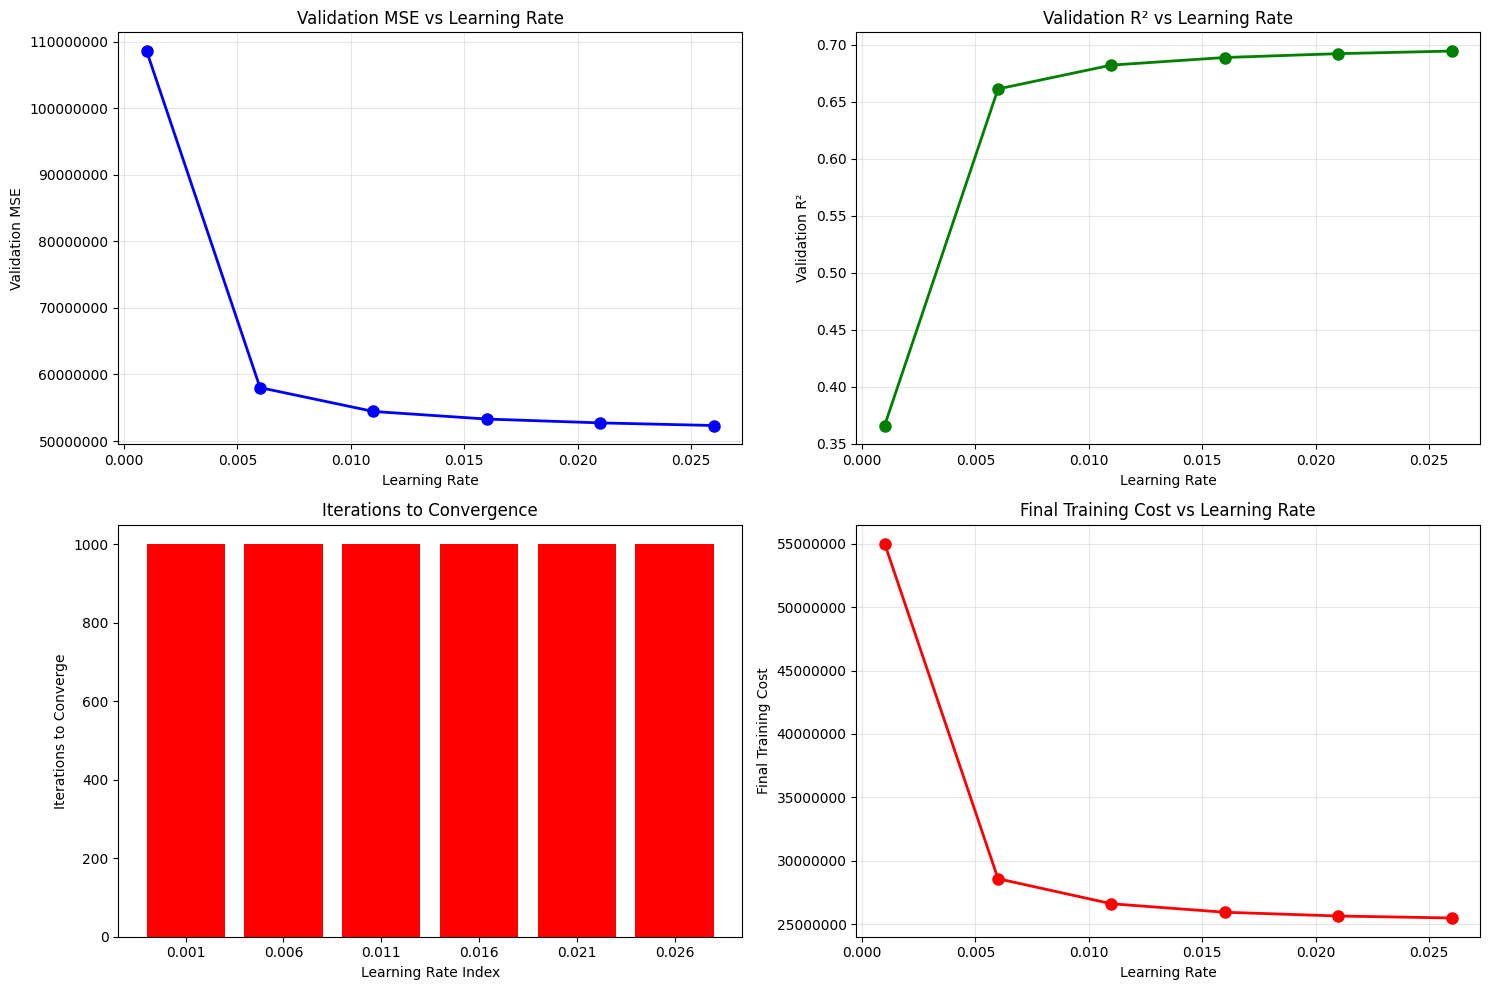


Optimal Learning Rate: 0.026000000000000002

STEP 2: CONVERGENCE ANALYSIS WITH OPTIMAL LEARNING RATE
Training model with learning rate: 0.026000000000000002
Iteration 0: Cost = 178805911.343187
Iteration 100: Cost = 34974517.609632
Iteration 200: Cost = 29246209.759118
Iteration 300: Cost = 27540767.871025
Iteration 400: Cost = 26724817.548859
Iteration 500: Cost = 26255431.270960
Iteration 600: Cost = 25963839.615925
Iteration 700: Cost = 25772769.134867
Iteration 800: Cost = 25641409.152728
Iteration 900: Cost = 25547040.175629
Iteration 1000: Cost = 25476593.622845
Iteration 1100: Cost = 25422313.493699
Iteration 1200: Cost = 25379435.805483
Iteration 1300: Cost = 25344920.711166
Iteration 1400: Cost = 25316747.836301
Iteration 1500: Cost = 25293517.858035
Iteration 1600: Cost = 25274222.890524
Iteration 1700: Cost = 25258111.183392
Iteration 1800: Cost = 25244605.285111
Iteration 1900: Cost = 25233251.020605
Training completed. Final cost: 25223772.409445


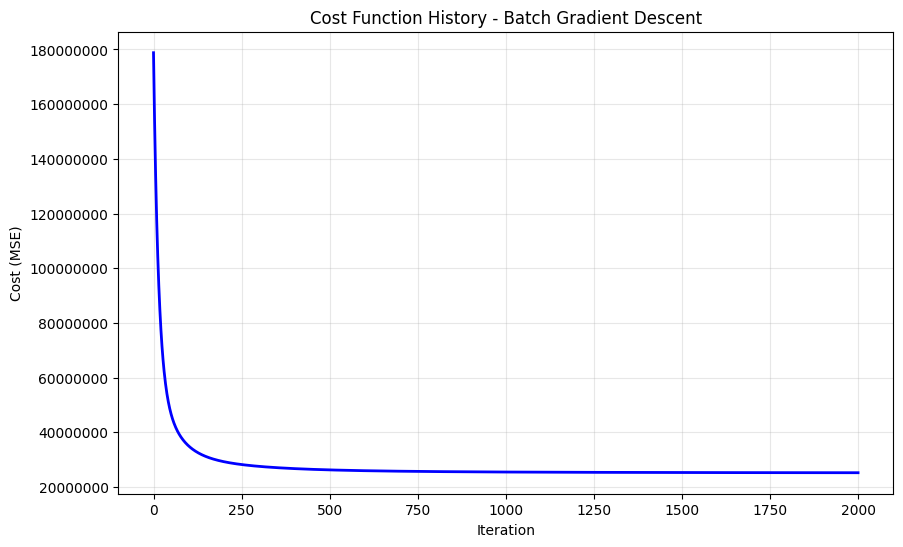


Convergence Analysis:
Initial Cost: 178805911.343187
Final Cost: 25223772.409445
Cost Reduction: 153582138.933743
Iterations Used: 2000
Convergence Ratio: 85.89%

STEP 3: FINAL EVALUATION ON TEST SET

FINAL MODEL PERFORMANCE:
R² Score: 0.6453
MSE: 54413550.6133
RMSE: 7376.5541
MAE: 5645.4375
Optimal Learning Rate: 0.026000000000000002
Final Iterations: 2000


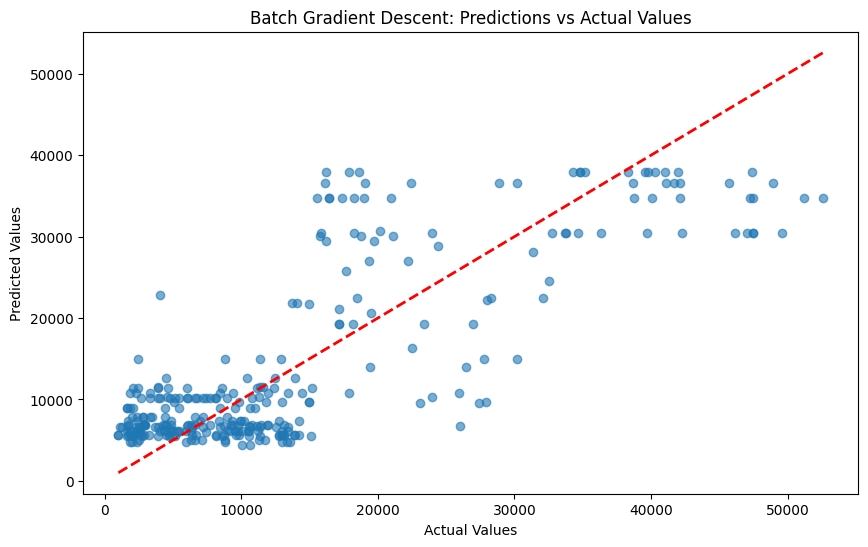

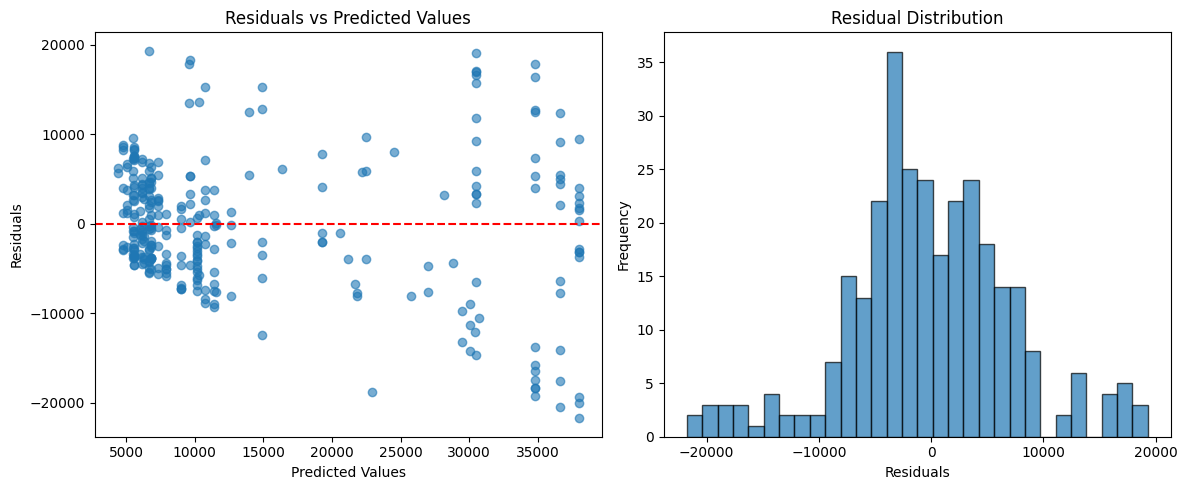

(<__main__.BatchGradientDescentLinearRegression at 0x24a3491dd60>,
 {'mse': 54413550.61326965,
  'rmse': 7376.5541151183625,
  'mae': 5645.437512082972,
  'r2': 0.6452996042957952},
 0.026000000000000002)

In [228]:
run_batch_gradient_descent_regression(df_male_reduced_woi, target ,learning_rates=np.arange(0.001, 0.027, 0.005).tolist())

### Female

####  with income (USD)

Checking for NaN values in the dataset...
No NaN values found in the dataset.
Data Preparation Complete:
Training set: (873, 15)
Validation set: (291, 15)
Test set: (292, 15)

STEP 1: FINDING OPTIMAL LEARNING RATE
✓ Learning Rate: 0.0010 | MSE: 67523309.3497 | R²: 0.3723 | Converged: False | Iterations: 1000
✓ Learning Rate: 0.0030 | MSE: 48111825.5426 | R²: 0.5528 | Converged: False | Iterations: 1000
✓ Learning Rate: 0.0050 | MSE: 42591600.7428 | R²: 0.6041 | Converged: False | Iterations: 1000
✓ Learning Rate: 0.0070 | MSE: 40591755.4130 | R²: 0.6227 | Converged: False | Iterations: 1000
✓ Learning Rate: 0.0090 | MSE: 39598993.9283 | R²: 0.6319 | Converged: False | Iterations: 1000
✓ Learning Rate: 0.0110 | MSE: 38969417.9983 | R²: 0.6378 | Converged: False | Iterations: 1000
✓ Learning Rate: 0.0130 | MSE: 38513136.7636 | R²: 0.6420 | Converged: False | Iterations: 1000
✓ Learning Rate: 0.0150 | MSE: 38157698.4235 | R²: 0.6453 | Converged: False | Iterations: 1000
✓ Learning Rate: 0

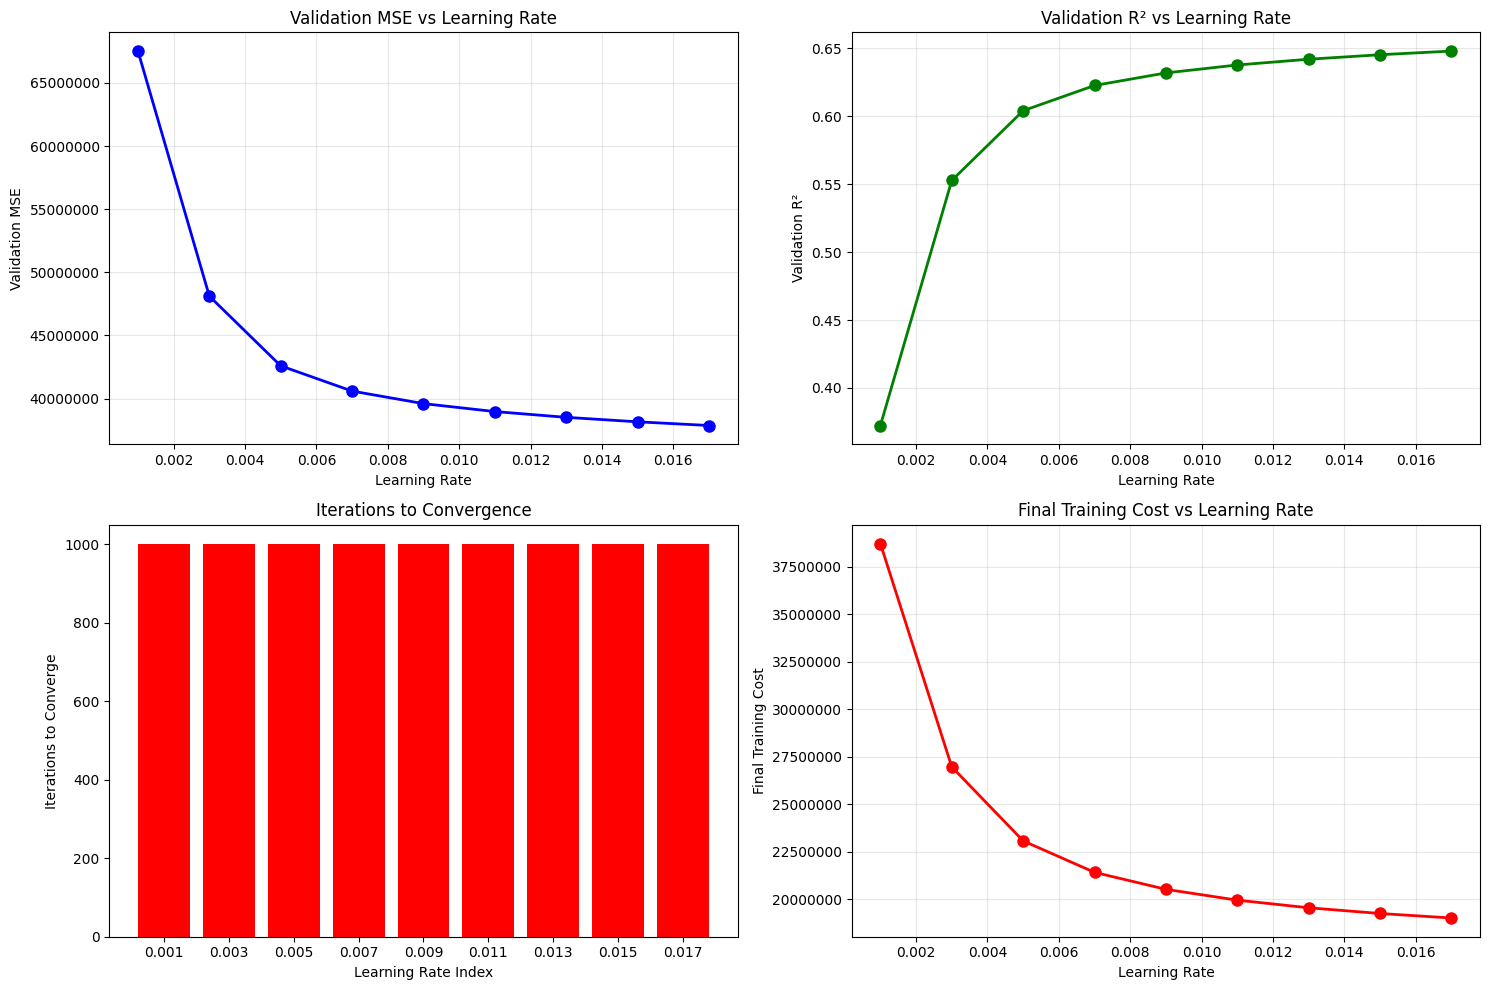


Optimal Learning Rate: 0.017

STEP 2: CONVERGENCE ANALYSIS WITH OPTIMAL LEARNING RATE
Training model with learning rate: 0.017
Iteration 0: Cost = 127109841.013808
Iteration 100: Cost = 32810913.572192
Iteration 200: Cost = 25791314.409757
Iteration 300: Cost = 22925544.399186
Iteration 400: Cost = 21516496.755572
Iteration 500: Cost = 20691656.673066
Iteration 600: Cost = 20142827.885173
Iteration 700: Cost = 19746054.716608
Iteration 800: Cost = 19443107.368846
Iteration 900: Cost = 19202382.200785
Iteration 1000: Cost = 19004794.356718
Iteration 1100: Cost = 18838012.188201
Iteration 1200: Cost = 18693738.883394
Iteration 1300: Cost = 18566251.440105
Iteration 1400: Cost = 18451534.486801
Iteration 1500: Cost = 18346732.863789
Iteration 1600: Cost = 18249791.887857
Iteration 1700: Cost = 18159215.264962
Iteration 1800: Cost = 18073899.692737
Iteration 1900: Cost = 17993020.682145
Training completed. Final cost: 17916706.609202


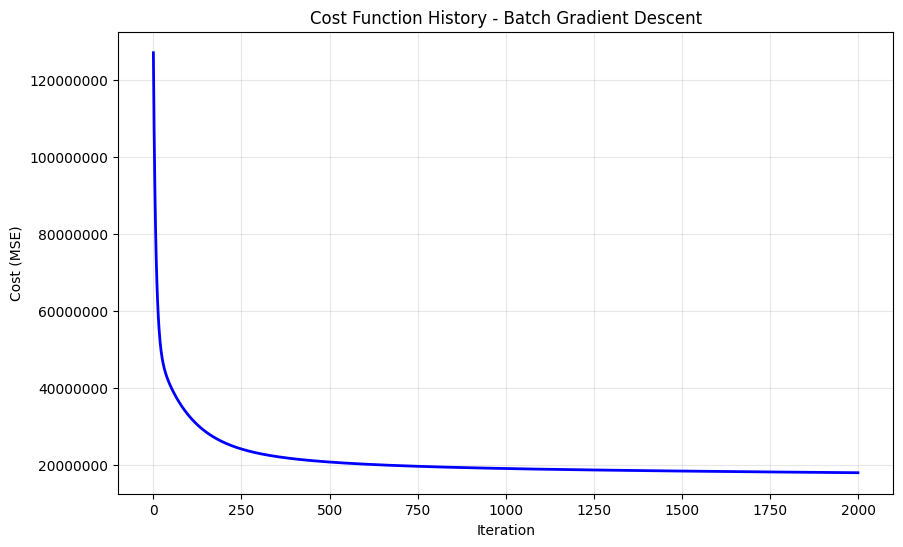


Convergence Analysis:
Initial Cost: 127109841.013808
Final Cost: 17916706.609202
Cost Reduction: 109193134.404606
Iterations Used: 2000
Convergence Ratio: 85.90%

STEP 3: FINAL EVALUATION ON TEST SET

FINAL MODEL PERFORMANCE:
R² Score: 0.7480
MSE: 33888380.1719
RMSE: 5821.3727
MAE: 4229.7408
Optimal Learning Rate: 0.017
Final Iterations: 2000


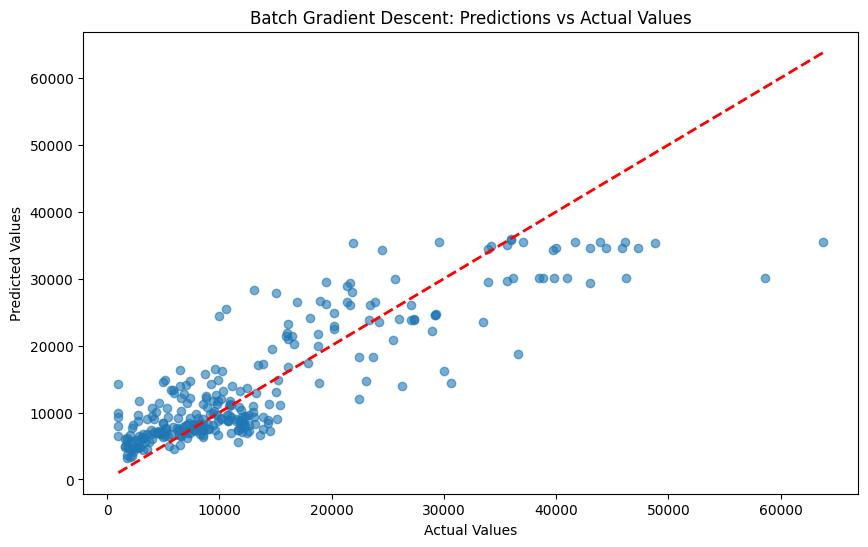

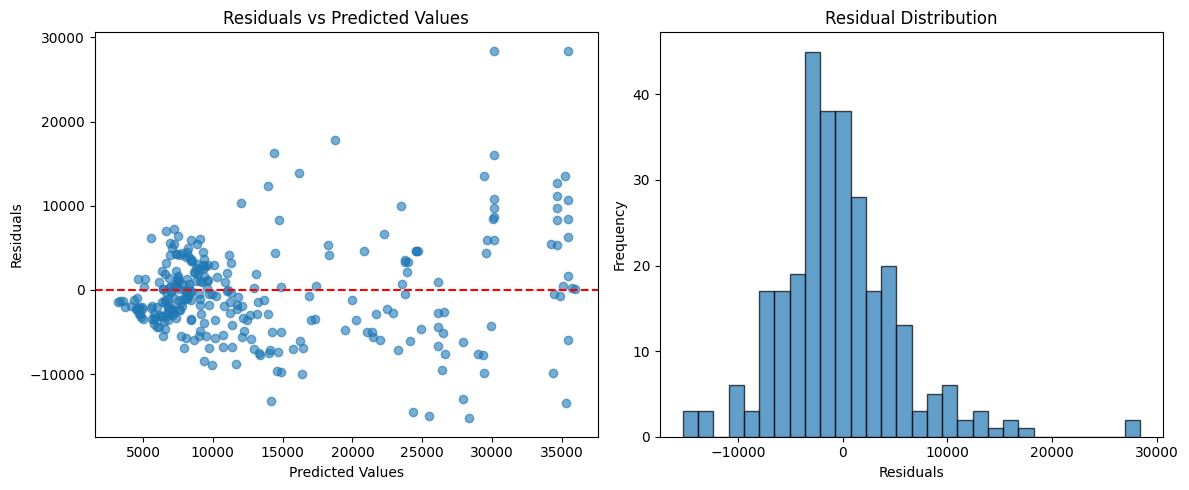

(<__main__.BatchGradientDescentLinearRegression at 0x24a270f8440>,
 {'mse': 33888380.17188492,
  'rmse': 5821.372705117317,
  'mae': 4229.740770782221,
  'r2': 0.7479884628656205},
 0.017)

In [257]:
run_batch_gradient_descent_regression(df_female_reduced, target ,learning_rates=np.arange(0.001, 0.019, 0.002).tolist())

####  with out income (USD)

Checking for NaN values in the dataset...
No NaN values found in the dataset.
Data Preparation Complete:
Training set: (873, 14)
Validation set: (291, 14)
Test set: (292, 14)

STEP 1: FINDING OPTIMAL LEARNING RATE
✓ Learning Rate: 0.0010 | MSE: 85412724.6844 | R²: 0.2061 | Converged: False | Iterations: 1000
✓ Learning Rate: 0.0060 | MSE: 48729493.8644 | R²: 0.5470 | Converged: False | Iterations: 1000
✓ Learning Rate: 0.0110 | MSE: 46531123.7164 | R²: 0.5675 | Converged: False | Iterations: 1000
✓ Learning Rate: 0.0160 | MSE: 45757332.6111 | R²: 0.5747 | Converged: False | Iterations: 1000
✓ Learning Rate: 0.0210 | MSE: 45354403.7373 | R²: 0.5784 | Converged: False | Iterations: 1000
✓ Learning Rate: 0.0260 | MSE: 45092980.0908 | R²: 0.5808 | Converged: False | Iterations: 1000


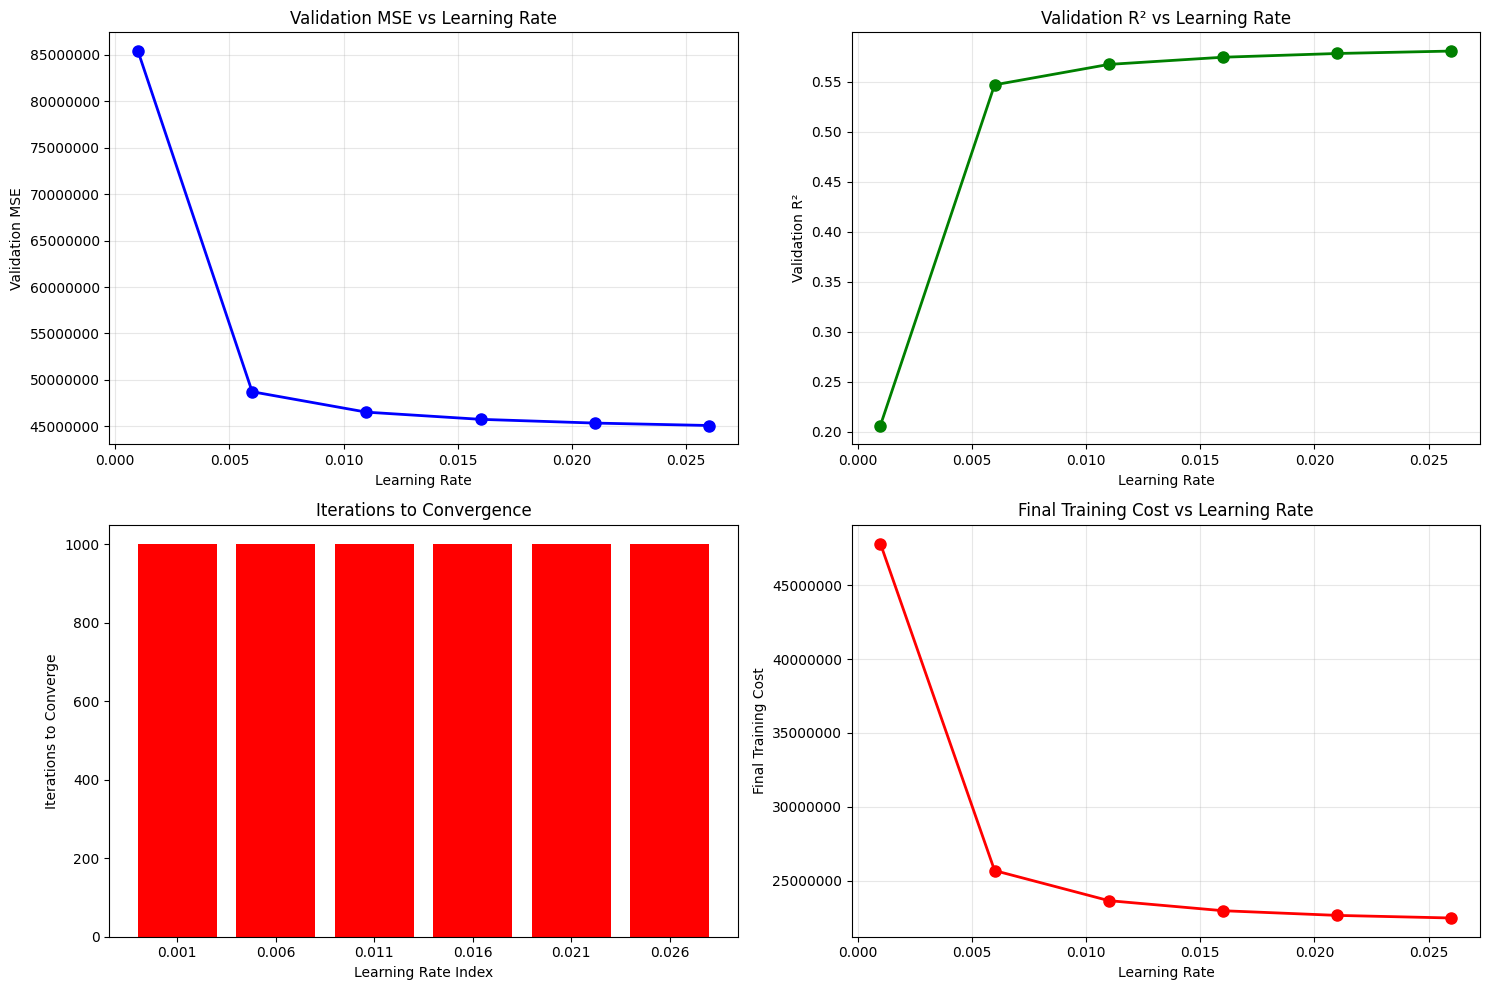


Optimal Learning Rate: 0.026000000000000002

STEP 2: CONVERGENCE ANALYSIS WITH OPTIMAL LEARNING RATE
Training model with learning rate: 0.026000000000000002
Iteration 0: Cost = 132599810.459690
Iteration 100: Cost = 31961199.314424
Iteration 200: Cost = 26391375.144502
Iteration 300: Cost = 24608909.666695
Iteration 400: Cost = 23778713.293600
Iteration 500: Cost = 23304625.102710
Iteration 600: Cost = 23005622.563785
Iteration 700: Cost = 22805012.794549
Iteration 800: Cost = 22663465.059508
Iteration 900: Cost = 22558981.602123
Iteration 1000: Cost = 22478707.878008
Iteration 1100: Cost = 22414898.164714
Iteration 1200: Cost = 22362749.179848
Iteration 1300: Cost = 22319189.327163
Iteration 1400: Cost = 22282186.829872
Iteration 1500: Cost = 22250348.025729
Iteration 1600: Cost = 22222680.753141
Iteration 1700: Cost = 22198452.847012
Iteration 1800: Cost = 22177106.024913
Iteration 1900: Cost = 22158202.385203
Training completed. Final cost: 22141549.096107


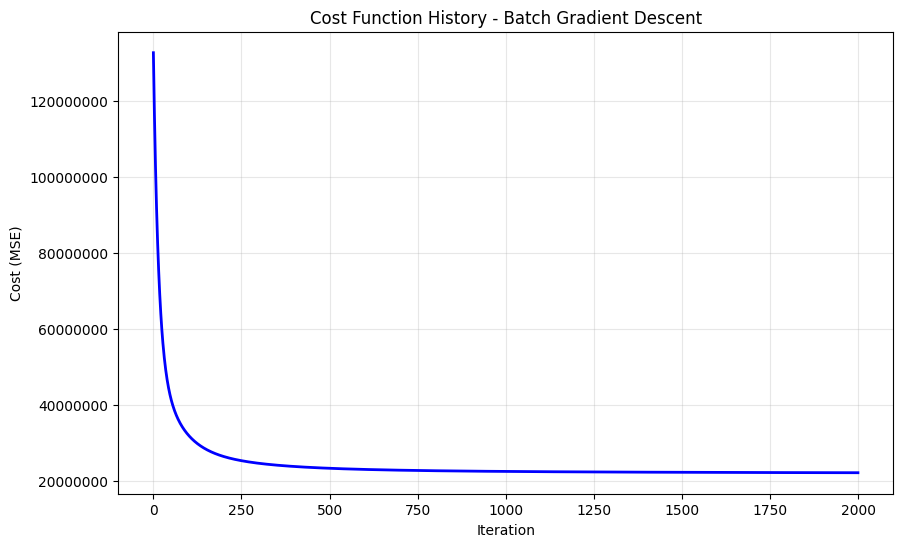


Convergence Analysis:
Initial Cost: 132599810.459690
Final Cost: 22141549.096107
Cost Reduction: 110458261.363584
Iterations Used: 2000
Convergence Ratio: 83.30%

STEP 3: FINAL EVALUATION ON TEST SET

FINAL MODEL PERFORMANCE:
R² Score: 0.6875
MSE: 42017223.9344
RMSE: 6482.0694
MAE: 4944.2005
Optimal Learning Rate: 0.026000000000000002
Final Iterations: 2000


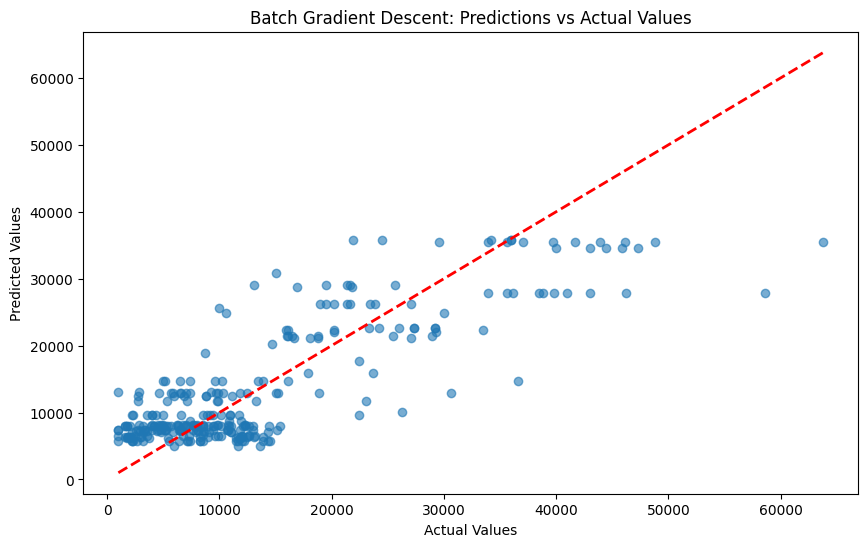

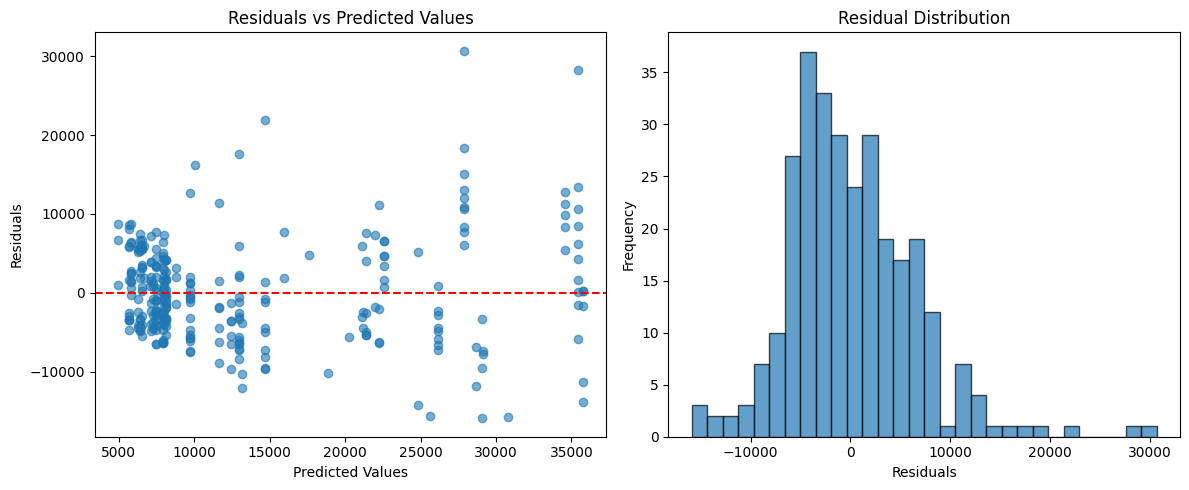

(<__main__.BatchGradientDescentLinearRegression at 0x24a36f2d3a0>,
 {'mse': 42017223.9343814,
  'rmse': 6482.06941758428,
  'mae': 4944.200524912591,
  'r2': 0.6875381727862051},
 0.026000000000000002)

In [230]:
run_batch_gradient_descent_regression(df_female_reduced_woi, target ,learning_rates=np.arange(0.001, 0.027, 0.005).tolist())

# 